In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, PoissonRegressor
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report,
                             mean_absolute_error, mean_poisson_deviance, f1_score)
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import log_loss
from scipy.stats import poisson, skellam
import pymc as pm
import arviz as az

# Data Preprocessing and Cleaning

In [2]:
#fix dates
old_files = {
    "Premier League 09-10.csv": "Premier League 2009-10.csv",
    "Premier League 10-11.csv": "Premier League 2010-11.csv",
    "Premier League 11-12.csv": "Premier League 2011-12.csv",
    "Premier League 12-13.csv": "Premier League 2012-13.csv",
    "Premier League 13-14.csv": "Premier League 2013-14.csv",
    "Premier League 14-15.csv": "Premier League 2014-15.csv",
    "Premier League 15-16.csv": "Premier League 2015-16.csv",
    "Premier League 16-17.csv": "Premier League 2016-17.csv",
}

for old_file, new_file in old_files.items():

  df = pd.read_csv(old_file)

  df["Date"] = pd.to_datetime(
      df["Date"],
      format = "mixed",
      dayfirst = True,
      errors = "coerce"
  )

  df["Date"] = df["Date"].dt.strftime('%d/%m/%Y')

  df.to_csv(new_file, index=False)

In [3]:
#Files and season label
files = {
    "2009/10": "Premier League 2009-10.csv",
    "2010/11": "Premier League 2010-11.csv",
    "2011/12": "Premier League 2011-12.csv",
    "2012/13": "Premier League 2012-13.csv",
    "2013/14": "Premier League 2013-14.csv",
    "2014/15": "Premier League 2014-15.csv",
    "2015/16": "Premier League 2015-16.csv",
    "2016/17": "Premier League 2016-17.csv",
    "2017/18": "Premier League 2017-18.csv",
    "2018/19": "Premier League 2018-19.csv",
    "2019/20": "Premier League 2019-20.csv",
    "2020/21": "Premier League 2020-21.csv",
    "2021/22": "Premier League 2021-22.csv",
    "2022/23": "Premier League 2022-23.csv",
    "2023/24": "Premier League 2023-24.csv",
    "2024/25": "Premier League 2024-25.csv",
    "2025/26": "Premier League 2025-26.csv",
}

keep_cols = [
    "Season",
    "Div",
    "Date",
    "HomeTeam",
    "AwayTeam",
    "FTHG",
    "FTAG",
    "FTR",
    "HST",
    "AST",
]

all_seasons = []

for season, path in files.items():
  df = pd.read_csv(path)

  df["Season"] = season

  df = df[keep_cols]

  all_seasons.append(df)


premier_league = pd.concat(all_seasons, ignore_index=True)


premier_league["Date"] = pd.to_datetime(
    premier_league["Date"],
    dayfirst = True,
    format = '%d/%m/%Y',
    errors = 'coerce'
)


In [4]:
#For missing values
premier_league.isnull().sum()

important_cols = [
    "Date", "HomeTeam", "AwayTeam",
    "FTHG", "FTAG", "FTR",
    "HST", "AST"
]

premier_league[important_cols].isnull().sum()

,0
Date,0
HomeTeam,0
AwayTeam,0
FTHG,0
FTAG,0
FTR,0
HST,0
AST,0


In [5]:
#Save the cleaned dataset
premier_league.to_csv("Premier League 2009-2026.csv", index=False)

In [6]:
# Check final dataset size
print(premier_league.shape)
print(premier_league.columns)
print(premier_league.dtypes)
premier_league.head()



(6460, 10)
Index(['Season', 'Div', 'Date', 'HomeTeam', 'AwayTeam', 'FTHG', 'FTAG', 'FTR',
       'HST', 'AST'],
      dtype='object')
Season              object
Div                 object
Date        datetime64[ns]
HomeTeam            object
AwayTeam            object
FTHG                 int64
FTAG                 int64
FTR                 object
HST                  int64
AST                  int64
dtype: object


,Season,Div,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HST,AST
0,2009/10,E0,2009-08-15,Aston Villa,Wigan,0,2,A,5,7
1,2009/10,E0,2009-08-15,Blackburn,Man City,0,2,A,9,5
2,2009/10,E0,2009-08-15,Bolton,Sunderland,0,1,A,3,13
3,2009/10,E0,2009-08-15,Chelsea,Hull,2,1,H,12,3
4,2009/10,E0,2009-08-15,Everton,Arsenal,1,6,A,5,9


In [7]:
#data used for EDA and model development

development_data = premier_league[
    premier_league["Season"] != "2025/26"
].copy()

print("Development seasons:", development_data["Season"].min(),
      "to", development_data["Season"].max())
print("Development data shape:", development_data.shape)

Development seasons: 2009/10 to 2024/25
Development data shape: (6080, 10)


# Exploratory Data Analysis

In [8]:
#Check matches per season
development_data["Season"].value_counts().sort_index()

,count
Season,
2009/10,380
2010/11,380
2011/12,380
2012/13,380
2013/14,380
2014/15,380
2015/16,380
2016/17,380
2017/18,380


In [9]:
#Distribution of match results
development_data["FTR"].value_counts()

,count
FTR,
H,2751
A,1864
D,1465


In [10]:
#Percentage Distribution
development_data["FTR"].value_counts(normalize=True) * 100

,proportion
FTR,
H,45.246711
A,30.657895
D,24.095395


In [11]:
#Total Goals columns
development_data["TotalGoals"] = (development_data["FTHG"]
                                  + development_data["FTAG"])
development_data["HomeGoalDiff"] = (development_data["FTHG"]
                                    - development_data["FTAG"])
development_data["AwayGoalDiff"] = (development_data["FTAG"]
                                    - development_data["FTHG"])

development_data["HomeWin"] = (development_data["FTR"] == "H").astype(int)
development_data["AwayWin"] = (development_data["FTR"] =="A").astype(int)
development_data["Draw"] = (development_data["FTR"] == "D").astype(int)


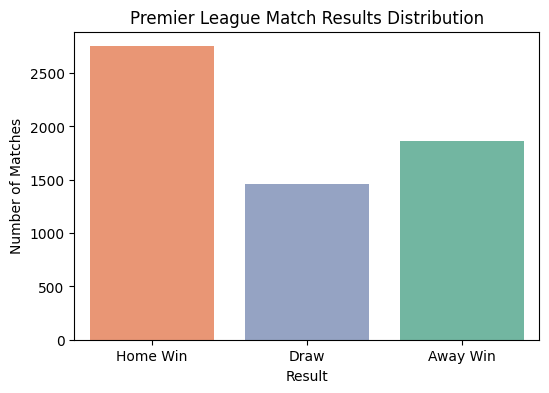

In [12]:
plt.figure(figsize=(6,4))

sns.countplot(
    x="FTR",
    data = development_data,
    hue = "FTR",
    palette="Set2",
    order=["H", "D", "A"]
)

plt.title("Premier League Match Results Distribution")
plt.xlabel("Result")
plt.ylabel("Number of Matches")
plt.xticks(
    ticks=[0, 1, 2],
    labels=["Home Win", "Draw", "Away Win"],
    rotation=0
)

plt.show()

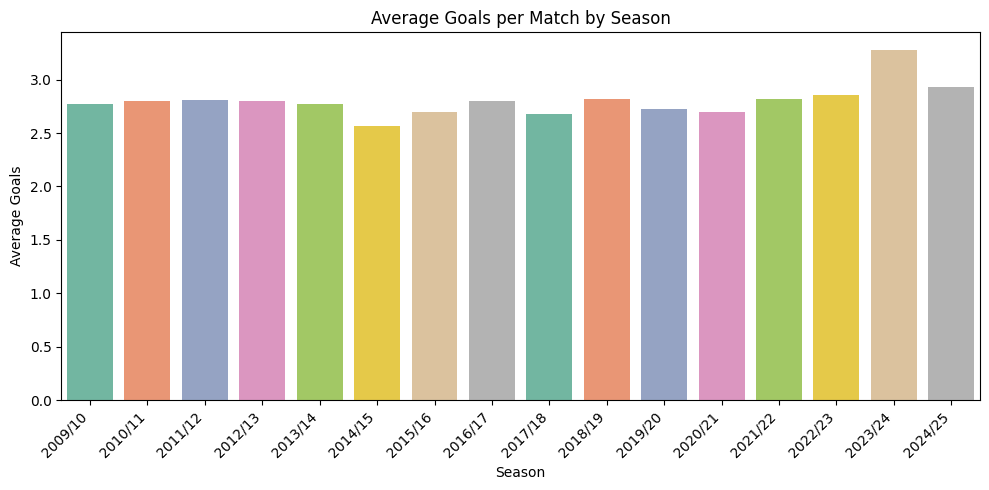

In [13]:
#Average goals per season
plt.figure(figsize = (10,5))

sns.barplot(
    x=  "Season",
    y = "TotalGoals",
    data = development_data,
    estimator = "mean",
    errorbar = None,
    hue = "Season",
    palette = "Set2",
    legend = False
)

plt.title("Average Goals per Match by Season")
plt.xlabel("Season")
plt.ylabel("Average Goals")
plt.xticks(rotation=45, ha = "right")
plt.tight_layout()
plt.show()

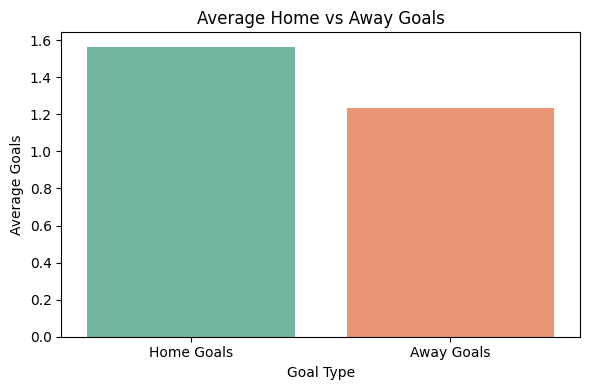

In [14]:
#Average Home vs Away goals

goalavgs = development_data[["FTHG", "FTAG"]].mean().reset_index()

goalavgs.columns = ["Goal Type", "Average Goals"]

plt.figure(figsize = (6,4))

sns.barplot(
    x = "Goal Type",
    y = "Average Goals",
    data = goalavgs,
    hue = "Goal Type",
    palette = "Set2",
    legend = False
)

plt.title("Average Home vs Away Goals")
plt.xlabel("Goal Type")
plt.ylabel("Average Goals")
plt.xticks(
    ticks = [0, 1],
    labels = ["Home Goals", "Away Goals"],
    rotation=0
    )
plt.tight_layout()
plt.show()

In [15]:
#Home advantage by season

home_advantage = development_data.groupby("Season")[["HomeWin", "Draw", "AwayWin"]].mean() * 100

home_advantage

,HomeWin,Draw,AwayWin
Season,,,
2009/10,50.789474,25.263158,23.947368
2010/11,47.105263,29.210526,23.684211
2011/12,45.000000,24.473684,30.526316
2012/13,43.684211,28.421053,27.894737
2013/14,47.105263,20.526316,32.368421
2014/15,45.263158,24.473684,30.263158
2015/16,41.315789,28.157895,30.526316
2016/17,49.210526,22.105263,28.684211
2017/18,45.526316,26.052632,28.421053


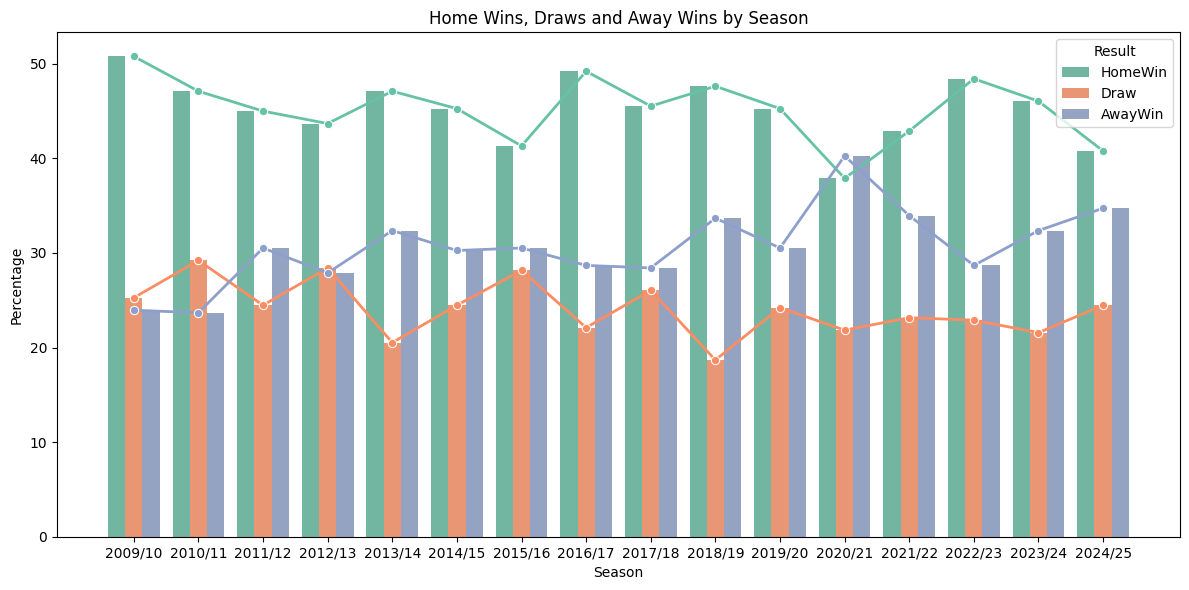

In [264]:
#Plot of home wins, draws and away wins

home_advantage_plot = home_advantage.reset_index()

home_advantage_plot = home_advantage_plot.melt(
    id_vars = "Season",
    value_vars = ["HomeWin", "Draw", "AwayWin"],
    var_name = "Result",
    value_name = "Percentage"
)

plt.figure(figsize = (12, 6))
sns.barplot(
    x = "Season",
    y = "Percentage",
    hue = "Result",
    data = home_advantage_plot,
    palette = "Set2"
)
sns.lineplot(
    x = "Season",
    y = "Percentage",
    hue = "Result",
    data = home_advantage_plot,
    palette = "Set2",
    marker = "o",
    linewidth = 2,
    legend = False
)

plt.title("Home Wins, Draws and Away Wins by Season")
plt.xlabel("Season")
plt.ylabel("Percentage")
plt.tight_layout()
plt.show()

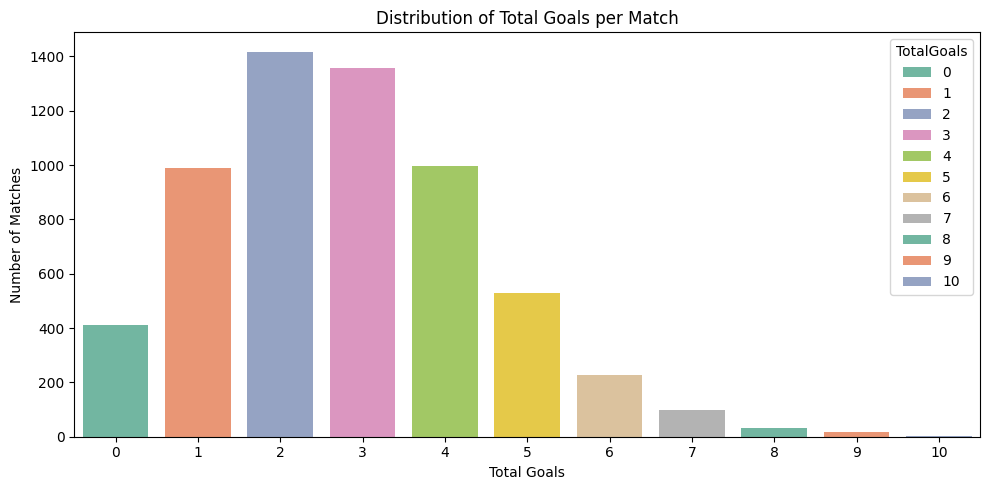

In [17]:
#Distribution of goals per match

plt.figure(figsize = (10, 5))
sns.countplot(
    x = "TotalGoals",
    data = development_data,
    hue = "TotalGoals",
    palette = "Set2"
)

plt.title("Distribution of Total Goals per Match")
plt.xlabel("Total Goals")
plt.ylabel("Number of Matches")
plt.tight_layout()
plt.show()

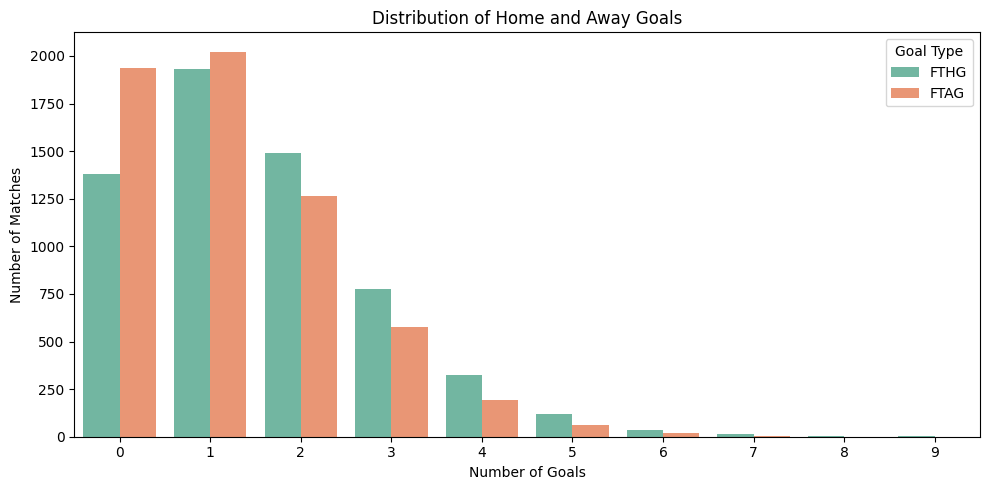

In [18]:
#Distribution by Home and Away goals

goals_dist = development_data[["FTHG", "FTAG"]].melt(
    var_name = "Goal Type",
    value_name = "Goals"
)

plt.figure(figsize = (10,5))
sns.countplot(
    x = "Goals",
    hue = "Goal Type",
    data = goals_dist,
    palette = "Set2"
)

plt.title("Distribution of Home and Away Goals")
plt.xlabel("Number of Goals")
plt.ylabel("Number of Matches")
plt.tight_layout()
plt.show()

In [19]:
#Most common scorelines

development_data["Scoreline"] = (
    development_data["FTHG"].astype(str) + "-"
    + development_data["FTAG"].astype(str)
)

common_scorelines = development_data["Scoreline"].value_counts().head(10)
common_scorelines

,count
Scoreline,
1-1,650
1-0,577
2-1,511
2-0,473
1-2,418
0-0,413
0-1,411
2-2,333
0-2,295


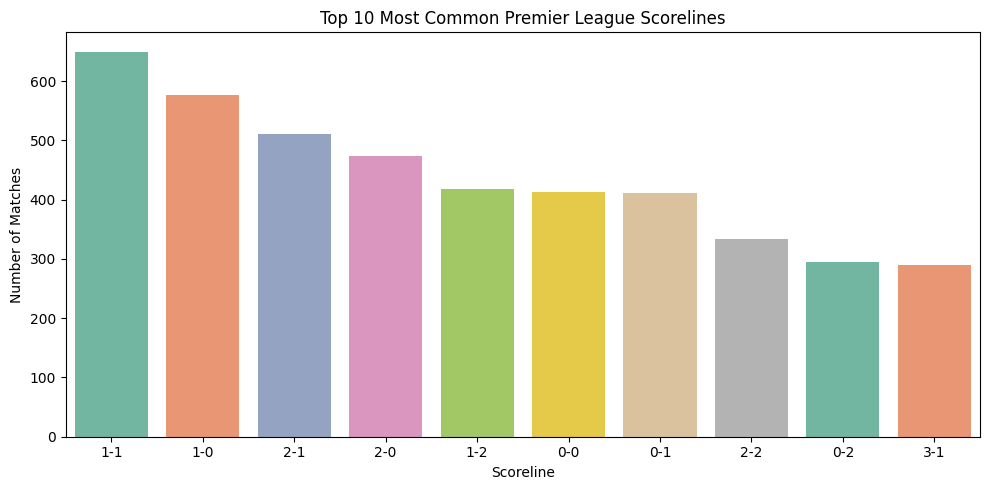

In [20]:
#Plot of common scorelines

plt.figure(figsize = (10, 5))
sns.barplot(
    x = common_scorelines.index,
    y = common_scorelines.values,
    hue = common_scorelines.index,
    palette = "Set2"
)

plt.title("Top 10 Most Common Premier League Scorelines")
plt.xlabel("Scoreline")
plt.ylabel("Number of Matches")
plt.tight_layout()
plt.show()

In [21]:
#Average goals by results
goals_by_result = development_data.groupby("FTR")[
    ["FTHG", "FTAG", "TotalGoals"]].mean()

goals_by_result

,FTHG,FTAG,TotalGoals
FTR,,,
A,0.593884,2.385193,2.979077
D,1.045051,1.045051,2.090102
H,2.499091,0.558342,3.057434


In [22]:
#Correlation between shots and goals

shots_goals_corr = development_data[
    ["FTHG", "FTAG", "HST", "AST"]
].corr()

shots_goals_corr

,FTHG,FTAG,HST,AST
FTHG,1.000000,-0.110925,0.485229,-0.124167
FTAG,-0.110925,1.000000,-0.131963,0.489785
HST,0.485229,-0.131963,1.000000,-0.040218
AST,-0.124167,0.489785,-0.040218,1.000000


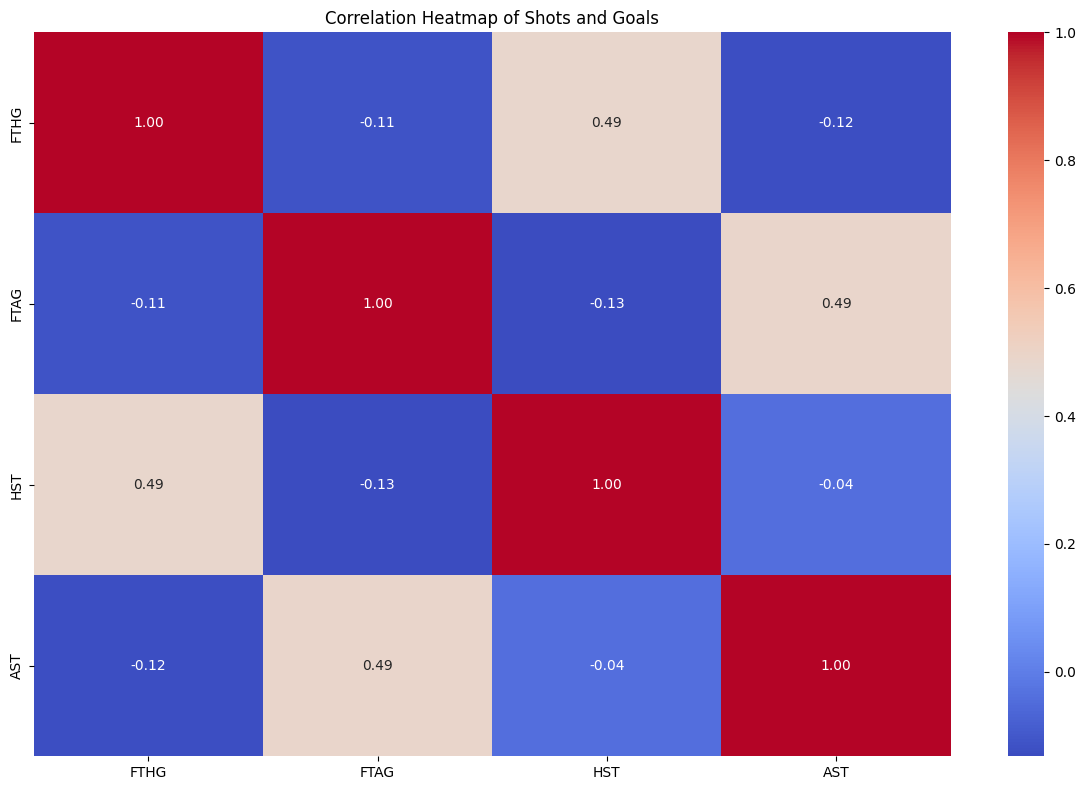

In [23]:
#Correlation heatmap

plt.figure(figsize = (12, 8))
sns.heatmap(
    shots_goals_corr,
    annot = True,
    cmap = "coolwarm",
    fmt = ".2f"
)

plt.title("Correlation Heatmap of Shots and Goals")
plt.tight_layout()
plt.show()

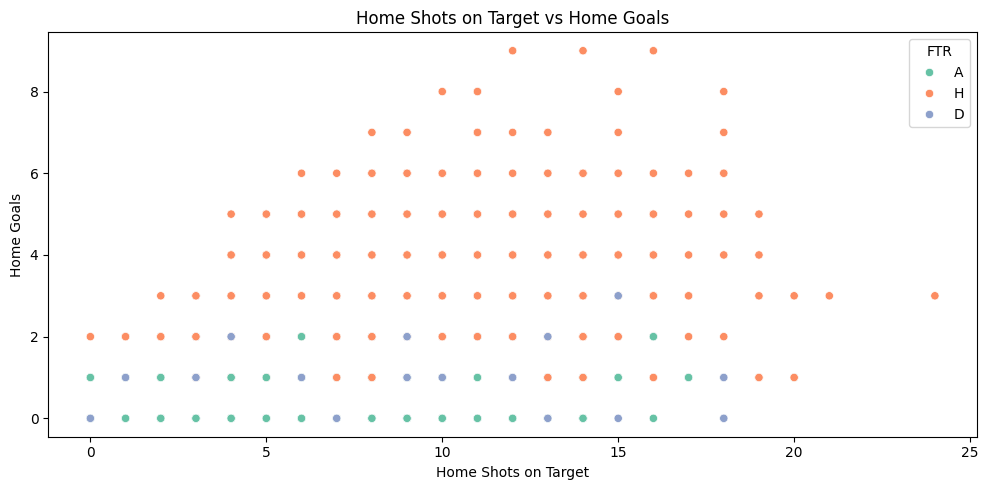

In [24]:
#Scatter for shots on target vs goal (Home)

plt.figure(figsize = (10, 5))
sns.scatterplot(
    x = "HST",
    y = "FTHG",
    data = development_data,
    hue = "FTR",
    palette = "Set2"
)

plt.title("Home Shots on Target vs Home Goals")
plt.xlabel("Home Shots on Target")
plt.ylabel("Home Goals")
plt.tight_layout()
plt.show()

In [25]:
#Scatter plot explanation for 0 Shots on Target and more than 0 goals (Home)
development_data[
    (development_data["HST"] == 0) & (development_data["FTHG"] > 0)
][[
    "Season", "Date", "HomeTeam", "AwayTeam",
    "FTHG", "FTAG", "FTR", "HST"
]]

,Season,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HST
839,2011/12,2011-10-22,Aston Villa,West Brom,1,2,A,0
2755,2016/17,2016-10-29,Watford,Hull,1,0,H,0
2934,2016/17,2017-03-18,Crystal Palace,Watford,1,0,H,0
3168,2017/18,2017-11-26,Huddersfield,Man City,1,2,A,0
3631,2018/19,2019-01-12,Burnley,Fulham,2,1,H,0
4111,2019/20,2020-06-28,Watford,Southampton,1,3,A,0


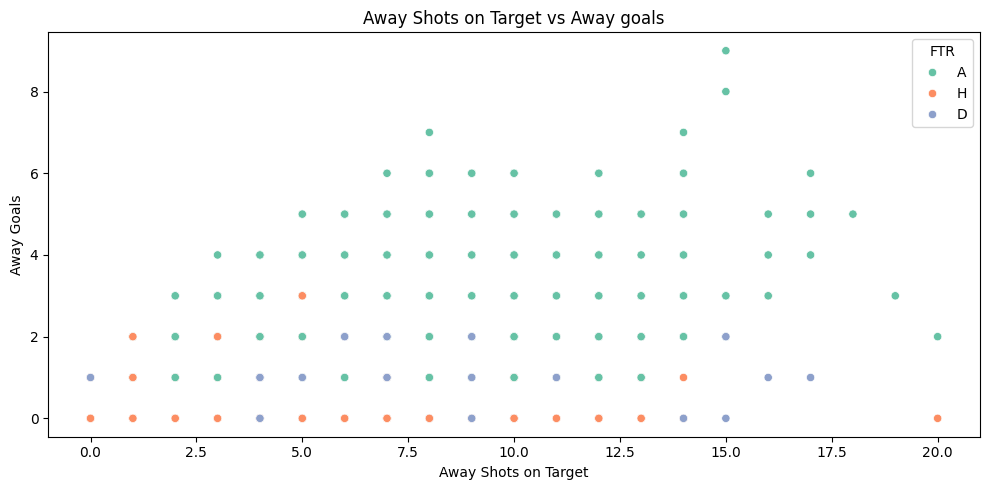

In [26]:
#Scatter for shots on target vs goal (Away)

plt.figure(figsize = (10, 5))
sns.scatterplot(
    x = "AST",
    y = "FTAG",
    data = development_data,
    hue = "FTR",
    palette = "Set2"
)

plt.title("Away Shots on Target vs Away goals")
plt.xlabel("Away Shots on Target")
plt.ylabel("Away Goals")
plt.tight_layout()
plt.show()

In [27]:
#Scatter plot explanation for 0 Shots on Target and more than 0 goals (Away)

development_data[
    (development_data["AST"] == 0) & (development_data["FTAG"] > 0)
][[
    "Season", "Date", "HomeTeam", "AwayTeam",
    "FTHG", "FTAG", "FTR", "AST"
]]

,Season,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,AST
2659,2015/16,2016-05-17,Man United,Bournemouth,3,1,H,0
2701,2016/17,2016-09-17,Everton,Middlesbrough,3,1,H,0
5822,2024/25,2024-11-30,Crystal Palace,Newcastle,1,1,D,0


In [28]:
#Average shots taken by match result

shots_by_result = development_data.groupby("FTR")[["HST", "AST"]].mean()

shots_by_result

,HST,AST
FTR,,
A,4.193133,5.872854
D,5.073038,4.422526
H,6.765176,3.673937


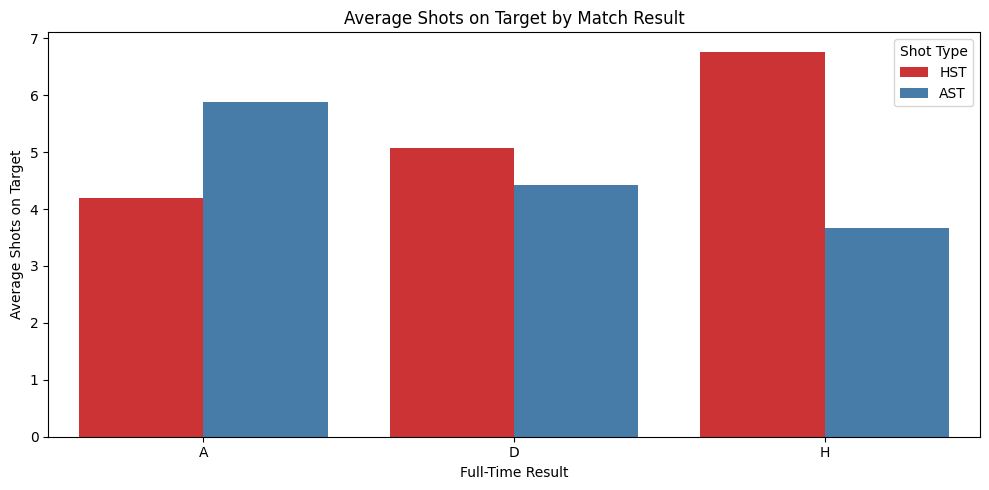

In [29]:
#Barplot for average shots taken by match result

shots_result_plot = shots_by_result[["HST", "AST"]].reset_index()

shots_result_plot = shots_result_plot.melt(
    id_vars = "FTR",
    value_vars = ["HST", "AST"],
    var_name = "Shot Type",
    value_name = "Average Shots on Target"
)

plt.figure(figsize = (10, 5))
sns.barplot(
    x = "FTR",
    y = "Average Shots on Target",
    hue = "Shot Type",
    data = shots_result_plot,
    palette = "Set1"
)

plt.title("Average Shots on Target by Match Result")
plt.xlabel("Full-Time Result")
plt.ylabel("Average Shots on Target")
plt.tight_layout()
plt.show()

In [30]:
#Correlation Analysis of Match statistics

corr_cols = [
    "FTHG", "FTAG", "TotalGoals","HST", "AST",
   "HomeWin", "Draw", "AwayWin"
]

corr_matrix = development_data[corr_cols].corr()

corr_matrix

,FTHG,FTAG,TotalGoals,HST,AST,HomeWin,Draw,AwayWin
FTHG,1.000000,-0.110925,0.710657,0.485229,-0.124167,0.640495,-0.220730,-0.486689
FTAG,-0.110925,1.000000,0.620368,-0.131963,0.489785,-0.517572,-0.090285,0.642469
TotalGoals,0.710657,0.620368,1.000000,0.289517,0.248732,0.139074,-0.238109,0.070723
HST,0.485229,-0.131963,0.289517,1.000000,-0.040218,0.338746,-0.087030,-0.284959
AST,-0.124167,0.489785,0.248732,-0.040218,1.000000,-0.283631,-0.021792,0.326397
HomeWin,0.640495,-0.517572,0.139074,0.338746,-0.283631,1.000000,-0.512179,-0.604451
Draw,-0.220730,-0.090285,-0.238109,-0.087030,-0.021792,-0.512179,1.000000,-0.374633
AwayWin,-0.486689,0.642469,0.070723,-0.284959,0.326397,-0.604451,-0.374633,1.000000


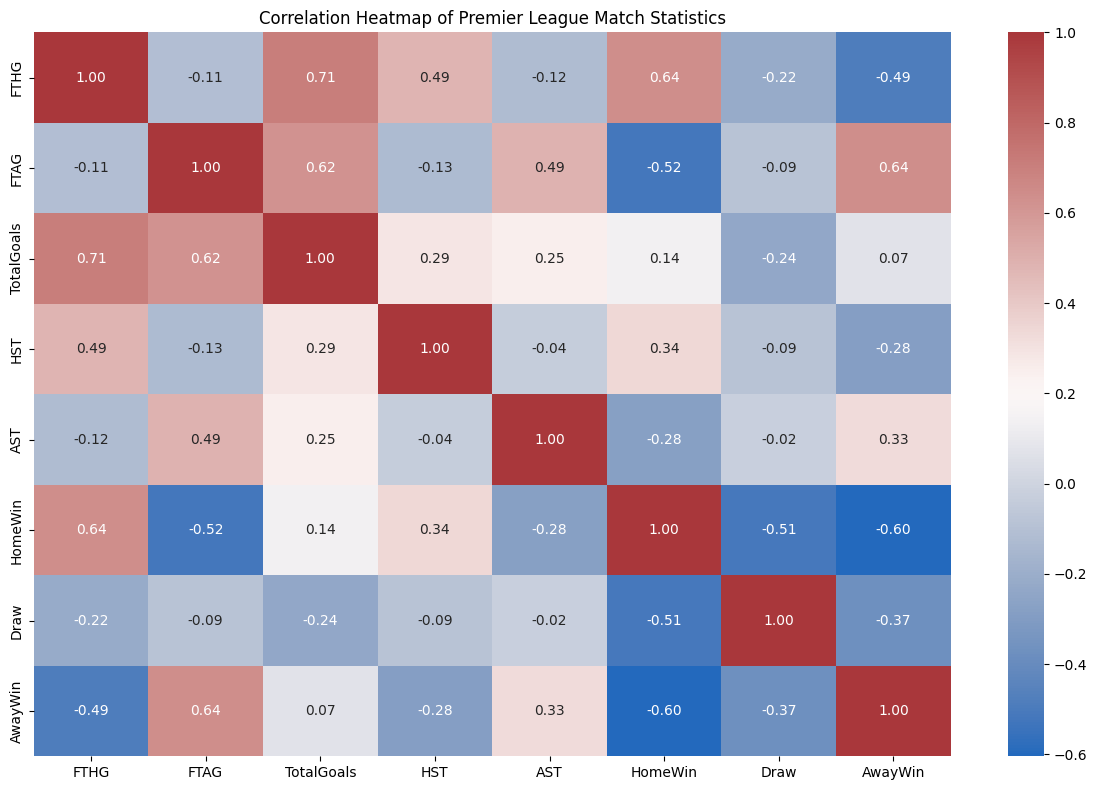

In [31]:
#Correlation Heatmap
plt.figure(figsize = (12, 8))
sns.heatmap(
    corr_matrix,
    annot = True,
    cmap = "vlag",
    fmt = ".2f"
)

plt.title("Correlation Heatmap of Premier League Match Statistics")
plt.tight_layout()
plt.show()

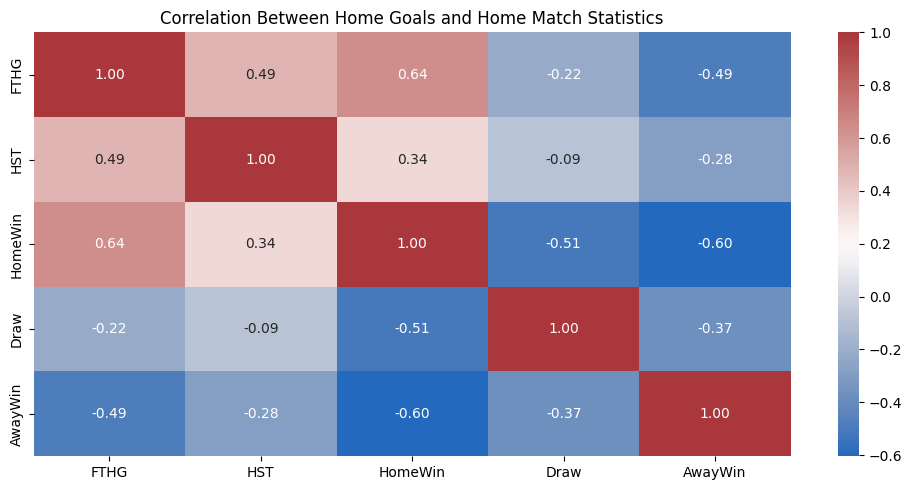

In [32]:
#Smaller correlation for Home Statistics

home_goal_corr = development_data[
    ["FTHG", "HST", "HomeWin","Draw", "AwayWin"]
].corr()

plt.figure(figsize=(10, 5))

sns.heatmap(
    home_goal_corr,
    annot=True,
    cmap="vlag",
    fmt=".2f"
)

plt.title("Correlation Between Home Goals and Home Match Statistics")
plt.tight_layout()
plt.show()

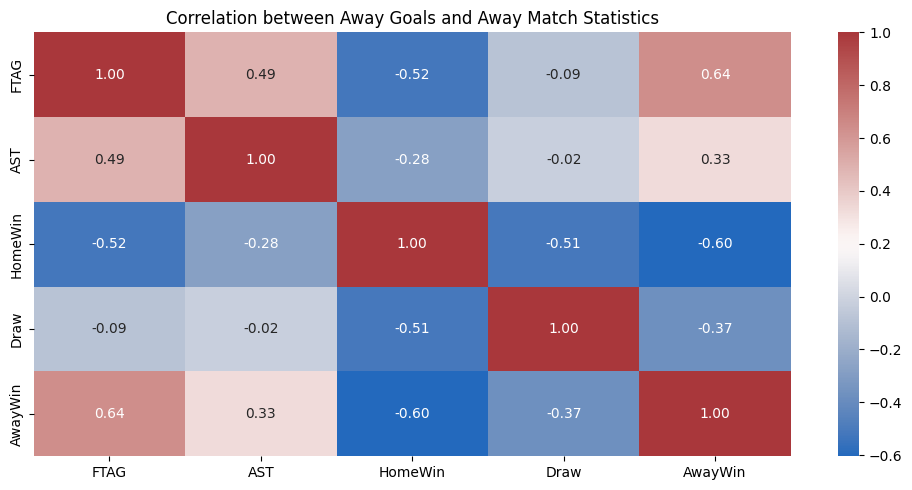

In [33]:
#Smaller correlation for Away Statistics

away_goal_corr = development_data[
    ["FTAG", "AST", "HomeWin", "Draw", "AwayWin"]
].corr()

plt.figure(figsize = (10 , 5))
sns.heatmap(
    away_goal_corr,
    annot = True,
    cmap = "vlag",
    fmt = ".2f"
)

plt.title("Correlation between Away Goals and Away Match Statistics")
plt.tight_layout()
plt.show()

# Team Performance Analysis

In [34]:
#Goals scored by each team

home_goals = development_data.groupby("HomeTeam")["FTHG"].sum()

away_goals = development_data.groupby("AwayTeam")["FTAG"].sum()

team_goals_scored = home_goals.add(away_goals, fill_value = 0).sort_values(ascending = False)

team_goals_scored.head(5)

,0
HomeTeam,
Man City,1375
Liverpool,1199
Arsenal,1149
Chelsea,1107
Tottenham,1069


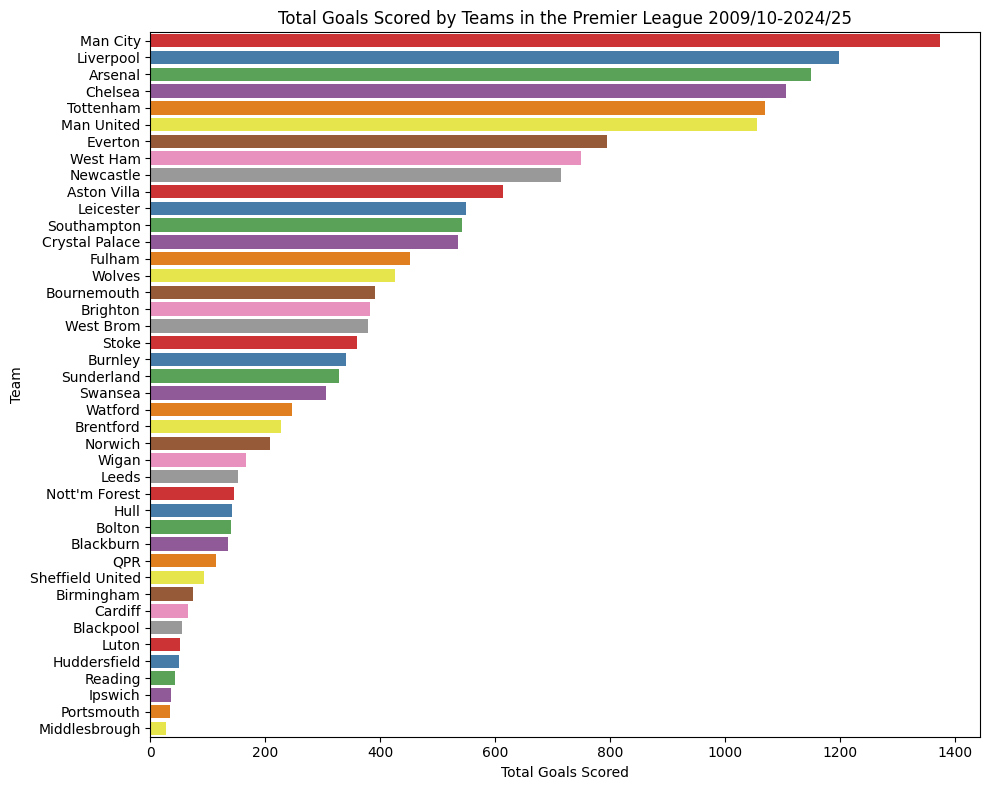

In [35]:
#plot

plt.figure(figsize = (10, 8))
sns.barplot(
    x = team_goals_scored.values,
    y = team_goals_scored.index,
    hue = team_goals_scored.index,
    palette = "Set1"
)

plt.title(
    "Total Goals Scored by Teams in the Premier League 2009/10-2024/25")
plt.xlabel("Total Goals Scored")
plt.ylabel("Team")
plt.tight_layout()
plt.show()

In [36]:
#Goals conceded by each team

home_goals_conceded = development_data.groupby("HomeTeam")["FTAG"].sum()

away_goals_conceded = development_data.groupby("AwayTeam")["FTHG"].sum()

team_goals_conceded = home_goals_conceded.add(away_goals_conceded, fill_value = 0).sort_values(ascending = False)

team_goals_conceded.head(5)

,0
HomeTeam,
West Ham,876
Everton,788
Newcastle,782
Aston Villa,739
Tottenham,735


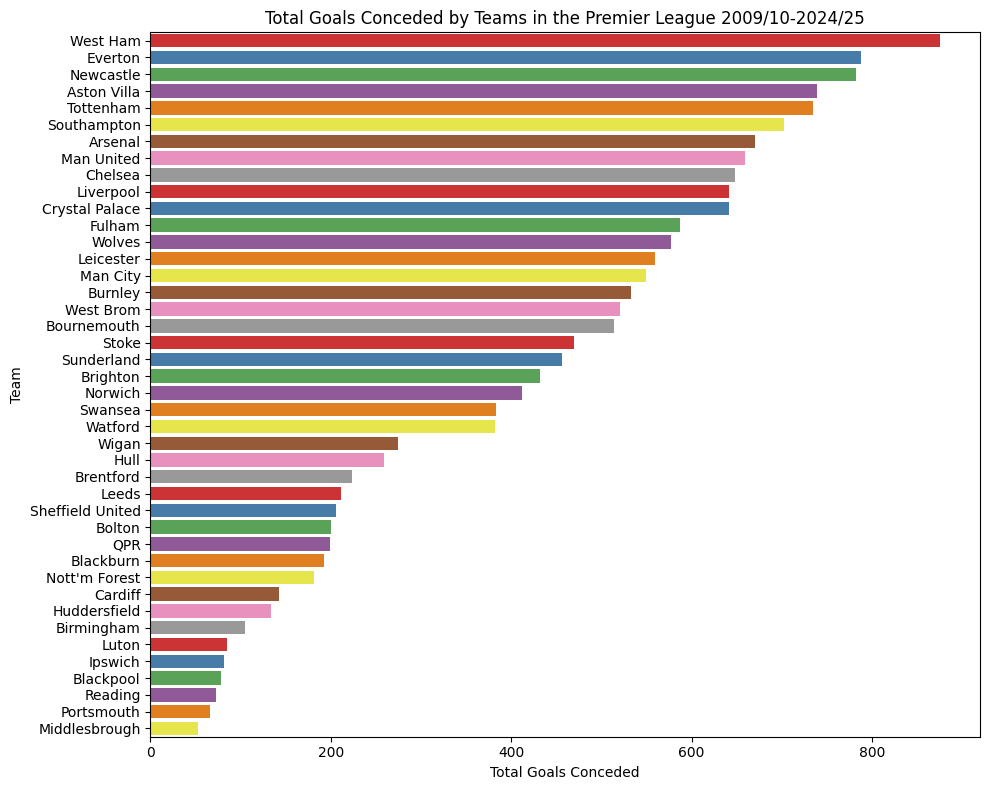

In [37]:
#plot

plt.figure(figsize = (10, 8))
sns.barplot(
    x = team_goals_conceded.values,
    y = team_goals_conceded.index,
    hue = team_goals_conceded.index,
    palette = "Set1"
)

plt.title(
    "Total Goals Conceded by Teams in the Premier League 2009/10-2024/25")
plt.xlabel("Total Goals Conceded")
plt.ylabel("Team")
plt.tight_layout()
plt.show()

In [38]:
#Goal difference

team_goal_difference = team_goals_scored - team_goals_conceded

team_goal_difference = team_goal_difference.sort_values(ascending = False)

team_goal_difference.head(5)

,0
HomeTeam,
Man City,825
Liverpool,557
Arsenal,479
Chelsea,459
Man United,397


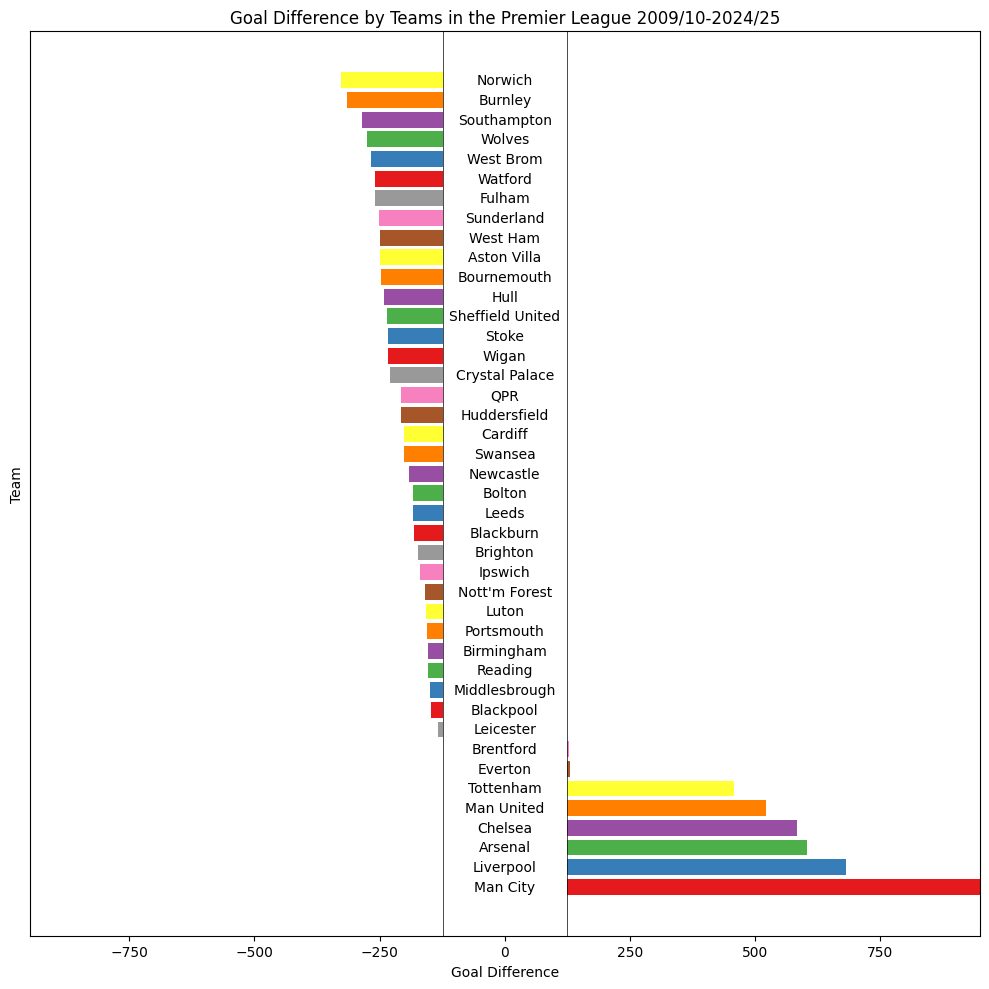

In [39]:
#plot

plt.figure(figsize = (10, 10))

max_value = abs(team_goal_difference).max()

gap = max_value * 0.15

colors = sns.color_palette("Set1", len(team_goal_difference))

for i, value in enumerate(team_goal_difference):
  if value >=0:
    plt.barh(
        i,
        value,
        left = gap,
        color = colors[i]
    )

  else:
    plt.barh(
        i,
        value,
        left = -gap,
        color = colors[i]
    )

for i, team in enumerate(team_goal_difference.index):
  plt.text(
      0,
      i,
      team,
      ha = "center",
      va = "center",
      fontsize = 10,
      bbox = dict(facecolor = "white", edgecolor = "none", alpha = 0.8)
  )

plt.axvline(-gap, color ="black", linewidth = 0.5)
plt.axvline(gap ,color = "black", linewidth = 0.5)

plt.yticks([])
plt.xlim(-(max_value + gap),max_value + gap)

plt.title(
    "Goal Difference by Teams in the Premier League 2009/10-2024/25")
plt.xlabel("Goal Difference")
plt.ylabel("Team")
plt.tight_layout()
plt.show()

# Building the Premier League Tables

In [40]:
#Function to build the league table

def build_league_table(season_data):

  teams = sorted(set(season_data["HomeTeam"]).union(set(season_data["AwayTeam"])))

  table = pd.DataFrame(index = teams)

  table["Played"] = 0
  table["Wins"] = 0
  table["Draws"] = 0
  table["Losses"] = 0
  table["GoalsFor"] = 0
  table["GoalsAgainst"] = 0
  table["GoalDifference"] = 0
  table["Points"] = 0

  #process each match and update both teams
  for index, row in season_data.iterrows():

    home_team = row["HomeTeam"]
    away_team = row["AwayTeam"]
    home_goals = row["FTHG"]
    away_goals = row ["FTAG"]

    table.loc[home_team, "Played"] += 1
    table.loc[away_team, "Played"] += 1

    table.loc[home_team, "GoalsFor"] += home_goals
    table.loc[home_team, "GoalsAgainst"] += away_goals
    table.loc[away_team, "GoalsFor"] += away_goals
    table.loc[away_team, "GoalsAgainst"] += home_goals

    #award points and record outcome
    if home_goals > away_goals:
      table.loc[home_team, "Wins"] += 1
      table.loc[away_team, "Losses"] += 1
      table.loc[home_team, "Points"] += 3

    elif home_goals < away_goals:
      table.loc[away_team, "Wins"] +=1
      table.loc[home_team, "Losses"] += 1
      table.loc[away_team, "Points"] += 3

    else:
      table.loc[home_team, "Draws"] +=1
      table.loc[away_team, "Draws"] += 1
      table.loc[home_team, "Points"] += 1
      table.loc[away_team, "Points"] += 1

  table["GoalDifference"] = table["GoalsFor"] - table["GoalsAgainst"]

  table = table.sort_values(
      by = ["Points", "GoalDifference", "GoalsFor"],
      ascending = False
  )

  #assign final positions
  table["Position"] = range(1, len(table) + 1)

  table = table.reset_index()
  table = table.rename(columns = {"index": "Team"})

  table = table[
      [
          "Position", "Team", "Played", "Wins", "Draws", "Losses",
          "GoalsFor", "GoalsAgainst", "GoalDifference", "Points"
      ]
  ]

  return table

In [41]:
#All previous seasons
all_tables = []

for season in development_data["Season"].unique():

  season_data = development_data[
      development_data["Season"] == season]
  season_table = build_league_table(season_data)
  season_table["Season"] = season
  all_tables.append(season_table)

historical_tables = pd.concat(all_tables, ignore_index = True)
historical_tables.head()

,Position,Team,Played,Wins,Draws,Losses,GoalsFor,GoalsAgainst,GoalDifference,Points,Season
0,1,Chelsea,38,27,5,6,103,32,71,86,2009/10
1,2,Man United,38,27,4,7,86,28,58,85,2009/10
2,3,Arsenal,38,23,6,9,83,41,42,75,2009/10
3,4,Tottenham,38,21,7,10,67,41,26,70,2009/10
4,5,Man City,38,18,13,7,73,45,28,67,2009/10


In [42]:
#save the table
historical_tables.to_csv(
    "Premier League Historical Tables 2009-2025.csv",
    index = False)

# Analysis of Promoted Teams Performance

In [43]:
#Identify promoted Teams

season_order =[
    "2009/10", "2010/11", "2011/12", "2012/13", "2013/14",
    "2014/15", "2015/16", "2016/17", "2017/18", "2018/19",
    "2019/20", "2020/21", "2021/22", "2022/23", "2023/24",
    "2024/25", "2025/26"
]

promoted_list = []

for i in range(1, len(season_order)):

  current_season = season_order[i]
  previous_season = season_order[i - 1]

  current_teams = set(
      premier_league[premier_league["Season"] == current_season]["HomeTeam"].unique()
  )

  previous_teams = set(
      premier_league[premier_league["Season"] == previous_season]["HomeTeam"].unique()
  )

  promoted_teams = current_teams - previous_teams

  for team in promoted_teams:
    promoted_list.append({
        "Season": current_season,
        "Team": team
    })

promoted_teams_df = pd.DataFrame(promoted_list)

promoted_0910 = pd.DataFrame({
    "Season": ["2009/10", "2009/10", "2009/10"],
    "Team": ["Wolves", "Burnley", "Birmingham"]
})

promoted_teams_df = pd.concat(
    [promoted_0910, promoted_teams_df],
    ignore_index = True
)

promoted_teams_df

,Season,Team
0,2009/10,Wolves
1,2009/10,Burnley
2,2009/10,Birmingham
3,2010/11,Newcastle
4,2010/11,West Brom
5,2010/11,Blackpool
6,2011/12,QPR
7,2011/12,Norwich
8,2011/12,Swansea
9,2012/13,Reading


In [44]:
#Performance of promoted teams

historical_promoted_teams = promoted_teams_df[
    promoted_teams_df["Season"] != "2025/26"
]

promoted_performance = historical_promoted_teams.merge(
    historical_tables,
    on = ["Season", "Team"],
    how = "left"
)

promoted_performance["Survived"] = promoted_performance["Position"] <= 17
promoted_performance["Outcome"] = promoted_performance["Survived"].map({
    True: "Survived",
    False: "Relegated"
})

promoted_performance

,Season,Team,Position,Played,Wins,Draws,Losses,GoalsFor,GoalsAgainst,GoalDifference,Points,Survived,Outcome
0,2009/10,Wolves,15,38,9,11,18,32,56,-24,38,True,Survived
1,2009/10,Burnley,18,38,8,6,24,42,82,-40,30,False,Relegated
2,2009/10,Birmingham,9,38,13,11,14,38,47,-9,50,True,Survived
3,2010/11,Newcastle,12,38,11,13,14,56,57,-1,46,True,Survived
4,2010/11,West Brom,11,38,12,11,15,56,71,-15,47,True,Survived
5,2010/11,Blackpool,19,38,10,9,19,55,78,-23,39,False,Relegated
6,2011/12,QPR,17,38,10,7,21,43,66,-23,37,True,Survived
7,2011/12,Norwich,12,38,12,11,15,52,66,-14,47,True,Survived
8,2011/12,Swansea,11,38,12,11,15,44,51,-7,47,True,Survived
9,2012/13,Reading,19,38,6,10,22,43,73,-30,28,False,Relegated


In [45]:
#Survival rate of promoted teams

survival_counts = promoted_performance["Outcome"].value_counts()
survival_counts

,count
Outcome,
Survived,26
Relegated,22


In [46]:
#percentage

survival_rate = promoted_performance["Survived"].mean() * 100

print("Promoted teams survival rate:", round(survival_rate, 2), "%")

Promoted teams survival rate: 54.17 %


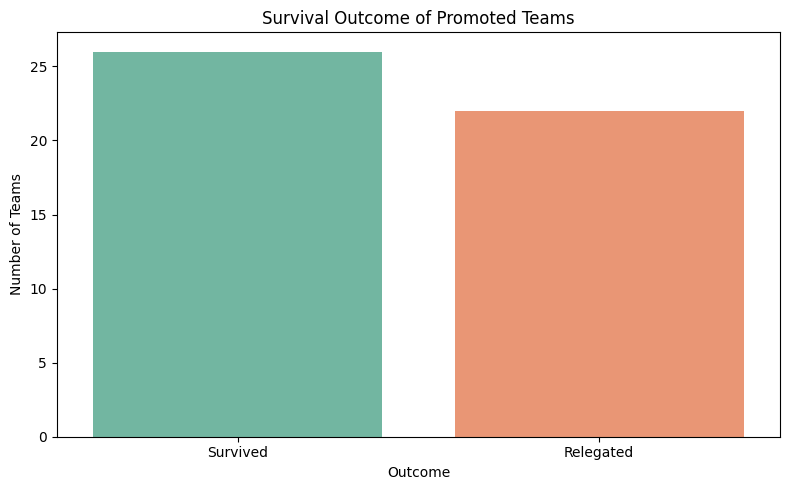

In [47]:
#plot

plt.figure(figsize =(8, 5))
sns.countplot(
    x = "Outcome",
    hue = "Outcome",
    data = promoted_performance,
    palette = "Set2"
)

plt.title("Survival Outcome of Promoted Teams")
plt.xlabel("Outcome")
plt.ylabel("Number of Teams")
plt.tight_layout()
plt.show()

In [48]:
#Average performance of promoted team

promoted_summary = promoted_performance[
    ["Points", "Position", "GoalsFor", "GoalsAgainst", "GoalDifference"]
].mean()
promoted_summary

,0
Points,36.270833
Position,15.666667
GoalsFor,39.687500
GoalsAgainst,65.229167
GoalDifference,-25.541667


In [49]:
#Performance by Outcome

promoted_performance.groupby("Outcome")[
    ["Points", "Position", "GoalsFor", "GoalsAgainst", "GoalDifference"]
].mean()

,Points,Position,GoalsFor,GoalsAgainst,GoalDifference
Outcome,,,,,
Relegated,26.863636,19.000000,35.500000,75.590909,-40.090909
Survived,44.230769,12.846154,43.230769,56.461538,-13.230769


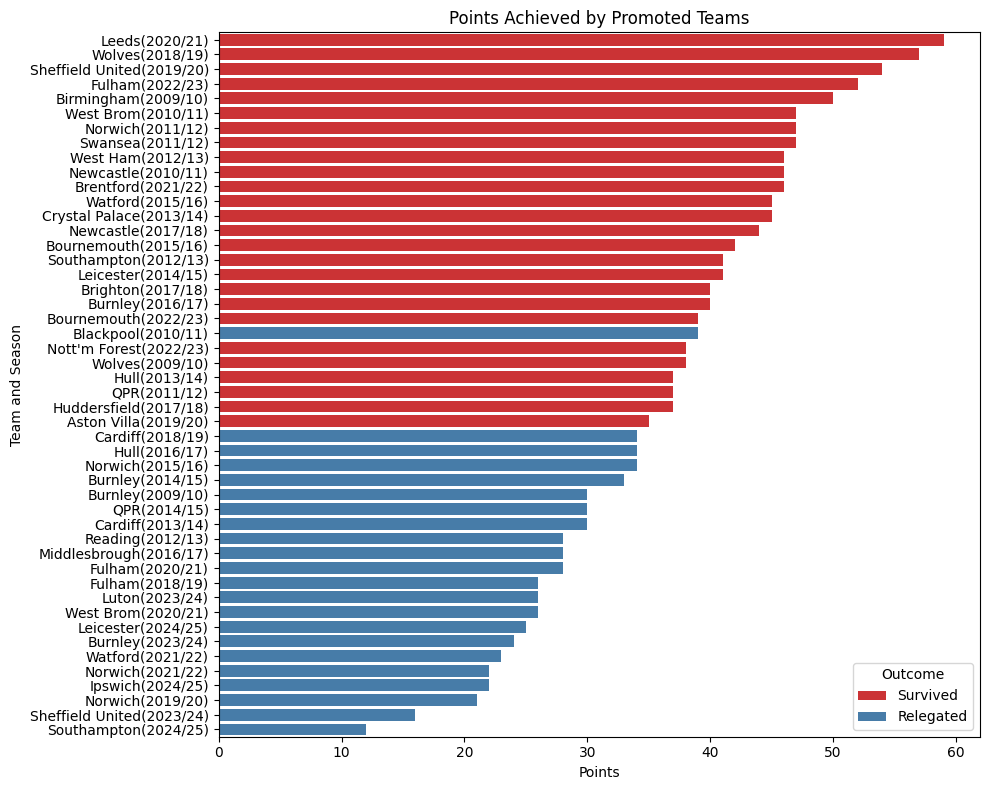

In [50]:
#plot

promoted_performance["TeamSeason"] =(
    promoted_performance["Team"] + "(" + promoted_performance["Season"] + ")"
)

promoted_points = promoted_performance.sort_values("Points", ascending = False)

plt.figure(figsize = (10,8))
sns.barplot(
    x = "Points",
    y = "TeamSeason",
    data = promoted_points,
    hue =  "Outcome",
    dodge = False,
    palette = "Set1"
)

plt.title("Points Achieved by Promoted Teams")
plt.xlabel("Points")
plt.ylabel("Team and Season")
plt.tight_layout()
plt.show()

# Feature Engineering for Match Prediction

In [51]:
# Prepare the dataset

model_data = premier_league.copy()

model_data["Date"] = pd.to_datetime(model_data["Date"], dayfirst = True, errors = "coerce")
model_data = model_data.sort_values("Date").reset_index(drop = True)

model_data.head()

,Season,Div,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HST,AST
0,2009/10,E0,2009-08-15,Aston Villa,Wigan,0,2,A,5,7
1,2009/10,E0,2009-08-15,Blackburn,Man City,0,2,A,9,5
2,2009/10,E0,2009-08-15,Bolton,Sunderland,0,1,A,3,13
3,2009/10,E0,2009-08-15,Chelsea,Hull,2,1,H,12,3
4,2009/10,E0,2009-08-15,Everton,Arsenal,1,6,A,5,9


In [52]:
#team summaries

def create_team_season_summaries(data):

    data = data.copy()

    #calculate points earned by home and away teams
    home_points = np.select(
        [
            data["FTR"] == "H",
            data["FTR"] == "D"
        ],
        [3, 1],
        default = 0
    )

    away_points = np.select(
        [
            data["FTR"] == "A",
            data["FTR"] == "D"
        ],
        [3, 1],
        default = 0
    )

    #convert home and away performances into team-level records
    home_records = pd.DataFrame({
        "Season": data["Season"],
        "Team": data["HomeTeam"],
        "MatchesPlayed": 1,
        "Points": home_points,
        "GoalsFor": data["FTHG"],
        "GoalsAgainst": data["FTAG"],
        "ShotsOnTargetFor": data["HST"],
        "ShotsOnTargetAgainst": data["AST"]
    })

    away_records = pd.DataFrame({
        "Season": data["Season"],
        "Team": data["AwayTeam"],
        "MatchesPlayed": 1,
        "Points": away_points,
        "GoalsFor": data["FTAG"],
        "GoalsAgainst": data["FTHG"],
        "ShotsOnTargetFor": data["AST"],
        "ShotsOnTargetAgainst": data["HST"]
    })

    team_match_data = pd.concat(
        [home_records, away_records], ignore_index =True
    )

    season_summary = team_match_data.groupby(
        ["Season", "Team"], as_index = False
    ).agg(
        MatchesPlayed = ("MatchesPlayed", "sum"),
        Points = ("Points", "sum"),
        GoalsFor = ("GoalsFor","sum"),
        GoalsAgainst = ("GoalsAgainst", "sum"),
        ShotsOnTargetFor = ("ShotsOnTargetFor", "sum"),
        ShotsOnTargetAgainst = ("ShotsOnTargetAgainst", "sum")
    )

    #calculate per game performance statistics
    season_summary["PPG"] = (
        season_summary["Points"] / season_summary["MatchesPlayed"]
    )
    season_summary["GoalsScoredPG"] = (
        season_summary["GoalsFor"] / season_summary["MatchesPlayed"]
    )
    season_summary["GoalsConcededPG"] = (
        season_summary["GoalsAgainst"] / season_summary["MatchesPlayed"]
    )
    season_summary["GoalDifference"] = (
        season_summary["GoalsFor"] - season_summary["GoalsAgainst"]
    )
    season_summary["ShotsOnTargetPG"] = (
        season_summary["ShotsOnTargetFor"] / season_summary["MatchesPlayed"]
    )
    season_summary["ShotsOnTargetConcededPG"] = (
        season_summary["ShotsOnTargetAgainst"] / season_summary["MatchesPlayed"]
    )

    season_summary = season_summary.sort_values(
        ["Season", "Points", "GoalDifference", "GoalsFor"],
        ascending = [True, False, False, False]
    ).reset_index(drop = True)

    season_summary["Position"] = (
        season_summary.groupby("Season").cumcount() + 1
    )

    return season_summary

In [53]:
historical_model_data = model_data[
    model_data["Season"] != "2025/26"
].copy()

team_season_summary = create_team_season_summaries(
    historical_model_data
)
team_season_summary.head()

,Season,Team,MatchesPlayed,Points,GoalsFor,GoalsAgainst,ShotsOnTargetFor,ShotsOnTargetAgainst,PPG,GoalsScoredPG,GoalsConcededPG,GoalDifference,ShotsOnTargetPG,ShotsOnTargetConcededPG,Position
0,2009/10,Chelsea,38,86,103,32,388,159,2.263158,2.710526,0.842105,71,10.210526,4.184211,1
1,2009/10,Man United,38,85,86,28,344,197,2.236842,2.263158,0.736842,58,9.052632,5.184211,2
2,2009/10,Arsenal,38,75,83,41,329,179,1.973684,2.184211,1.078947,42,8.657895,4.710526,3
3,2009/10,Tottenham,38,70,67,41,348,259,1.842105,1.763158,1.078947,26,9.157895,6.815789,4
4,2009/10,Man City,38,67,73,45,252,215,1.763158,1.921053,1.184211,28,6.631579,5.657895,5


In [54]:
#preseason Elo

def add_preseason_elo_features(
    data,
    first_season_promoted_teams,
    initial_rating = 1500,
    k_factor = 20,
    home_advantage = 80,
    season_regression = 0.25,
    promoted_gap = 50,
    return_decay = 0.7
):

  data = data.copy()
  data = data.sort_values("Date").reset_index(drop = True)

  season_order = (data["Season"].drop_duplicates().tolist())

  #identify the teams each season
  teams_by_season = {}

  for season in season_order:
    season_data = data[data["Season"] == season]

    teams_by_season[season] = set(
        season_data["HomeTeam"]).union(set(season_data["AwayTeam"])
    )

  #store current ratings and previous Premier League participation
  ratings = {}

  last_premier_league_elo = {}
  last_premier_league_season = {}

  home_preseason_elo_values = pd.Series(
      index = data.index,
      dtype = float
  )

  away_preseason_elo_values  = pd.Series(
      index = data.index,
      dtype = float
  )

  for season_index, season in enumerate(season_order):

    season_matches = (data[data["Season"] == season].sort_values("Date"))
    current_teams = teams_by_season[season]

    if season_index == 0:
        promoted_teams = set(first_season_promoted_teams)

        for team in current_teams:
            if team in promoted_teams:
                ratings[team] = (initial_rating - promoted_gap)

            else:
                ratings[team] = (initial_rating)

    else:
        previous_season = season_order[season_index - 1]
        previous_teams = teams_by_season[previous_season]

        promoted_teams = (current_teams - previous_teams)
        surviving_teams = (current_teams).intersection(previous_teams)

        for team in surviving_teams:

            previous_rating = ratings.get(team, initial_rating)
            ratings[team] = (
                (1 - season_regression) * previous_rating
                + season_regression * initial_rating
            )

        survivor_ratings = [ratings[team] for team in surviving_teams]
        if len(survivor_ratings) > 0:
            lowest_survivor_rating = min(survivor_ratings)

            promoted_start_rating = (lowest_survivor_rating - promoted_gap)

        else:
            lowest_survivor_rating = initial_rating
            promoted_start_rating = (initial_rating - promoted_gap)

        for team in sorted(promoted_teams):
            if team in last_premier_league_elo:
                season_absent = (
                    season_index - last_premier_league_season[team] - 1
                )
                previous_weight = (return_decay ** season_absent)
                returning_rating = (
                    previous_weight *last_premier_league_elo[team]
                    + (1-previous_weight) * promoted_start_rating
                )

                ratings[team] = returning_rating

            else:
                ratings[team] = promoted_start_rating

    #assign each team its preseason rating
    for index, row in season_matches.iterrows():
      home_preseason_elo_values.loc[index] = ratings[row["HomeTeam"]]
      away_preseason_elo_values.loc[index] = ratings[row["AwayTeam"]]

    if season_index < len(season_order) - 1:

        for index, row in season_matches.iterrows():
            home_team = row["HomeTeam"]
            away_team = row["AwayTeam"]

            home_elo = ratings[home_team]
            away_elo = ratings[away_team]

            expected_home = 1 / (1 + 10 ** ((away_elo - (home_elo + home_advantage)) / 400))

            if row["FTR"] == "H":
                actual_home = 1

            elif row["FTR"] == "D":
                actual_home = 0.5

            else:
                actual_home = 0

            rating_change = (k_factor * (actual_home - expected_home))

            ratings[home_team] = (home_elo + rating_change)
            ratings[away_team] = (away_elo - rating_change)

    for team in current_teams:
        last_premier_league_elo[team] = ratings[team]
        last_premier_league_season[team] = season_index

  data["home_preseason_elo"] = (home_preseason_elo_values)
  data["away_preseason_elo"] = (away_preseason_elo_values)

  return data

In [55]:
#previous season stats

def create_preseason_features(data, season_summary):

    data = data.copy()
    data = data.sort_values("Date").reset_index(drop = True)

    season_order = (data["Season"].drop_duplicates().tolist())

    summary_to_feature = {
        "PPG": "previous_ppg",
        "GoalsScoredPG": "previous_goals_scored_pg",
        "GoalsConcededPG": "previous_goals_conceded_pg",
        "ShotsOnTargetPG": "previous_shots_on_target_pg",
        "ShotsOnTargetConcededPG": "previous_shots_on_target_conceded_pg",
        "Position": "previous_position"
    }

    all_target_seasons = []

    #process each season using information from the previous season
    for season_index in range(1, len(season_order)):
        current_season = season_order[season_index]
        previous_season = season_order[season_index - 1]

        current_matches = data[data["Season"] == current_season].copy()

        previous_summary = season_summary[season_summary["Season"]
                                          == previous_season].copy()
        previous_summary = (previous_summary.set_index("Team"))

        current_teams = set(current_matches["HomeTeam"]).union(
            set(current_matches["AwayTeam"])
        )

        #use the previous season's bottom-three average for promoted teams
        bottom_three = (previous_summary.sort_values(
            "Position", ascending = False).head(3)
        )

        promoted_baseline = bottom_three[
            list(summary_to_feature.keys())
        ].mean()

        team_feature_rows = []

        for team in sorted(current_teams):

            if team in previous_summary.index:
                team_values = (previous_summary.loc[team])
                promoted = 0

            else:
                team_values = (promoted_baseline)
                promoted = 1

            feature_row = {
                "Team": team,
                "promoted": promoted
            }

            for (summary_column, feature_name) in summary_to_feature.items():
                feature_row[feature_name] = team_values[summary_column]

            team_feature_rows.append(feature_row)

        team_features = pd.DataFrame(team_feature_rows)

        home_rename = {"Team": "HomeTeam"}
        away_rename = {"Team": "AwayTeam"}

        for column in team_features.columns:
            if column != "Team":
                home_rename[column] = (f"home_{column}")
                away_rename[column] = (f"away_{column}")

        home_features = (team_features.rename(columns = home_rename))
        away_features = (team_features.rename(columns = away_rename))

        current_matches = current_matches.merge(
            home_features, on = "HomeTeam", how = "left"
        )
        current_matches = current_matches.merge(
            away_features, on = "AwayTeam", how = "left"
        )

        all_target_seasons.append(current_matches)

    preseason_data = pd.concat(all_target_seasons, ignore_index = True)

    return preseason_data

In [56]:
first_promoted_teams = set(
    promoted_teams_df[
        promoted_teams_df["Season"] == "2009/10"
    ]["Team"]
)

print(first_promoted_teams)

{'Burnley', 'Wolves', 'Birmingham'}


In [57]:
model_data = add_preseason_elo_features(
    model_data,
    first_promoted_teams,
    promoted_gap = 50,
    return_decay = 0.7
)
model_data = create_preseason_features(model_data, team_season_summary)

model_data.head()

,Season,Div,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HST,AST,...,home_previous_shots_on_target_pg,home_previous_shots_on_target_conceded_pg,home_previous_position,away_promoted,away_previous_ppg,away_previous_goals_scored_pg,away_previous_goals_conceded_pg,away_previous_shots_on_target_pg,away_previous_shots_on_target_conceded_pg,away_previous_position
0,2010/11,E0,2010-08-14,Aston Villa,West Ham,3,0,H,11,2,...,6.289474,8.131579,6.0,0,0.921053,1.236842,1.736842,6.789474,7.815789,17.0
1,2010/11,E0,2010-08-14,Blackburn,Everton,1,0,H,2,12,...,6.263158,6.842105,10.0,0,1.605263,1.578947,1.289474,8.078947,6.315789,8.0
2,2010/11,E0,2010-08-14,Bolton,Fulham,0,0,D,9,7,...,6.473684,8.105263,14.0,0,1.210526,1.026316,1.210526,5.526316,6.157895,12.0
3,2010/11,E0,2010-08-14,Chelsea,West Brom,6,0,H,13,4,...,10.210526,4.184211,1.0,1,0.771930,0.964912,1.956140,5.815789,8.105263,19.0
4,2010/11,E0,2010-08-14,Sunderland,Birmingham,2,2,D,2,7,...,5.684211,7.105263,13.0,0,1.315789,1.000000,1.236842,5.789474,8.026316,9.0


In [58]:
#check for missing values

preseason_feature_check = [
    "home_previous_ppg",
    "away_previous_ppg",
    "home_previous_goals_scored_pg",
    "away_previous_goals_scored_pg",
    "home_previous_goals_conceded_pg",
    "away_previous_goals_conceded_pg",
    "home_previous_shots_on_target_pg",
    "away_previous_shots_on_target_pg",
    "home_previous_shots_on_target_conceded_pg",
    "away_previous_shots_on_target_conceded_pg",
    "home_previous_position",
    "away_previous_position",
    "home_preseason_elo",
    "away_preseason_elo",
    "home_promoted",
    "away_promoted"
]

print("Missing values:", model_data[preseason_feature_check].isna().sum().sum())
print("Model data shape:", model_data.shape)

Missing values: 0
Model data shape: (6080, 26)


In [59]:
#save model data

model_data.to_csv("Premier League Model Data.csv", index = False)

# Train, Validation and Test Split

In [60]:
#Splitting the data

train_data = model_data[model_data["Season"].isin([
    "2010/11", "2011/12", "2012/13", "2013/14", "2014/15",
    "2015/16", "2016/17", "2017/18", "2018/19", "2019/20",
    "2020/21", "2021/22", "2022/23", "2023/24"
])].copy()

validation_data = model_data[model_data["Season"] == "2024/25"].copy()

test_data = model_data[model_data["Season"] == "2025/26"].copy()

print("Training data shape:", train_data.shape)
print("Validation data shape:", validation_data.shape)
print("Test data shape:", test_data.shape)

Training data shape: (5320, 26)
Validation data shape: (380, 26)
Test data shape: (380, 26)


In [61]:
#features used to predict matches

feature_cols = [
    "home_previous_ppg",
    "away_previous_ppg",
    "home_previous_goals_scored_pg",
    "away_previous_goals_scored_pg",
    "home_previous_goals_conceded_pg",
    "away_previous_goals_conceded_pg",
    "home_previous_shots_on_target_pg",
    "away_previous_shots_on_target_pg",
    "home_previous_shots_on_target_conceded_pg",
    "away_previous_shots_on_target_conceded_pg",
    "home_previous_position",
    "away_previous_position",
    "home_preseason_elo",
    "away_preseason_elo",
    "home_promoted",
    "away_promoted",
]

print("Number of features:", len(feature_cols))

Number of features: 16


In [62]:
X_train = train_data[feature_cols]
y_train = train_data["FTR"]

X_validation = validation_data[feature_cols]
y_validation = validation_data["FTR"]

X_test = test_data[feature_cols]
y_test = test_data["FTR"]

In [63]:
print(X_train.shape, y_train.shape)
print(X_validation.shape, y_validation.shape)
print(X_test.shape, y_test.shape)

(5320, 16) (5320,)
(380, 16) (380,)
(380, 16) (380,)


# Baseline Model

In [64]:
most_common_result = (y_train.value_counts().idxmax())
print("Most common result in training data:", most_common_result)

Most common result in training data: H


In [65]:
baseline_valid_predictions = np.repeat(most_common_result, len(y_validation))

baseline_valid_accuracy = (baseline_valid_predictions == y_validation.values).mean()
print("Baseline validation accuracy:", round(baseline_valid_accuracy, 3))

Baseline validation accuracy: 0.408


In [66]:
#baseline probabilities and log loss

class_order = np.array(sorted(y_train.unique()))

baseline_class_probabilities = (
    y_train.value_counts(normalize = True).reindex(class_order).values
)
baseline_valid_probabilities = np.tile(
    baseline_class_probabilities, (len(y_validation), 1)
)
baseline_log_loss = log_loss(
    y_validation, baseline_valid_probabilities, labels = class_order
)

print("Baseline log loss:", round(baseline_log_loss, 3))

Baseline log loss: 1.082


In [67]:
#confusion matrix

labels = ["H", "D", "A"]

baseline_confusion = confusion_matrix(
    y_validation,
    baseline_valid_predictions,
    labels = labels
)

baseline_confusion_df = pd.DataFrame(
    baseline_confusion,
    index = labels,
    columns = labels
)

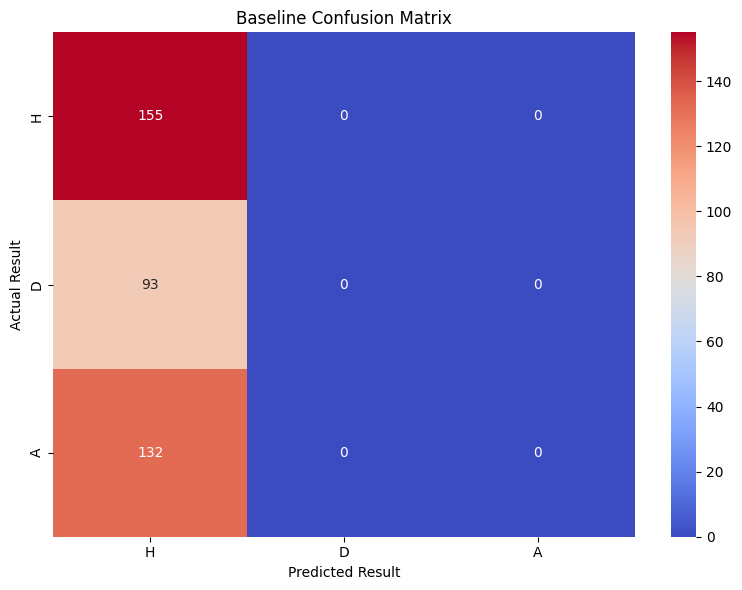

In [68]:
#plot

plt.figure(figsize = (8, 6))
sns.heatmap(
    baseline_confusion_df,
    annot = True,
    fmt ="d",
    cmap = "coolwarm"
)

plt.title("Baseline Confusion Matrix")
plt.xlabel("Predicted Result")
plt.ylabel("Actual Result")
plt.tight_layout()
plt.show()

# Logistic Regression Model

In [69]:
logistic_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter = 1000)
)

logistic_model.fit(X_train, y_train)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('logisticregression', LogisticRegression(max_iter=1000))])

In [70]:
logistic_valid_predictions = logistic_model.predict(X_validation)
logistic_valid_probabilities = logistic_model.predict_proba(X_validation)

logistic_valid_accuracy = accuracy_score(y_validation, logistic_valid_predictions)

logistic_log_loss = log_loss(
    y_validation,
    logistic_valid_probabilities,
    labels = logistic_model.classes_
)

print("Logistic regression validation accuracy:", round(logistic_valid_accuracy, 3))
print("Logistic regression log loss:", round(logistic_log_loss, 3))

Logistic regression validation accuracy: 0.532
Logistic regression log loss: 1.004


In [71]:
#classification report
print(classification_report(y_validation, logistic_valid_predictions, zero_division = 0))

              precision    recall  f1-score   support

           A       0.55      0.59      0.57       132
           D       0.00      0.00      0.00        93
           H       0.52      0.80      0.63       155

    accuracy                           0.53       380
   macro avg       0.36      0.46      0.40       380
weighted avg       0.40      0.53      0.46       380



In [72]:
#confusion matrix

logistic_confusion = confusion_matrix(
    y_validation,
    logistic_valid_predictions,
    labels = labels
)

logistic_confusion_df = pd.DataFrame(
    logistic_confusion,
    index = labels,
    columns = labels
)

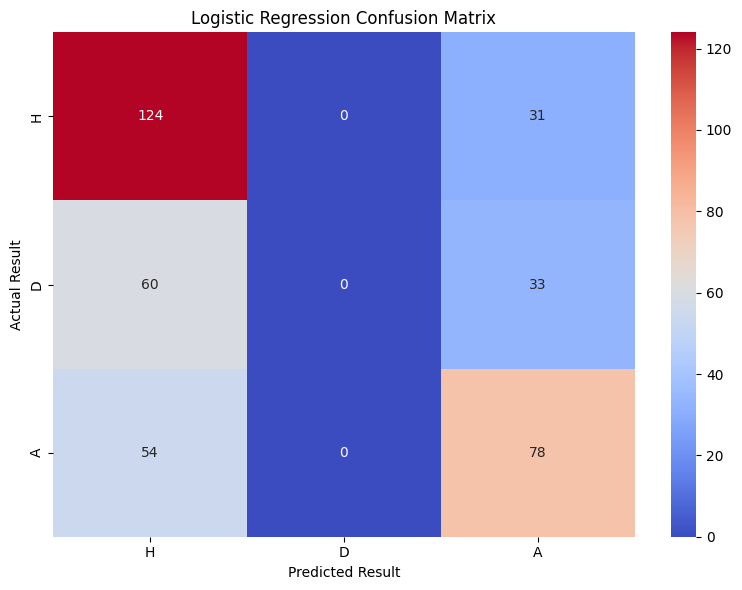

In [73]:
#plot

plt.figure(figsize = (8, 6))
sns.heatmap(
    logistic_confusion_df,
    annot = True,
    fmt = "d",
    cmap = "coolwarm"
)

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted Result")
plt.ylabel("Actual Result")
plt.tight_layout()
plt.show()

# Gradient Boosting Model

In [74]:
gradient_boosting_model = GradientBoostingClassifier(
    random_state = 42
)

gradient_boosting_model.fit(X_train, y_train)

GradientBoostingClassifier(random_state=42)

In [75]:
gb_valid_predictions = gradient_boosting_model.predict(X_validation)
gb_valid_probabilities = gradient_boosting_model.predict_proba(X_validation)

gb_valid_accuracy = accuracy_score(y_validation, gb_valid_predictions)

gb_log_loss = log_loss(
    y_validation,
    gb_valid_probabilities,
    labels = gradient_boosting_model.classes_
)

print("Gradient Boosting validation accuracy:", round(gb_valid_accuracy, 3))
print("Gradient Boosting validation log loss:", round(gb_log_loss, 3))

Gradient Boosting validation accuracy: 0.479
Gradient Boosting validation log loss: 1.034


In [76]:
#classification report

print(classification_report(y_validation, gb_valid_predictions))

              precision    recall  f1-score   support

           A       0.48      0.49      0.49       132
           D       0.17      0.05      0.08        93
           H       0.52      0.72      0.60       155

    accuracy                           0.48       380
   macro avg       0.39      0.42      0.39       380
weighted avg       0.42      0.48      0.44       380



In [77]:
#confusion matrix

gb_confusion = confusion_matrix(
    y_validation,
    gb_valid_predictions,
    labels = labels
)

gb_confusion_df = pd.DataFrame(
    gb_confusion,
    index = labels,
    columns = labels
)

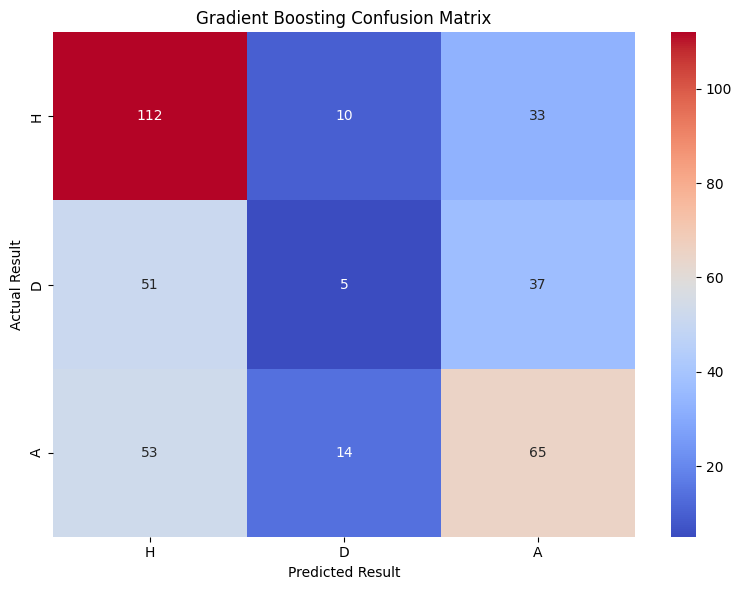

In [78]:
#plot

plt.figure(figsize = (8, 6))
sns.heatmap(
    gb_confusion_df,
    annot = True,
    fmt = "d",
    cmap = "coolwarm"
)

plt.title("Gradient Boosting Confusion Matrix")
plt.xlabel("Predicted Result")
plt.ylabel("Actual Result")
plt.tight_layout()
plt.show()


In [79]:
#Feature Importance

feature_importance = pd.DataFrame({
    "Feature": feature_cols,
    "Importance": gradient_boosting_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "Importance",
    ascending = False
)

feature_importance

,Feature,Importance
12,home_preseason_elo,0.290665
13,away_preseason_elo,0.235085
9,away_previous_shots_on_target_conceded_pg,0.074960
2,home_previous_goals_scored_pg,0.061318
8,home_previous_shots_on_target_conceded_pg,0.049191
7,away_previous_shots_on_target_pg,0.048297
6,home_previous_shots_on_target_pg,0.044486
3,away_previous_goals_scored_pg,0.043516
4,home_previous_goals_conceded_pg,0.040581
10,home_previous_position,0.029852


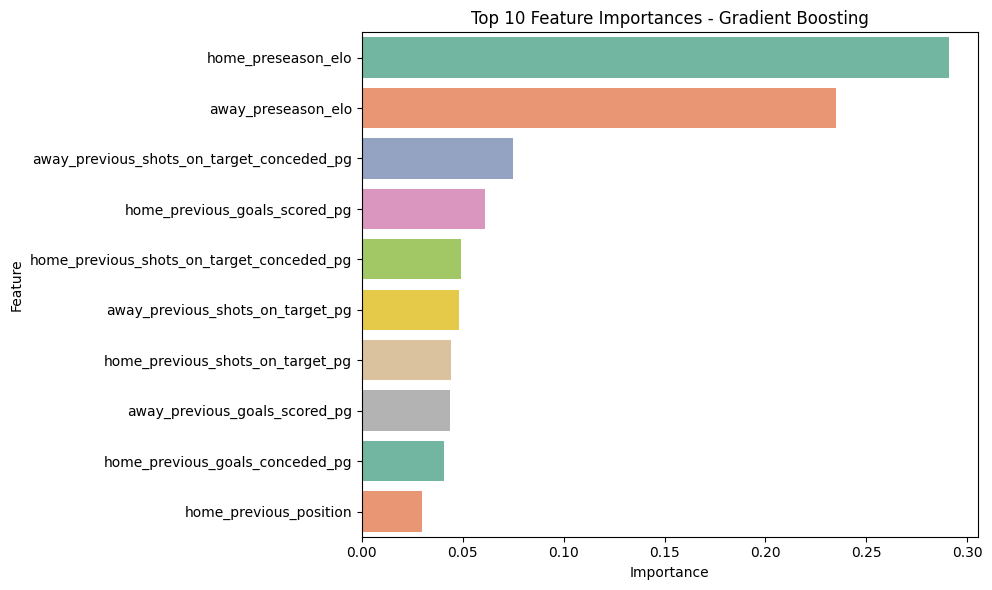

In [80]:
#plot

plt.figure(figsize = (10, 6))
sns.barplot(
    x = "Importance",
    y = "Feature",
    hue = "Feature",
    data = feature_importance.head(10),
    palette = "Set2",
    legend = False
)

plt.title("Top 10 Feature Importances - Gradient Boosting")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [81]:
#compare models

validation_comparison = pd.DataFrame({
    "Model": [
        "Baseline",
        "Logistic Regression",
        "Gradient Boosting"
    ],
    "Validation Accuracy": [
        baseline_valid_accuracy,
        logistic_valid_accuracy,
        gb_valid_accuracy
    ],
    "Validation Log Loss": [
        baseline_log_loss,
        logistic_log_loss,
        gb_log_loss
    ]
})

validation_comparison.round(3)

,Model,Validation Accuracy,Validation Log Loss
0,Baseline,0.408,1.082
1,Logistic Regression,0.532,1.004
2,Gradient Boosting,0.479,1.034


In [82]:
#select final model

candidate_models = validation_comparison[
    validation_comparison["Model"]
    != "Baseline"
].copy()

selected_ml_model_name = (
    candidate_models
    .sort_values(
        [
            "Validation Log Loss",
            "Validation Accuracy"
        ],
        ascending = [
            True,
            False
        ]
    )
    .iloc[0]["Model"]
)

print("Selected machine learning final model:", selected_ml_model_name)

Selected machine learning final model: Logistic Regression


## Poisson Goal Model

In [83]:
#goal targets for poisson model

y_home_goals_train = train_data["FTHG"].astype(int)
y_away_goals_train = train_data["FTAG"].astype(int)

y_home_goals_validation = validation_data["FTHG"].astype(int)
y_away_goals_validation = validation_data["FTAG"].astype(int)

y_home_goals_test = test_data["FTHG"].astype(int)
y_away_goals_test = test_data["FTAG"].astype(int)

print("Home training target:", y_home_goals_train.shape)
print("Away training target:", y_away_goals_train.shape)
print("Home validation target:", y_home_goals_validation.shape)
print("Away validation target:", y_away_goals_validation.shape)

Home training target: (5320,)
Away training target: (5320,)
Home validation target: (380,)
Away validation target: (380,)


In [84]:
#goals distribution

print("Average training home goals:", round(y_home_goals_train.mean(), 2))
print("Average training away goals:", round(y_away_goals_train.mean(), 2))
print("Maximum home goals:", y_home_goals_train.max())
print("Maximum away goals:", y_away_goals_train.max())

Average training home goals: 1.56
Average training away goals: 1.23
Maximum home goals: 9
Maximum away goals: 9


In [85]:
#poisson model for goals

home_poisson_model = make_pipeline(
    StandardScaler(),
    PoissonRegressor(alpha = 1, max_iter = 1000)
)
away_poisson_model = make_pipeline(
    StandardScaler(),
    PoissonRegressor(alpha = 1, max_iter = 1000)
)

home_poisson_model.fit(X_train, y_home_goals_train)
away_poisson_model.fit(X_train, y_away_goals_train)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('poissonregressor', PoissonRegressor(alpha=1, max_iter=1000))])

In [86]:
#expected home and away goals

validation_expected_home_goals = (
    home_poisson_model.predict(X_validation)
)
validation_expected_away_goals = (
    away_poisson_model.predict(X_validation)
)

In [87]:
#check predictions

poisson_validation_goal_predictions = (
    validation_data[
        ["Date", "HomeTeam", "AwayTeam", "FTHG", "FTAG"]
    ].copy().reset_index(drop = True)
)

poisson_validation_goal_predictions["ExpectedHomeGoals"] = validation_expected_home_goals
poisson_validation_goal_predictions["ExpectedAwayGoals"] = validation_expected_away_goals
poisson_validation_goal_predictions["ExpectedTotalGoals"] = (
    poisson_validation_goal_predictions["ExpectedHomeGoals"] +
    poisson_validation_goal_predictions["ExpectedAwayGoals"]
)

poisson_validation_goal_predictions.head()

,Date,HomeTeam,AwayTeam,FTHG,FTAG,ExpectedHomeGoals,ExpectedAwayGoals,ExpectedTotalGoals
0,2024-08-16,Man United,Fulham,1,0,1.659374,1.100025,2.759399
1,2024-08-17,West Ham,Aston Villa,1,2,1.329678,1.502184,2.831862
2,2024-08-17,Newcastle,Southampton,1,0,2.206788,0.822774,3.029562
3,2024-08-17,Nott'm Forest,Bournemouth,1,1,1.371348,1.297866,2.669214
4,2024-08-17,Arsenal,Wolves,2,0,2.477767,0.790005,3.267772


In [88]:
#mean absolute error of goals

home_goal_mae = mean_absolute_error(
    y_home_goals_validation,
    validation_expected_home_goals
)

away_goal_mae = mean_absolute_error(
    y_away_goals_validation,
    validation_expected_away_goals
)

actual_validation_total_goals = (
    y_home_goals_validation.values +
    y_away_goals_validation.values
)

expected_validation_total_goals = (
    validation_expected_home_goals +
    validation_expected_away_goals
)

total_goal_mae = mean_absolute_error(
    actual_validation_total_goals,
    expected_validation_total_goals
)

print("Home-goal validation MAE:", round(home_goal_mae, 3))
print("Away-goal validation MAE:", round(away_goal_mae, 3))
print("Total-goal validation MAE:", round(total_goal_mae, 3))

Home-goal validation MAE: 0.953
Away-goal validation MAE: 0.875
Total-goal validation MAE: 1.281


In [89]:
#Poisson deviance

validation_expected_home_goals_safe = np.clip(
    validation_expected_home_goals, 1e-10, None
)
validation_expected_away_goals_safe = np.clip(
    validation_expected_away_goals, 1e-10, None
)

home_poisson_deviance = (
    mean_poisson_deviance(
        y_home_goals_validation, validation_expected_home_goals_safe
        )
    )
away_poisson_deviance = (
    mean_poisson_deviance(
        y_away_goals_validation, validation_expected_away_goals_safe
        )
    )

print("Home goal mean Poisson deviance:", round(home_poisson_deviance, 3))
print("Away goal mean Poisson deviance:", round(away_poisson_deviance, 3))

Home goal mean Poisson deviance: 1.116
Away goal mean Poisson deviance: 1.047


In [90]:
#goal baseline

mean_home_goals = y_home_goals_train.mean()
mean_away_goals = y_away_goals_train.mean()

baseline_home_goal_predictions = np.repeat(
    mean_home_goals, len(y_home_goals_validation)
)
baseline_away_goal_predictions = np.repeat(
    mean_away_goals, len(y_away_goals_validation)
)

baseline_home_goal_mae = (
    mean_absolute_error(y_home_goals_validation, baseline_home_goal_predictions
    )
)
baseline_away_goal_mae = (
    mean_absolute_error(y_away_goals_validation, baseline_away_goal_predictions
    )
)

baseline_total_goal_predictions = (
    baseline_home_goal_predictions + baseline_away_goal_predictions
)
baseline_total_goal_mae = (
    mean_absolute_error(
        actual_validation_total_goals, baseline_total_goal_predictions
    )
)

print("Baseline home goal MAE:", round(baseline_home_goal_mae, 3))
print("Baseline away goal MAE:", round(baseline_away_goal_mae, 3))
print("Baseline total goal MAE:", round(baseline_total_goal_mae, 3))

Baseline home goal MAE: 1.054
Baseline away goal MAE: 0.916
Baseline total goal MAE: 1.288


In [91]:
#comparison

poisson_goal_comparison = pd.DataFrame({
    "Model": ["Mean Goal Baseline", "Poisson Regression"],
    "Home Goal MAE": [baseline_home_goal_mae, home_goal_mae],
    "Away Goal MAE": [baseline_away_goal_mae, away_goal_mae],
    "Total Goal MAE": [baseline_total_goal_mae, total_goal_mae]
})

poisson_goal_comparison.round(3)

,Model,Home Goal MAE,Away Goal MAE,Total Goal MAE
0,Mean Goal Baseline,1.054,0.916,1.288
1,Poisson Regression,0.953,0.875,1.281


In [92]:
#check max and min goal predictions

print("Minimum predicted home goals:", validation_expected_home_goals.min())
print("Maximum predicted home goals:", validation_expected_home_goals.max())
print("Minimum predicted away goals:", validation_expected_away_goals.min())
print("Maximum predicted away goals:", validation_expected_away_goals.max())

Minimum predicted home goals: 0.8556442656832794
Maximum predicted home goals: 3.043029376845367
Minimum predicted away goals: 0.6282388891144394
Maximum predicted away goals: 2.487512488301934


In [93]:
#average predicted goals

print("Actual average home goals:", round(y_home_goals_validation.mean(), 3))
print("Predicted average home goals:", round(validation_expected_home_goals.mean(), 3))
print("Actual average away goals:", round(y_away_goals_validation.mean(), 3))
print("Predicted average away goals:", round(validation_expected_away_goals.mean(), 3))

Actual average home goals: 1.513
Predicted average home goals: 1.606
Actual average away goals: 1.421
Predicted average away goals: 1.281


In [94]:
#expected goals into match probabilities

def calculate_poisson_probabilities(
    expected_home_goals, expected_away_goals, max_goals = 10
):

    #calculate each team's probability of scoring 0 to max_goals
    goal_values = np.arange(0, max_goals + 1)

    home_goal_probabilities = poisson.pmf(goal_values, expected_home_goals)
    away_goal_probabilities = poisson.pmf(goal_values, expected_away_goals)

    score_probability_matrix = np.outer(
        home_goal_probabilities, away_goal_probabilities
    )

    #normalise the matrix of possible score probabilities
    score_probability_matrix = (
        score_probability_matrix /
        score_probability_matrix.sum()
    )

    home_win_probability = np.tril(
        score_probability_matrix, k = -1).sum()
    draw_probability = np.trace(
        score_probability_matrix)
    away_win_probability = np.triu(
        score_probability_matrix, k = 1).sum()

    #scoreline with the highest probability
    most_likely_score_index = np.unravel_index(
        np.argmax(score_probability_matrix),
        score_probability_matrix.shape
    )
    most_likely_home_goals = most_likely_score_index[0]
    most_likely_away_goals = most_likely_score_index[1]

    return {
        "Prob_HomeWin": home_win_probability,
        "Prob_Draw": draw_probability,
        "Prob_AwayWin": away_win_probability,
        "MostLikelyHomeGoals": most_likely_home_goals,
        "MostLikelyAwayGoals": most_likely_away_goals
    }

In [95]:
#probability for validation matches

poisson_home_win_probabilities = []
poisson_draw_probabilities = []
poisson_away_win_probabilities = []

most_likely_home_goals = []
most_likely_away_goals = []

for home_rate, away_rate in zip(
    validation_expected_home_goals, validation_expected_away_goals
):

    match_probabilities = (
        calculate_poisson_probabilities(
            expected_home_goals = home_rate,
            expected_away_goals = away_rate,
            max_goals = 10
        )
    )

    poisson_home_win_probabilities.append(match_probabilities["Prob_HomeWin"])
    poisson_draw_probabilities.append(match_probabilities["Prob_Draw"])
    poisson_away_win_probabilities.append(match_probabilities["Prob_AwayWin"])

    most_likely_home_goals.append(match_probabilities["MostLikelyHomeGoals"])
    most_likely_away_goals.append(match_probabilities["MostLikelyAwayGoals"])

#convert into numpy array

poisson_home_win_probabilities = np.array(poisson_home_win_probabilities)
poisson_draw_probabilities = np.array(poisson_draw_probabilities)
poisson_away_win_probabilities = np.array(poisson_away_win_probabilities)

most_likely_home_goals = np.array(most_likely_home_goals)
most_likely_away_goals = np.array( most_likely_away_goals)

In [96]:
#validate the results

poisson_validation_results = validation_data[
    ["Date", "HomeTeam", "AwayTeam", "FTHG", "FTAG", "FTR"]
    ].copy()

poisson_validation_results = (poisson_validation_results.reset_index(drop=True))

poisson_validation_results["ExpectedHomeGoals"] = validation_expected_home_goals
poisson_validation_results["ExpectedAwayGoals"] = validation_expected_away_goals
poisson_validation_results["Prob_HomeWin"] = poisson_home_win_probabilities
poisson_validation_results["Prob_Draw"] = poisson_draw_probabilities
poisson_validation_results["Prob_AwayWin"] = poisson_away_win_probabilities
poisson_validation_results["MostLikelyHomeGoals"] = most_likely_home_goals
poisson_validation_results["MostLikelyAwayGoals"] = most_likely_away_goals

In [97]:
#most likely scorelines

poisson_validation_results["MostLikelyScore"] = (
    poisson_validation_results[
        "MostLikelyHomeGoals"].astype(str) + "-"
    + poisson_validation_results[
        "MostLikelyAwayGoals"
    ].astype(str)
)

poisson_validation_results.head(10)

,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,ExpectedHomeGoals,ExpectedAwayGoals,Prob_HomeWin,Prob_Draw,Prob_AwayWin,MostLikelyHomeGoals,MostLikelyAwayGoals,MostLikelyScore
0,2024-08-16,Man United,Fulham,1,0,H,1.659374,1.100025,0.504191,0.243695,0.252114,1,1,1-1
1,2024-08-17,West Ham,Aston Villa,1,2,A,1.329678,1.502184,0.336067,0.250113,0.413820,1,1,1-1
2,2024-08-17,Newcastle,Southampton,1,0,H,2.206788,0.822774,0.689135,0.184962,0.125903,2,0,2-0
3,2024-08-17,Nott'm Forest,Bournemouth,1,1,D,1.371348,1.297866,0.387165,0.259700,0.353135,1,1,1-1
4,2024-08-17,Arsenal,Wolves,2,0,H,2.477767,0.790005,0.743111,0.158136,0.098752,2,0,2-0
5,2024-08-17,Everton,Brighton,0,3,A,1.422919,1.241689,0.412490,0.258915,0.328595,1,1,1-1
6,2024-08-17,Ipswich,Liverpool,0,2,A,0.935407,2.203305,0.147396,0.190700,0.661904,0,2,0-2
7,2024-08-18,Brentford,Crystal Palace,2,1,H,1.375583,1.332066,0.381172,0.257686,0.361142,1,1,1-1
8,2024-08-18,Chelsea,Man City,0,2,A,1.318976,1.746107,0.290477,0.234281,0.475242,1,1,1-1
9,2024-08-19,Leicester,Tottenham,1,1,D,1.088016,1.808823,0.227020,0.230519,0.542461,1,1,1-1


In [98]:
#predicting match results

poisson_result_probabilities = (np.column_stack([
    poisson_away_win_probabilities,
    poisson_draw_probabilities,
    poisson_home_win_probabilities
])
)

result_order = np.array(["A", "D", "H"])

poisson_validation_predictions = result_order[
    np.argmax(poisson_result_probabilities, axis = 1)
]
poisson_validation_results["PredictedResult"] = poisson_validation_predictions

poisson_validation_results[
    ["HomeTeam",
     "AwayTeam",
     "ExpectedHomeGoals",
     "ExpectedAwayGoals",
     "Prob_HomeWin",
     "Prob_Draw",
     "Prob_AwayWin",
     "MostLikelyScore",
     "PredictedResult",
     "FTR"]
].head()

,HomeTeam,AwayTeam,ExpectedHomeGoals,ExpectedAwayGoals,Prob_HomeWin,Prob_Draw,Prob_AwayWin,MostLikelyScore,PredictedResult,FTR
0,Man United,Fulham,1.659374,1.100025,0.504191,0.243695,0.252114,1-1,H,H
1,West Ham,Aston Villa,1.329678,1.502184,0.336067,0.250113,0.413820,1-1,A,A
2,Newcastle,Southampton,2.206788,0.822774,0.689135,0.184962,0.125903,2-0,H,H
3,Nott'm Forest,Bournemouth,1.371348,1.297866,0.387165,0.259700,0.353135,1-1,H,D
4,Arsenal,Wolves,2.477767,0.790005,0.743111,0.158136,0.098752,2-0,H,H


In [99]:
#Validation accuracy and Log Loss

poisson_validation_accuracy = accuracy_score(
    y_validation, poisson_validation_predictions
)

poisson_validation_probabilities = (np.column_stack([
    poisson_away_win_probabilities,
    poisson_draw_probabilities,
    poisson_home_win_probabilities
]))

poisson_validation_log_loss = log_loss(
    y_validation, poisson_validation_probabilities, labels = ["A", "D", "H"]
)

print("Poisson validation accuracy:", round(poisson_validation_accuracy, 3))
print("Poisson validation log loss:", round(poisson_validation_log_loss, 3))

Poisson validation accuracy: 0.526
Poisson validation log loss: 0.992


In [100]:
#classification report

print(classification_report(
    y_validation, poisson_validation_predictions, zero_division = 0
)
)

              precision    recall  f1-score   support

           A       0.57      0.55      0.56       132
           D       0.00      0.00      0.00        93
           H       0.50      0.82      0.62       155

    accuracy                           0.53       380
   macro avg       0.36      0.46      0.40       380
weighted avg       0.40      0.53      0.45       380



In [101]:
#confusion matrix

poisson_confusion = confusion_matrix(
    y_validation, poisson_validation_predictions, labels = ["H", "D", "A"]
)
poisson_confusion_df = pd.DataFrame(
    poisson_confusion, index = ["H", "D", "A"],
    columns = ["H", "D", "A"]
)

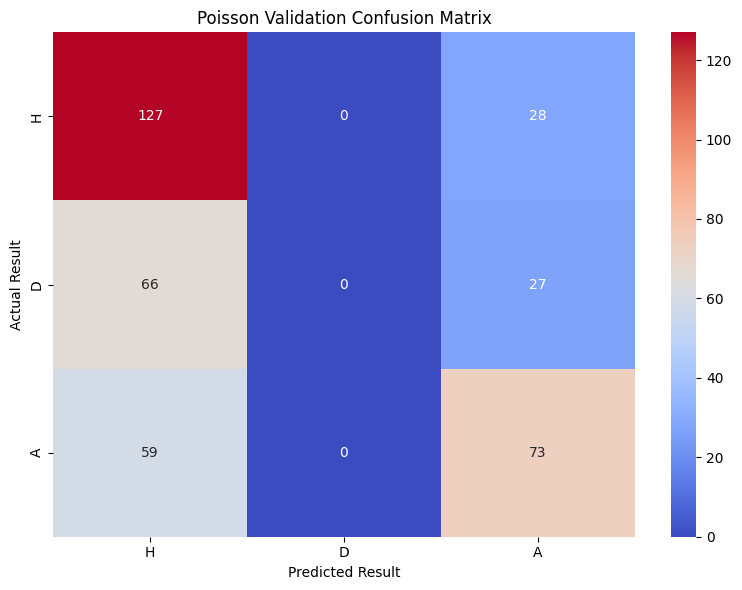

In [102]:
#plot

plt.figure(figsize = (8, 6))
sns.heatmap(
    poisson_confusion_df,
    annot = True,
    fmt = "d",
    cmap = "coolwarm"
)

plt.title("Poisson Validation Confusion Matrix")
plt.xlabel("Predicted Result")
plt.ylabel("Actual Result")
plt.tight_layout()
plt.show()

## Bayesian Model

In [103]:
#training and validation for bayesian

bayesian_scaler = StandardScaler()

X_train_bayesian = bayesian_scaler.fit_transform(X_train)
X_validation_bayesian = bayesian_scaler.transform(X_validation)

print("Bayesian training shape:", X_train_bayesian.shape)
print("Bayesian validation shape:", X_validation_bayesian.shape)

Bayesian training shape: (5320, 16)
Bayesian validation shape: (380, 16)


In [104]:
#Bayesian goal targets

y_home_goals_train_bayesian = (
    train_data["FTHG"].astype(int).to_numpy()
)
y_away_goals_train_bayesian = (
    train_data["FTAG"].astype(int).to_numpy()
)

y_home_goals_validation_bayesian = (
    validation_data["FTHG"].astype(int).to_numpy()
)
y_away_goals_validation_bayesian = (
    validation_data["FTAG"].astype(int).to_numpy()
)

In [105]:
#labels for model dimensions

bayesian_coords = {
    "feature": feature_cols,
    "match": np.arange(len(X_train_bayesian))
}

#creating model

with pm.Model(coords = bayesian_coords) as bayesian_poisson_model:

    #store the standardised predictor matrix

    X_bayesian_data = pm.Data("X_bayesian_data", X_train_bayesian,
                              dims = ("match", "feature"))

    #prior for goal intercept
    home_intercept = pm.Normal("home_intercept", mu = np.log(
        y_home_goals_train_bayesian.mean()), sigma = 0.3)
    away_intercept = pm.Normal("away_intercept", mu = np.log(
        y_away_goals_train_bayesian.mean()), sigma = 0.3)

    #prior goal coefficients
    home_beta = pm.Normal("home_beta", mu = 0, sigma = 0.3, dims = "feature")
    away_beta = pm.Normal("away_beta", mu = 0, sigma = 0.3, dims = "feature")

    #linear predictor
    home_log_rate = (home_intercept + pm.math.dot(
        X_bayesian_data, home_beta))
    away_log_rate = (away_intercept + pm.math.dot(
        X_bayesian_data, away_beta))

    #convert log rates into positive goal rates
    home_goal_rate = pm.math.exp(home_log_rate)
    away_goal_rate = pm.math.exp(away_log_rate)

    #observed goals
    observed_home_goals = pm.Poisson("observed_home_goals", mu = home_goal_rate,
                                     observed = y_home_goals_train_bayesian,
                                     dims = "match")
    observed_away_goals = pm.Poisson("observed_away_goals", mu = away_goal_rate,
                                     observed = y_away_goals_train_bayesian,
                                     dims = "match")

In [106]:
bayesian_poisson_model

In [107]:
#check installed PyMC major version

pymc_major_version = int(
    pm.__version__.split(".")[0]
)

In [108]:
#posterior sampling

with bayesian_poisson_model:

    if pymc_major_version >= 6:

        bayesian_trace = pm.sample(
            draws = 1000,
            tune = 1000,
            chains = 4,
            cores = 2,
            random_seed = 42,
            nuts = {"target_accept": 0.90},
            return_inferencedata=True
        )

    else:

        bayesian_trace = pm.sample(
            draws = 1000,
            tune = 1000,
            chains = 4,
            cores = 2,
            random_seed = 42,
            target_accept = 0.90,
            return_inferencedata = True
        )

Output()

In [109]:
#summary of posterior

bayesian_parameter_summary = az.summary(bayesian_trace, var_names = [
    "home_intercept", "away_intercept", "home_beta", "away_beta"],
                                        hdi_prob = 0.95, round_to = 3
)

bayesian_parameter_summary

,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
home_intercept,0.403,0.012,0.381,0.425,0.000,0.000,6486.591,2731.288,1.000
away_intercept,0.163,0.013,0.138,0.189,0.000,0.000,6691.787,2766.644,1.001
home_beta[home_previous_ppg],-0.222,0.062,-0.344,-0.101,0.001,0.001,4672.716,3144.412,1.000
home_beta[away_previous_ppg],0.150,0.069,0.015,0.282,0.001,0.001,4269.215,3044.821,1.003
home_beta[home_previous_goals_scored_pg],0.101,0.033,0.036,0.163,0.000,0.001,4665.335,2859.844,1.002
home_beta[away_previous_goals_scored_pg],-0.068,0.037,-0.136,0.007,0.001,0.001,4729.931,3123.278,1.001
home_beta[home_previous_goals_conceded_pg],-0.010,0.027,-0.065,0.040,0.000,0.000,5284.411,3456.090,1.001
home_beta[away_previous_goals_conceded_pg],0.079,0.027,0.025,0.129,0.000,0.000,4661.677,2912.772,1.001
home_beta[home_previous_shots_on_target_pg],0.048,0.027,-0.003,0.105,0.000,0.000,3938.135,2702.130,1.001
home_beta[away_previous_shots_on_target_pg],-0.027,0.029,-0.086,0.031,0.000,0.000,4630.619,3259.721,1.002


In [110]:
#check for convergence

maximum_rhat = bayesian_parameter_summary["r_hat"].max()
minimum_bulk_ess = bayesian_parameter_summary["ess_bulk"].min()
minimum_tail_ess = bayesian_parameter_summary["ess_tail"].min()
number_of_divergences = int(bayesian_trace.sample_stats["diverging"]
                            .sum().values)

print("Maximum R-hat:", maximum_rhat)
print("Minimum bulk ESS:", minimum_bulk_ess)
print("Minimum tail ESS:", minimum_tail_ess)
print("Number of Divergences:", number_of_divergences)

Maximum R-hat: 1.005
Minimum bulk ESS: 3938.135
Minimum tail ESS: 2702.13
Number of Divergences: 0


In [111]:
#display home goal coefficient estimate

home_beta_summary = az.summary(bayesian_trace, var_names = [
    "home_beta"], round_to = 3).reset_index()
home_beta_summary = (home_beta_summary.rename(columns = {
    "index": "Feature"}))

home_beta_summary.head()

,Feature,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
0,home_beta[home_previous_ppg],-0.222,0.062,-0.342,-0.108,0.001,0.001,4672.716,3144.412,1.000
1,home_beta[away_previous_ppg],0.150,0.069,0.021,0.277,0.001,0.001,4269.215,3044.821,1.003
2,home_beta[home_previous_goals_scored_pg],0.101,0.033,0.042,0.163,0.000,0.001,4665.335,2859.844,1.002
3,home_beta[away_previous_goals_scored_pg],-0.068,0.037,-0.136,0.002,0.001,0.001,4729.931,3123.278,1.001
4,home_beta[home_previous_goals_conceded_pg],-0.010,0.027,-0.058,0.042,0.000,0.000,5284.411,3456.090,1.001


In [112]:
#away goal coefficient estimate

away_beta_summary = az.summary(bayesian_trace, var_names = [
    "away_beta"], round_to = 3).reset_index()
away_beta_summary = (away_beta_summary.rename(columns = {
    "index": "Feature"}))

away_beta_summary.head()

,Feature,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
0,away_beta[home_previous_ppg],0.134,0.076,-0.017,0.266,0.001,0.001,4415.885,3175.934,1.005
1,away_beta[away_previous_ppg],-0.151,0.071,-0.276,-0.007,0.001,0.001,4106.080,2880.109,1.002
2,away_beta[home_previous_goals_scored_pg],-0.016,0.042,-0.093,0.063,0.001,0.001,4752.801,2859.449,1.001
3,away_beta[away_previous_goals_scored_pg],0.054,0.037,-0.020,0.121,0.001,0.001,4911.652,3111.983,1.000
4,away_beta[home_previous_goals_conceded_pg],0.095,0.029,0.039,0.149,0.000,0.000,4877.112,3049.844,1.000


In [113]:
#posterior predictive sampling

with bayesian_poisson_model:
    bayesian_posterior_predictive = (
        pm.sample_posterior_predictive(
            bayesian_trace, var_names = [
                "observed_home_goals", "observed_away_goals"
            ], random_seed = 42, return_inferencedata = True
        )
    )

Output()

In [114]:
#extract posterior predictive samples

posterior_predictive_home_goals = (
    bayesian_posterior_predictive.posterior_predictive[
        "observed_home_goals"
    ].values
)
posterior_predictive_away_goals = (
    bayesian_posterior_predictive.posterior_predictive[
        "observed_away_goals"
    ].values
)

In [115]:
#compare observed and predictive mean goals

print("Observed mean home goals:", round(y_home_goals_train_bayesian.mean(),3))
print("Predicted mean home goals:", round(posterior_predictive_home_goals.mean(),3))

print("Observed mean away goals:", round(y_away_goals_train_bayesian.mean(),3))
print("Predicted mean away goals:", round(posterior_predictive_away_goals.mean(),3))

Observed mean home goals: 1.559
Predicted mean home goals: 1.559
Observed mean away goals: 1.234
Predicted mean away goals: 1.234


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


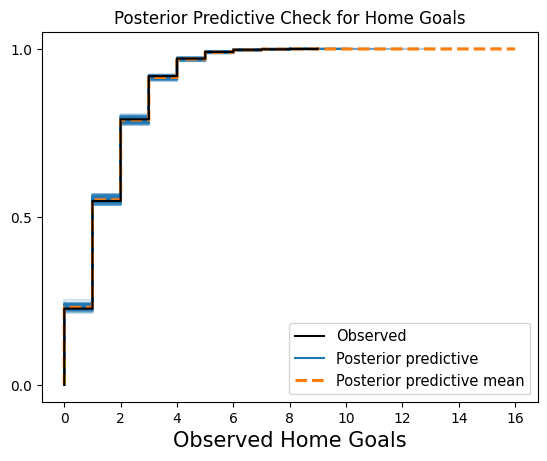

In [116]:
#check for home goals

az.plot_ppc(
    bayesian_posterior_predictive, var_names = ["observed_home_goals"],
    kind = "cumulative", num_pp_samples = 100, random_seed = 42
)

plt.title("Posterior Predictive Check for Home Goals")
plt.xlabel("Observed Home Goals")
plt.show()

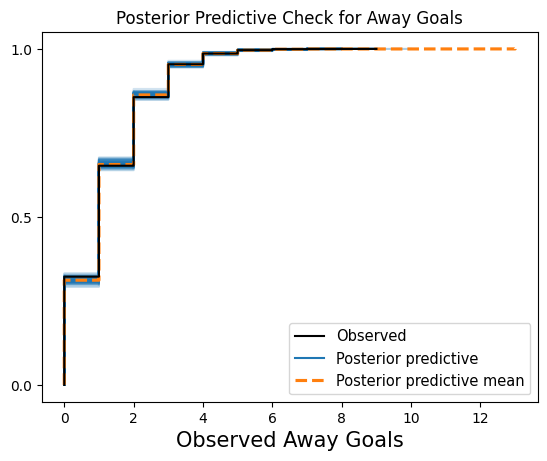

In [117]:
#check for away goals

az.plot_ppc(
    bayesian_posterior_predictive, var_names = ["observed_away_goals"],
    kind = "cumulative", num_pp_samples = 100, random_seed = 42
)

plt.title("Posterior Predictive Check for Away Goals")
plt.xlabel("Observed Away Goals")
plt.show()

In [118]:
#extract posterior samples

bayesian_posterior = bayesian_trace.posterior

home_intercept_draws = (bayesian_posterior["home_intercept"]
.stack(sample = ("chain", "draw")).values)
away_intercept_draws = (bayesian_posterior["away_intercept"]
.stack(sample = ("chain", "draw")).values)

home_beta_draws = (bayesian_posterior["home_beta"]
.stack(sample = ("chain", "draw")).transpose("sample", "feature").values)
away_beta_draws = (bayesian_posterior["away_beta"]
.stack(sample = ("chain", "draw")).transpose("sample", "feature").values)

In [119]:
#validation expected goals

home_validation_log_rate_draws = (
    home_intercept_draws[: , None]
    + home_beta_draws @ X_validation_bayesian.T
)

away_validation_log_rate_draws = (
    away_intercept_draws[: , None]
    + away_beta_draws @ X_validation_bayesian.T
)

home_validation_rate_draws = np.exp(home_validation_log_rate_draws)
away_validation_rate_draws = np.exp(away_validation_log_rate_draws)

print(
    "Home validation rate-draw shape:",
    home_validation_rate_draws.shape
)

print(
    "Away validation rate-draw shape:",
    away_validation_rate_draws.shape
)

Home validation rate-draw shape: (4000, 380)
Away validation rate-draw shape: (4000, 380)


In [120]:
#posterior mean expected goals

bayesian_validation_expected_home_goals = (
    home_validation_rate_draws.mean(axis= 0)
)
bayesian_validation_expected_away_goals = (
    away_validation_rate_draws.mean(axis = 0)
)

print(bayesian_validation_expected_home_goals.shape)
print(bayesian_validation_expected_away_goals.shape)

(380,)
(380,)


In [121]:
#calculate 95% credible interval

bayesian_validation_home_lower = np.quantile(
    home_validation_rate_draws, 0.025, axis = 0
)
bayesian_validation_home_upper = np.quantile(
    home_validation_rate_draws, 0.975, axis = 0
)

bayesian_validation_away_lower = np.quantile(
    away_validation_rate_draws, 0.025, axis = 0
)
bayesian_validation_away_upper = np.quantile(
    away_validation_rate_draws, 0.975, axis = 0
)

In [122]:
#validation table

bayesian_validation_goal_results = (validation_data[
    ["Date", "HomeTeam", "AwayTeam", "FTHG", "FTAG", "FTR"]
].copy().reset_index(drop = True))

#add posterior mean home goal prediction and interval

bayesian_validation_goal_results["ExpectedHomeGoals"] = bayesian_validation_expected_home_goals

bayesian_validation_goal_results["HomeExpectedGoalsLower95"] = bayesian_validation_home_lower
bayesian_validation_goal_results["HomeExpectedGoalsUpper95"] = bayesian_validation_home_upper

#add posterior mean away goal prediction and interval

bayesian_validation_goal_results["ExpectedAwayGoals"] = bayesian_validation_expected_away_goals

bayesian_validation_goal_results["AwayExpectedGoalsLower95"] = bayesian_validation_away_lower
bayesian_validation_goal_results["AwayExpectedGoalsUpper95"] = bayesian_validation_away_upper

bayesian_validation_goal_results.head()

,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,ExpectedHomeGoals,HomeExpectedGoalsLower95,HomeExpectedGoalsUpper95,ExpectedAwayGoals,AwayExpectedGoalsLower95,AwayExpectedGoalsUpper95
0,2024-08-16,Man United,Fulham,1,0,H,1.691838,1.573311,1.809639,1.089260,1.001019,1.179518
1,2024-08-17,West Ham,Aston Villa,1,2,A,1.337963,1.173558,1.524055,1.731337,1.483653,2.005876
2,2024-08-17,Newcastle,Southampton,1,0,H,2.467821,2.154354,2.817759,0.916816,0.775273,1.078633
3,2024-08-17,Nott'm Forest,Bournemouth,1,1,D,1.451734,1.325508,1.587618,1.382327,1.242324,1.527853
4,2024-08-17,Arsenal,Wolves,2,0,H,2.832427,2.586795,3.086108,0.707445,0.626196,0.798806


In [123]:
#calculate MAE

bayesian_validation_home_goal_mae = (mean_absolute_error(
    y_home_goals_validation_bayesian, bayesian_validation_expected_home_goals
))
bayesian_validation_away_goal_mae = (mean_absolute_error(
    y_away_goals_validation_bayesian, bayesian_validation_expected_away_goals
))

actual_validation_total_goals = (
    y_home_goals_validation_bayesian + y_away_goals_validation_bayesian
)

predicted_validation_total_goals = (
    bayesian_validation_expected_home_goals + bayesian_validation_expected_away_goals
)

bayesian_validation_total_goal_mae = (mean_absolute_error(
    actual_validation_total_goals, predicted_validation_total_goals
))

In [124]:
#calculate deviance

bayesian_validation_home_deviance = (mean_poisson_deviance(
    y_home_goals_validation_bayesian,
    np.clip(bayesian_validation_expected_home_goals, 1e-10, None)
))

bayesian_validation_away_deviance = (mean_poisson_deviance(
    y_away_goals_validation_bayesian,
    np.clip(bayesian_validation_expected_away_goals, 1e-10, None)
))

In [125]:
print("Bayesian validation home goal MAE:", round(bayesian_validation_home_goal_mae, 3))
print("Bayesian validation away goal MAE:", round(bayesian_validation_away_goal_mae, 3))
print("Bayesian validation total goal MAE:", round(bayesian_validation_total_goal_mae, 3))

print("Bayesian validation home goal deviance:", round(bayesian_validation_home_deviance, 3))
print("Bayesian validation away goal deviance:", round(bayesian_validation_away_deviance, 3))

Bayesian validation home goal MAE: 0.984
Bayesian validation away goal MAE: 0.897
Bayesian validation total goal MAE: 1.299
Bayesian validation home goal deviance: 1.15
Bayesian validation away goal deviance: 1.051


In [126]:
#probabilities for each posterior draw

bayesian_validation_away_probability_draws = (
    skellam.cdf(-1, home_validation_rate_draws, away_validation_rate_draws)
)

bayesian_validation_draw_probability_draws = (
    skellam.pmf(0, home_validation_rate_draws, away_validation_rate_draws)
)
bayesian_validation_home_probabilities_draws = (
    1- skellam.cdf(0, home_validation_rate_draws, away_validation_rate_draws)
)

In [127]:
#average the posterior draws

bayesian_validation_away_probabilities = (
    bayesian_validation_away_probability_draws.mean(axis = 0)
)

bayesian_validation_draw_probabilities = (
    bayesian_validation_draw_probability_draws.mean(axis = 0)
)

bayesian_validation_home_probabilities = (
    bayesian_validation_home_probabilities_draws.mean(axis = 0)
)

In [128]:
#arrange the probabilities

bayesian_validation_probabilities = np.column_stack([
    bayesian_validation_away_probabilities,
    bayesian_validation_draw_probabilities,
    bayesian_validation_home_probabilities
])

print("Probability matrix shape:", bayesian_validation_probabilities.shape)

Probability matrix shape: (380, 3)


In [129]:
#predicted results

bayesian_result_order= np.array(["A", "D", "H"])

bayesian_validation_prediction = (bayesian_result_order[
    np.argmax(bayesian_validation_probabilities,axis = 1)
])

In [130]:
#add result probabilities to validation table

bayesian_validation_goal_results["Prob_AwayWin"] = bayesian_validation_away_probabilities
bayesian_validation_goal_results["Prob_Draw"] =bayesian_validation_draw_probabilities
bayesian_validation_goal_results["Prob_HomeWin"] =bayesian_validation_home_probabilities

bayesian_validation_goal_results["PredictedResult"] =bayesian_validation_prediction

bayesian_validation_goal_results[
    ["HomeTeam", "AwayTeam", "ExpectedHomeGoals", "ExpectedAwayGoals",
    "Prob_HomeWin", "Prob_Draw", "Prob_AwayWin", "PredictedResult", "FTR"]
].head()

,HomeTeam,AwayTeam,ExpectedHomeGoals,ExpectedAwayGoals,Prob_HomeWin,Prob_Draw,Prob_AwayWin,PredictedResult,FTR
0,Man United,Fulham,1.691838,1.089260,0.514515,0.240835,0.244650,H,H
1,West Ham,Aston Villa,1.337963,1.731337,0.298047,0.234612,0.467340,A,A
2,Newcastle,Southampton,2.467821,0.916816,0.712208,0.166775,0.121017,H,H
3,Nott'm Forest,Bournemouth,1.451734,1.382327,0.390319,0.250697,0.358984,H,D
4,Arsenal,Wolves,2.832427,0.707445,0.809717,0.123916,0.066366,H,H


In [131]:
#validation accuracy

bayesian_validation_accuracy = accuracy_score(
    y_validation, bayesian_validation_prediction
)

print("Bayesian validation accuracy:", round(bayesian_validation_accuracy,3))

Bayesian validation accuracy: 0.526


In [132]:
#log loss
bayesian_validation_log_loss = log_loss(
    y_validation, bayesian_validation_probabilities,
    labels = ["A", "D", "H"]
)

print("Bayesian validation log loss:", round(bayesian_validation_log_loss, 3))

Bayesian validation log loss: 1.002


In [133]:
#classification report

print(classification_report(
    y_validation, bayesian_validation_prediction, zero_division = 0
))

              precision    recall  f1-score   support

           A       0.54      0.57      0.56       132
           D       0.00      0.00      0.00        93
           H       0.52      0.81      0.63       155

    accuracy                           0.53       380
   macro avg       0.35      0.46      0.40       380
weighted avg       0.40      0.53      0.45       380



In [134]:
#confusion matrix

bayesian_confusion = confusion_matrix(
    y_validation, bayesian_validation_prediction,
    labels = ["H", "D", "A"]
)

bayesian_confusion_df = pd.DataFrame(
    bayesian_confusion, columns = ["H", "D", "A"],
    index = ["H", "D", "A"]
)

bayesian_confusion_df

,H,D,A
H,125,0,30
D,60,0,33
A,57,0,75


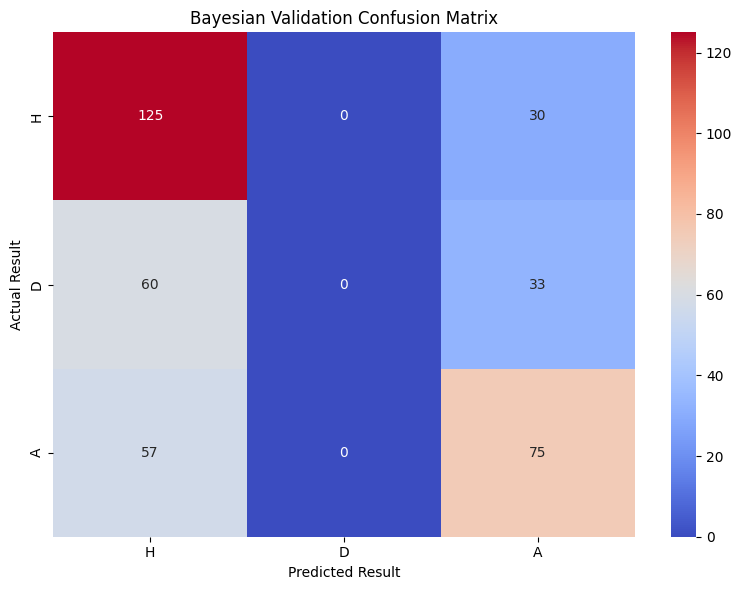

In [135]:
#plot

plt.figure(figsize = (8, 6))
sns.heatmap(
    bayesian_confusion_df, annot = True, fmt = "d", cmap = "coolwarm"
)

plt.title("Bayesian Validation Confusion Matrix")
plt.xlabel("Predicted Result")
plt.ylabel("Actual Result")
plt.tight_layout()
plt.show()

In [136]:
#compare all models

match_model_comparison = pd.DataFrame({
    "Model": [
        "Baseline", "Logistic Regression", "Gradient Boosting",
        "Poisson", "Bayesian"
    ],
    "Validation Accuracy": [
        baseline_valid_accuracy, logistic_valid_accuracy, gb_valid_accuracy,
        poisson_validation_accuracy, bayesian_validation_accuracy
    ],
    "Validation Log Loss": [
        baseline_log_loss, logistic_log_loss, gb_log_loss,
        poisson_validation_log_loss, bayesian_validation_log_loss
    ]
})

match_model_comparison.round(3)

,Model,Validation Accuracy,Validation Log Loss
0,Baseline,0.408,1.082
1,Logistic Regression,0.532,1.004
2,Gradient Boosting,0.479,1.034
3,Poisson,0.526,0.992
4,Bayesian,0.526,1.002


## Final Test Evaluation on 2025/26 Season

In [137]:
#combine test and validation data

train_valid_data = pd.concat([train_data, validation_data], ignore_index =True)

X_train_valid = train_valid_data[feature_cols]

print("Combined data shape:", train_valid_data.shape)
print("Combined feature shape:", X_train_valid.shape)

Combined data shape: (5700, 26)
Combined feature shape: (5700, 16)


In [138]:
# Learning target
y_train_valid = train_valid_data["FTR"]

# Final Baseline Model

In [139]:
#final test baseline
final_baseline_result = (y_train_valid.value_counts().idxmax())

final_baseline_predictions = np.repeat(
    final_baseline_result, len(y_test)
)

#baseline accuracy
final_baseline_accuracy = accuracy_score(
    y_test, final_baseline_predictions
)

#baseline probabilities based on training and validation data

final_baseline_class_order = np.array(
    sorted(y_train_valid.unique())
)

final_baseline_class_probabilities = (
    y_train_valid
    .value_counts(normalize=True)
    .reindex(final_baseline_class_order)
    .fillna(0)
    .to_numpy()
)

final_baseline_probability_matrix = np.tile(
    final_baseline_class_probabilities,
    (len(y_test), 1)
)

#baseline log loss

final_baseline_log_loss = log_loss(
    y_test,
    final_baseline_probability_matrix,
    labels=final_baseline_class_order
)


print("Baseline test accuracy:", round(final_baseline_accuracy, 3))
print("Baseline test log loss:", round(final_baseline_log_loss, 3))

Baseline test accuracy: 0.426
Baseline test log loss: 1.082


In [140]:
#classification report
print(
    classification_report(y_test, final_baseline_predictions,
                          zero_division = 0))

              precision    recall  f1-score   support

           A       0.00      0.00      0.00       114
           D       0.00      0.00      0.00       104
           H       0.43      1.00      0.60       162

    accuracy                           0.43       380
   macro avg       0.14      0.33      0.20       380
weighted avg       0.18      0.43      0.25       380



# Final Machine Learning Model

In [141]:
#Recreate the selected model

if selected_ml_model_name == "Logistic Regression":

    final_model = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter = 1000
        )
    )

elif selected_ml_model_name == "Gradient Boosting":

    final_model = (
        GradientBoostingClassifier(
            random_state = 42
        )
    )

In [142]:
#retrain

final_model.fit(X_train_valid, y_train_valid)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('logisticregression', LogisticRegression(max_iter=1000))])

In [143]:
test_predictions = final_model.predict(X_test)

test_probabilities = final_model.predict_proba(X_test)

test_accuracy = accuracy_score(y_test, test_predictions)

test_log_loss = log_loss(y_test, test_probabilities,
                         labels = final_model.classes_
)

print("2025/26 test accuracy:" , round(test_accuracy, 3))
print("2025/26 test log loss:", round(test_log_loss, 3))

2025/26 test accuracy: 0.468
2025/26 test log loss: 1.039


In [144]:
#classification report
print(classification_report(y_test, test_predictions, zero_division = 0))

              precision    recall  f1-score   support

           A       0.43      0.50      0.46       114
           D       0.00      0.00      0.00       104
           H       0.49      0.75      0.59       162

    accuracy                           0.47       380
   macro avg       0.31      0.42      0.35       380
weighted avg       0.34      0.47      0.39       380



In [145]:
#confusion matrix

test_confusion = confusion_matrix(
    y_test,
    test_predictions,
    labels = labels
)

test_confusion_df = pd.DataFrame(
    test_confusion,
    index = labels,
    columns = labels
)

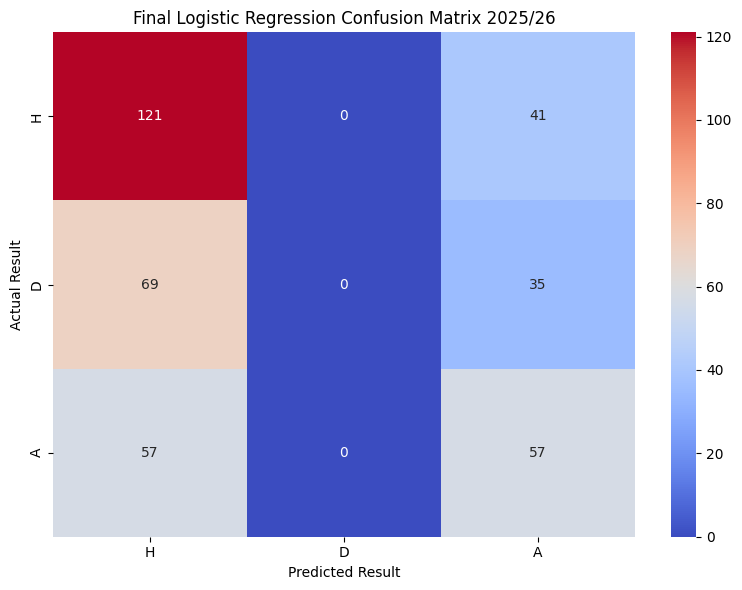

In [146]:
#plot

plt.figure(figsize = (8, 6))
sns.heatmap(
    test_confusion_df,
    annot = True,
    fmt = "d",
    cmap = "coolwarm"
)

plt.title(f"Final {selected_ml_model_name} Confusion Matrix 2025/26")
plt.xlabel("Predicted Result")
plt.ylabel("Actual Result")
plt.tight_layout()
plt.show()

In [147]:
#test results DataFrame

test_results = test_data[[
    "Season", "Date", "HomeTeam", "AwayTeam", "FTHG", "FTAG", "FTR"
]].copy()

test_results = test_results.reset_index(drop = True)
test_results ["PredictedResult"] = test_predictions

probability_df = pd.DataFrame(
    test_probabilities,
    columns = final_model.classes_
)

test_results["Prob_AwayWin"] = probability_df["A"].values
test_results["Prob_Draw"] = probability_df["D"].values
test_results["Prob_HomeWin"] = probability_df["H"].values

test_results.head()

,Season,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,PredictedResult,Prob_AwayWin,Prob_Draw,Prob_HomeWin
0,2025/26,2025-08-15,Liverpool,Bournemouth,4,2,H,H,0.142850,0.200844,0.656305
1,2025/26,2025-08-16,Aston Villa,Newcastle,0,0,D,H,0.278632,0.264839,0.456529
2,2025/26,2025-08-16,Brighton,Fulham,1,1,D,H,0.259548,0.249459,0.490993
3,2025/26,2025-08-16,Sunderland,West Ham,3,0,H,A,0.414264,0.261962,0.323775
4,2025/26,2025-08-16,Tottenham,Burnley,3,0,H,H,0.190593,0.209536,0.599871


In [148]:
#save prediction
test_results.to_csv(f"{selected_ml_model_name} 2025-26 Predictions.csv", index = False)

# Final Standard Poisson Model

In [149]:
#poisson targets

y_home_goals_train_valid = (train_valid_data["FTHG"].astype(int))
y_away_goals_train_valid = (train_valid_data["FTAG"].astype(int))

In [150]:
#final goal poisson model

final_home_poisson_model = make_pipeline(
    StandardScaler(),
    PoissonRegressor(alpha = 1, max_iter = 1000)
)
final_away_poisson_model = make_pipeline(
    StandardScaler(),
    PoissonRegressor(alpha = 1, max_iter = 1000)
)

final_home_poisson_model.fit(X_train_valid, y_home_goals_train_valid)
final_away_poisson_model.fit(X_train_valid, y_away_goals_train_valid)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('poissonregressor', PoissonRegressor(alpha=1, max_iter=1000))])

In [151]:
#predict expected goals for 25/26

test_expected_home_goals = (
    final_home_poisson_model.predict(X_test)
)
test_expected_away_goals = (
    final_away_poisson_model.predict(X_test)
)

In [152]:
#actual goals for 25/26

y_home_goals_test = test_data["FTHG"].astype(int)
y_away_goals_test = test_data["FTAG"].astype(int)

In [153]:
#Mean Absolute Error

#Expected home and away goal MAE
poisson_test_home_goal_mae = mean_absolute_error(
    y_home_goals_test, test_expected_home_goals
)
poisson_test_away_goal_mae = mean_absolute_error(
    y_away_goals_test, test_expected_away_goals
)

#Actual total goals
actual_test_total_goals = (
    y_home_goals_test.values + y_away_goals_test.values
)

#Predicted total goals
expected_test_total_goals = (
    test_expected_home_goals + test_expected_away_goals
)

#Total goals MAE
poisson_test_total_goal_mae = mean_absolute_error(
    actual_test_total_goals, expected_test_total_goals
)

print("Poisson test home goals MAE:", round(poisson_test_home_goal_mae, 3))
print("Poisson test away goals MAE:", round(poisson_test_away_goal_mae, 3))
print("Poisson test total goals MAE:", round(poisson_test_total_goal_mae, 3))

Poisson test home goals MAE: 0.949
Poisson test away goals MAE: 0.851
Poisson test total goals MAE: 1.228


In [154]:
#Poisson deviance

test_expected_home_goals_safe = np.clip(
    test_expected_home_goals, 1e-10, None
)
test_expected_away_goals_safe = np.clip(
    test_expected_away_goals, 1e-10, None
)

poisson_test_home_deviance = mean_poisson_deviance(
    y_home_goals_test, test_expected_home_goals_safe
)
poisson_test_away_deviance = mean_poisson_deviance(
    y_away_goals_test, test_expected_away_goals_safe
)

print("Poisson test home goals deviance:", round(poisson_test_home_deviance, 3))
print("Poisson test away goals deviance:", round(poisson_test_away_deviance, 3))

Poisson test home goals deviance: 1.07
Poisson test away goals deviance: 1.091


In [155]:
#store 25/26 poisson predictions

test_poisson_home_probabilities = []
test_poisson_draw_probabilities = []
test_poisson_away_probabilities = []

test_most_likely_home_goals = []
test_most_likely_away_goals = []

for home_rate, away_rate in zip(
    test_expected_home_goals, test_expected_away_goals
):
    match_probabilities = (
        calculate_poisson_probabilities(
            expected_home_goals = home_rate,
            expected_away_goals = away_rate,
            max_goals = 10
        )
    )

    test_poisson_home_probabilities.append(
        match_probabilities["Prob_HomeWin"]
    )
    test_poisson_draw_probabilities.append(
        match_probabilities["Prob_Draw"]
    )
    test_poisson_away_probabilities.append(
        match_probabilities["Prob_AwayWin"]
    )

    test_most_likely_home_goals.append(
        match_probabilities["MostLikelyHomeGoals"]
    )
    test_most_likely_away_goals.append(
        match_probabilities["MostLikelyAwayGoals"]
    )

In [156]:
#convert into arrays

test_poisson_home_probabilities = np.array(
    test_poisson_home_probabilities
)
test_poisson_draw_probabilities = np.array(
    test_poisson_draw_probabilities
)
test_poisson_away_probabilities = np.array(
    test_poisson_away_probabilities
)
test_most_likely_home_goals = np.array(
    test_most_likely_home_goals
)
test_most_likely_away_goals = np.array(
    test_most_likely_away_goals
)

In [157]:
#25/26 poisson results DataFrame

poisson_test_results = test_data[
    ["Season", "Date", "HomeTeam",
     "AwayTeam", "FTHG", "FTAG", "FTR"]
].copy()

poisson_test_results = (poisson_test_results.reset_index(drop = True))

poisson_test_results["ExpectedHomeGoals"] = test_expected_home_goals
poisson_test_results["ExpectedAwayGoals"] = test_expected_away_goals
poisson_test_results["ExpectedTotalGoals"] = (
    test_expected_home_goals
    + test_expected_away_goals
)

poisson_test_results["Prob_HomeWin"] = test_poisson_home_probabilities
poisson_test_results["Prob_Draw"] = test_poisson_draw_probabilities
poisson_test_results["Prob_AwayWin"] = test_poisson_away_probabilities

poisson_test_results["MostLikelyHomeGoals"] = test_most_likely_home_goals
poisson_test_results["MostLikelyAwayGoals"] = test_most_likely_away_goals
poisson_test_results["MostLikelyScore"] = (
    poisson_test_results[
        "MostLikelyHomeGoals"].astype(str)
    + "-"
    + poisson_test_results["MostLikelyAwayGoals"].astype(str)
)

In [158]:
#predicted match results


poisson_test_probabilities = np.column_stack([
    test_poisson_away_probabilities,
    test_poisson_draw_probabilities,
    test_poisson_home_probabilities
])

poisson_class_order = np.array(["A","D","H"])

poisson_test_predictions = poisson_class_order[
    np.argmax(
        poisson_test_probabilities, axis=1
    )
]

poisson_test_results["PredictedResult"] = poisson_test_predictions

poisson_test_results[
    [
        "HomeTeam",
        "AwayTeam",
        "ExpectedHomeGoals",
        "ExpectedAwayGoals",
        "Prob_HomeWin",
        "Prob_Draw",
        "Prob_AwayWin",
        "MostLikelyScore",
        "PredictedResult",
        "FTR"
    ]
].head()

,HomeTeam,AwayTeam,ExpectedHomeGoals,ExpectedAwayGoals,Prob_HomeWin,Prob_Draw,Prob_AwayWin,MostLikelyScore,PredictedResult,FTR
0,Liverpool,Bournemouth,2.021707,1.001882,0.609826,0.209764,0.180410,2-1,H,H
1,Aston Villa,Newcastle,1.529688,1.272703,0.432936,0.250324,0.316740,1-1,H,D
2,Brighton,Fulham,1.643115,1.167110,0.484644,0.244279,0.271076,1-1,H,D
3,Sunderland,West Ham,1.173781,1.464182,0.303411,0.258447,0.438142,1-1,A,H
4,Tottenham,Burnley,1.769049,0.959086,0.564293,0.233100,0.202607,1-0,H,H


In [159]:
#test accuracy and log loss

poisson_test_accuracy = accuracy_score(
    y_test, poisson_test_predictions
)
poisson_test_log_loss = log_loss(
    y_test, poisson_test_probabilities,
    labels=["A", "D", "H"]
)

print("Poisson test accuracy:", round(poisson_test_accuracy, 3))
print("Poisson test log loss:", round(poisson_test_log_loss, 3))

Poisson test accuracy: 0.474
Poisson test log loss: 1.052


In [160]:
#classification report

print(classification_report(
        y_test, poisson_test_predictions, zero_division=0
    )
)

              precision    recall  f1-score   support

           A       0.44      0.47      0.45       114
           D       0.00      0.00      0.00       104
           H       0.49      0.78      0.60       162

    accuracy                           0.47       380
   macro avg       0.31      0.42      0.35       380
weighted avg       0.34      0.47      0.39       380



In [161]:
#confusion matrix

poisson_test_confusion = confusion_matrix(
    y_test, poisson_test_predictions, labels=["H", "D", "A"]
)

poisson_test_confusion_df = pd.DataFrame(
    poisson_test_confusion, index=["H", "D", "A"],
    columns=["H", "D", "A"]
)

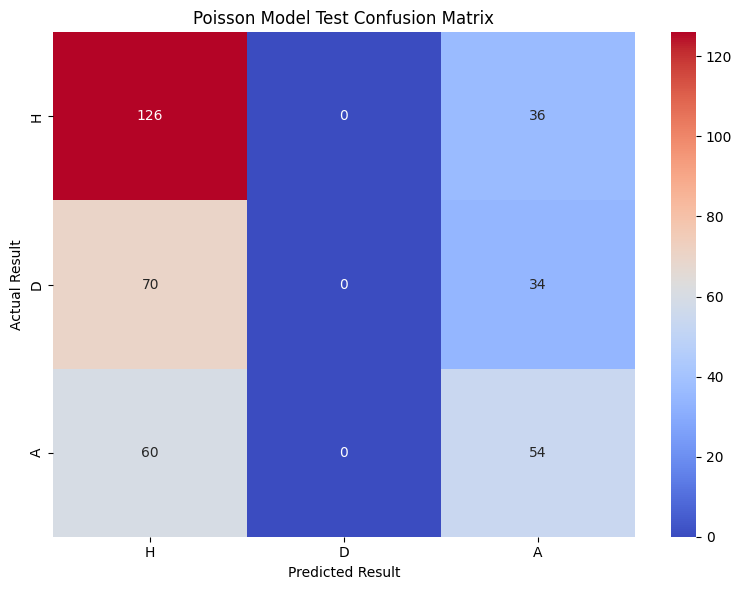

In [162]:
#plot

plt.figure(figsize = (8, 6))
sns.heatmap(
    poisson_test_confusion_df,
    annot=True,
    fmt="d",
    cmap="coolwarm"
)

plt.title("Poisson Model Test Confusion Matrix")
plt.xlabel("Predicted Result")
plt.ylabel("Actual Result")
plt.tight_layout()
plt.show()

In [163]:
#save the test predictions

poisson_test_results.to_csv("Poisson 2025-26 Match Predictions.csv", index = False)

# Final Bayesian Model

In [164]:
#Bayesian targets

y_home_goals_train_valid_bayesian = (
    train_valid_data["FTHG"].astype(int).to_numpy()
)
y_away_goals_train_valid_bayesian = (
    train_valid_data["FTAG"].astype(int).to_numpy()
)

In [165]:
#standardise features

final_bayesian_scaler = StandardScaler()

X_train_valid_bayesian = (
    final_bayesian_scaler.fit_transform(X_train_valid)
)
X_test_bayesian = (
    final_bayesian_scaler.transform(X_test)
)

In [166]:
#labels for bayesian model

final_bayesian_coords = {
    "feature": feature_cols,
    "match": np.arange(len(X_train_valid_bayesian))
}

#create model

with pm.Model(coords = final_bayesian_coords) as final_bayesian_poisson_model:

    X_final_bayesian_data = pm.Data(
        "X_final_bayesian_data", X_train_valid_bayesian,
        dims = ("match", "feature")
    )

    #priors for goal intercept
    home_intercept = pm.Normal(
        "home_intercept", mu = np.log(
            y_home_goals_train_valid_bayesian.mean()
        ), sigma = 0.3
    )
    away_intercept = pm.Normal(
        "away_intercept", mu = np.log(
            y_away_goals_train_valid_bayesian.mean()
        ), sigma = 0.3
    )

    #priors for goal coefficients
    home_beta = pm.Normal(
        "home_beta", mu = 0, sigma = 0.3, dims = "feature"
    )
    away_beta = pm.Normal(
        "away_beta", mu = 0, sigma = 0.3, dims = "feature"
    )

    #linear predictors
    home_log_rate = (
        home_intercept + pm.math.dot(
            X_final_bayesian_data, home_beta
        )
    )
    away_log_rate = (
        away_intercept + pm.math.dot(
            X_final_bayesian_data, away_beta
        )
    )

    #convert log into positive goal rate

    home_goal_rate = pm.math.exp(home_log_rate)
    away_goal_rate = pm.math.exp(away_log_rate)

    #observed goals
    observed_home_goals = pm.Poisson(
        "observed_home_goals", mu = home_goal_rate,
        observed = y_home_goals_train_valid_bayesian, dims = "match"
    )
    observed_away_goals = pm.Poisson(
        "observed_away_goals", mu = away_goal_rate,
        observed = y_away_goals_train_valid_bayesian, dims = "match"
    )

In [167]:
final_bayesian_poisson_model

In [168]:
#posterior sampling for final Bayesian model

with final_bayesian_poisson_model:

    if pymc_major_version >= 6:

        final_bayesian_trace = pm.sample(
            draws = 1000,
            tune = 1000,
            chains = 4,
            cores = 2,
            random_seed = 42,
            nuts = {"target_accept": 0.90},
            return_inferencedata = True
        )

    else:

        final_bayesian_trace = pm.sample(
            draws = 1000,
            tune = 1000,
            chains = 4,
            cores = 2,
            random_seed = 42,
            target_accept = 0.90,
            return_inferencedata = True
        )

Output()

In [169]:
#summary of final posterior

final_bayesian_parameter_summary = az.summary(
    final_bayesian_trace, var_names = [
        "home_intercept", "away_intercept",
        "home_beta", "away_beta"
    ], hdi_prob = 0.95, round_to = 3
)

final_bayesian_parameter_summary

,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
home_intercept,0.401,0.011,0.379,0.424,0.000,0.000,7480.535,2967.033,1.002
away_intercept,0.174,0.012,0.150,0.197,0.000,0.000,5511.638,2519.192,1.003
home_beta[home_previous_ppg],-0.192,0.060,-0.310,-0.073,0.001,0.001,4193.754,3212.037,1.002
home_beta[away_previous_ppg],0.138,0.064,0.012,0.263,0.001,0.001,4098.327,2742.274,1.001
home_beta[home_previous_goals_scored_pg],0.099,0.032,0.039,0.164,0.000,0.001,4587.082,3133.810,1.000
home_beta[away_previous_goals_scored_pg],-0.079,0.035,-0.145,-0.010,0.001,0.001,4296.037,3309.247,1.001
home_beta[home_previous_goals_conceded_pg],-0.031,0.027,-0.085,0.020,0.000,0.000,5009.403,3089.248,1.000
home_beta[away_previous_goals_conceded_pg],0.077,0.026,0.027,0.129,0.000,0.000,4807.983,3243.206,1.000
home_beta[home_previous_shots_on_target_pg],0.056,0.027,0.002,0.107,0.000,0.000,4671.005,2867.372,1.000
home_beta[away_previous_shots_on_target_pg],-0.027,0.028,-0.080,0.027,0.000,0.000,5110.592,2764.529,1.002


In [170]:
#convergence diagnostics

final_maximum_rhat = (
    final_bayesian_parameter_summary["r_hat"].max()
)
final_minimum_bulk_ess = (
    final_bayesian_parameter_summary["ess_bulk"].min()
)
final_minimum_tail_ess = (
    final_bayesian_parameter_summary["ess_tail"].min()
)
final_number_of_divergences = int(
    final_bayesian_trace.sample_stats["diverging"].sum().values
)

print("Maximum R-hat:", final_maximum_rhat)
print("Minimum bulk ESS:", final_minimum_bulk_ess)
print("Minimum tail ESS:", final_minimum_tail_ess)
print("Number of divergences:", final_number_of_divergences)

Maximum R-hat: 1.004
Minimum bulk ESS: 4098.327
Minimum tail ESS: 2519.192
Number of divergences: 0


In [171]:
#extract final posterior samples

final_bayesian_posterior = final_bayesian_trace.posterior

final_home_intercept_draws = (
    final_bayesian_posterior["home_intercept"]
    .stack(sample = ("chain", "draw")).values
)
final_away_intercept_draws = (
    final_bayesian_posterior["away_intercept"]
    .stack(sample = ("chain", "draw")).values
)

final_home_beta_draws = (
    final_bayesian_posterior["home_beta"]
    .stack(sample = ("chain", "draw"))
    .transpose("sample", "feature"). values
)
final_away_beta_draws = (
    final_bayesian_posterior["away_beta"]
    .stack(sample = ("chain", "draw"))
    .transpose("sample", "feature"). values
)

In [172]:
#25/26 expected goal rate draws

bayesian_test_home_log_rate_draws = (
    final_home_intercept_draws[:, None]
    + final_home_beta_draws @ X_test_bayesian.T
)
bayesian_test_away_log_rate_draws = (
    final_away_intercept_draws[:, None]
    + final_away_beta_draws @ X_test_bayesian.T
)

bayesian_test_home_rate_draws = np.exp(
    bayesian_test_home_log_rate_draws
)
bayesian_test_away_rate_draws = np.exp(
    bayesian_test_away_log_rate_draws
)

print("Home test rate draw shape:", bayesian_test_home_rate_draws.shape)
print("Away test rate draw shape:", bayesian_test_away_rate_draws.shape)

Home test rate draw shape: (4000, 380)
Away test rate draw shape: (4000, 380)


In [173]:
#posterior mean for expected goals

bayesian_test_expected_home_goals = (
    bayesian_test_home_rate_draws.mean(axis = 0)
)
bayesian_test_expected_away_goals = (
    bayesian_test_away_rate_draws.mean(axis = 0)
)

print(bayesian_test_expected_home_goals.shape)
print(bayesian_test_expected_away_goals.shape)

(380,)
(380,)


In [174]:
#95% credible interval

bayesian_test_home_lower = np.quantile(
    bayesian_test_home_rate_draws, 0.025, axis = 0
)
bayesian_test_home_upper = np.quantile(
    bayesian_test_home_rate_draws, 0.975, axis = 0
)

bayesian_test_away_lower = np.quantile(
    bayesian_test_away_rate_draws, 0.025, axis = 0
)
bayesian_test_away_upper = np.quantile(
    bayesian_test_away_rate_draws, 0.975, axis = 0
)

In [175]:
#test results table

bayesian_test_results = test_data[
    ["Season", "Date", "HomeTeam", "AwayTeam", "FTHG", "FTAG", "FTR"]
].copy().reset_index(drop = True)

bayesian_test_results["ExpectedHomeGoals"] = (
    bayesian_test_expected_home_goals
)
bayesian_test_results["HomeExpectedGoalsLower95"] = (
    bayesian_test_home_lower
)
bayesian_test_results["HomeExpectedGoalsUpper95"] = (
    bayesian_test_home_upper
)

bayesian_test_results["ExpectedAwayGoals"] = (
    bayesian_test_expected_away_goals
)
bayesian_test_results["AwayExpectedGoalsLower95"] = (
    bayesian_test_away_lower
)
bayesian_test_results["AwayExpectedGoalsUpper95"] = (
    bayesian_test_away_upper
)

bayesian_test_results["ExpectedTotalGoals"] = (
    bayesian_test_expected_home_goals
    + bayesian_test_expected_away_goals
)

bayesian_test_results.head()

,Season,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,ExpectedHomeGoals,HomeExpectedGoalsLower95,HomeExpectedGoalsUpper95,ExpectedAwayGoals,AwayExpectedGoalsLower95,AwayExpectedGoalsUpper95,ExpectedTotalGoals
0,2025/26,2025-08-15,Liverpool,Bournemouth,4,2,H,2.050559,1.922222,2.183391,0.971027,0.896292,1.050256,3.021586
1,2025/26,2025-08-16,Aston Villa,Newcastle,0,0,D,1.515618,1.415110,1.621124,1.258390,1.164358,1.357918,2.774008
2,2025/26,2025-08-16,Brighton,Fulham,1,1,D,1.689555,1.601260,1.781406,1.200596,1.129684,1.274702,2.890152
3,2025/26,2025-08-16,Sunderland,West Ham,3,0,H,1.356477,1.221194,1.496309,1.422329,1.278355,1.579707,2.778806
4,2025/26,2025-08-16,Tottenham,Burnley,3,0,H,1.883138,1.674528,2.105791,1.028519,0.893091,1.174156,2.911657


In [176]:
#test goal targets

y_home_goals_test_bayesian = (
    test_data["FTHG"].astype(int).to_numpy()
)
y_away_goals_test_bayesian = (
    test_data["FTAG"].astype(int).to_numpy()
)

In [177]:
#test MAE

bayesian_test_home_goal_mae = mean_absolute_error(
    y_home_goals_test_bayesian,
    bayesian_test_expected_home_goals
)

bayesian_test_away_goal_mae = mean_absolute_error(
    y_away_goals_test_bayesian,
    bayesian_test_expected_away_goals
)

bayesian_actual_test_total_goals = (
    y_home_goals_test_bayesian
    + y_away_goals_test_bayesian
)

bayesian_expected_test_total_goals = (
    bayesian_test_expected_home_goals
    + bayesian_test_expected_away_goals
)

bayesian_test_total_goal_mae = mean_absolute_error(
    bayesian_actual_test_total_goals,
    bayesian_expected_test_total_goals
)

print("Bayesian test home goal MAE:", round(bayesian_test_home_goal_mae, 3))
print("Bayesian test away goal MAE:", round(bayesian_test_away_goal_mae, 3))
print("Bayesian test total goal MAE:", round(bayesian_test_total_goal_mae, 3))

Bayesian test home goal MAE: 0.943
Bayesian test away goal MAE: 0.85
Bayesian test total goal MAE: 1.235


In [178]:
#test deviance

bayesian_test_home_deviance = mean_poisson_deviance(
    y_home_goals_test_bayesian,
    np.clip(bayesian_test_expected_home_goals, 1e-10, None)
)
bayesian_test_away_deviance = mean_poisson_deviance(
    y_away_goals_test_bayesian,
    np.clip(bayesian_test_expected_away_goals, 1e-10, None)
)

print("Bayesian test home goal deviance:", round(bayesian_test_home_deviance, 3))
print("Bayesian test away goal deviance:", round(bayesian_test_away_deviance, 3))

Bayesian test home goal deviance: 1.05
Bayesian test away goal deviance: 1.085


In [179]:
#result probabilities for posterior draws

bayesian_test_away_probability_draws =  skellam.cdf(
    -1, bayesian_test_home_rate_draws,
    bayesian_test_away_rate_draws
)

bayesian_test_draw_probability_draws = skellam.pmf(
    0, bayesian_test_home_rate_draws,
    bayesian_test_away_rate_draws
)

bayesian_test_home_probability_draws = (
    1 - skellam.cdf(0, bayesian_test_home_rate_draws,
                    bayesian_test_away_rate_draws)
)

In [180]:
#average posterior result probabilities

bayesian_test_away_probabilities = (
    bayesian_test_away_probability_draws.mean(axis = 0)
)

bayesian_test_draw_probabilities = (
    bayesian_test_draw_probability_draws.mean(axis = 0)
)

bayesian_test_home_probabilities = (
    bayesian_test_home_probability_draws.mean(axis = 0)
)

In [181]:
#arrange result probabilities

bayesian_test_probabilities = np.column_stack([
    bayesian_test_away_probabilities,
    bayesian_test_draw_probabilities,
    bayesian_test_home_probabilities
])

bayesian_test_result_order = np.array(["A", "D", "H"])

bayesian_test_predictions = bayesian_test_result_order[
    np.argmax(bayesian_test_probabilities, axis = 1)
]

print("Bayesian probability matrix shape:", bayesian_test_probabilities.shape)

Bayesian probability matrix shape: (380, 3)


In [182]:
#add to table

bayesian_test_results["Prob_HomeWin"] = (
    bayesian_test_home_probabilities
)
bayesian_test_results["Prob_Draw"] = (
    bayesian_test_draw_probabilities
)
bayesian_test_results["Prob_AwayWin"] = (
    bayesian_test_away_probabilities
)
bayesian_test_results["PredictedResult"] = (
    bayesian_test_predictions
)

bayesian_test_results[
    ["HomeTeam", "AwayTeam", "ExpectedHomeGoals", "ExpectedAwayGoals",
     "Prob_HomeWin", "Prob_Draw", "Prob_AwayWin", "PredictedResult", "FTR"]
].head()

,HomeTeam,AwayTeam,ExpectedHomeGoals,ExpectedAwayGoals,Prob_HomeWin,Prob_Draw,Prob_AwayWin,PredictedResult,FTR
0,Liverpool,Bournemouth,2.050559,0.971027,0.623017,0.206150,0.170833,H,H
1,Aston Villa,Newcastle,1.515618,1.258390,0.432537,0.251683,0.315780,H,D
2,Brighton,Fulham,1.689555,1.200596,0.488216,0.240056,0.271729,H,D
3,Sunderland,West Ham,1.356477,1.422329,0.358288,0.253568,0.388144,A,H
4,Tottenham,Burnley,1.883138,1.028519,0.573070,0.223032,0.203897,H,H


In [183]:
#test accuracy and log loss

bayesian_test_accuracy = accuracy_score(
    y_test, bayesian_test_predictions
)
bayesian_test_log_loss = log_loss(
    y_test, bayesian_test_probabilities,
    labels = ["A", "D", "H"]
)

print("Bayesian test accuracy:", round(bayesian_test_accuracy, 3))
print("Bayesian test log loss:", round(bayesian_test_log_loss, 3))

Bayesian test accuracy: 0.474
Bayesian test log loss: 1.038


In [184]:
#classification report

print(classification_report(y_test, bayesian_test_predictions, zero_division = 0))

              precision    recall  f1-score   support

           A       0.44      0.49      0.46       114
           D       0.00      0.00      0.00       104
           H       0.49      0.77      0.60       162

    accuracy                           0.47       380
   macro avg       0.31      0.42      0.35       380
weighted avg       0.34      0.47      0.39       380



In [185]:
#confusion matrix

bayesian_test_confusion = confusion_matrix(
    y_test, bayesian_test_predictions,
    labels = ["H", "D", "A"]
)
bayesian_test_confusion_df = pd.DataFrame(
    bayesian_test_confusion, index = ["H", "D", "A"],
    columns = ["H", "D", "A"]
)

bayesian_test_confusion_df

,H,D,A
H,124,0,38
D,71,0,33
A,58,0,56


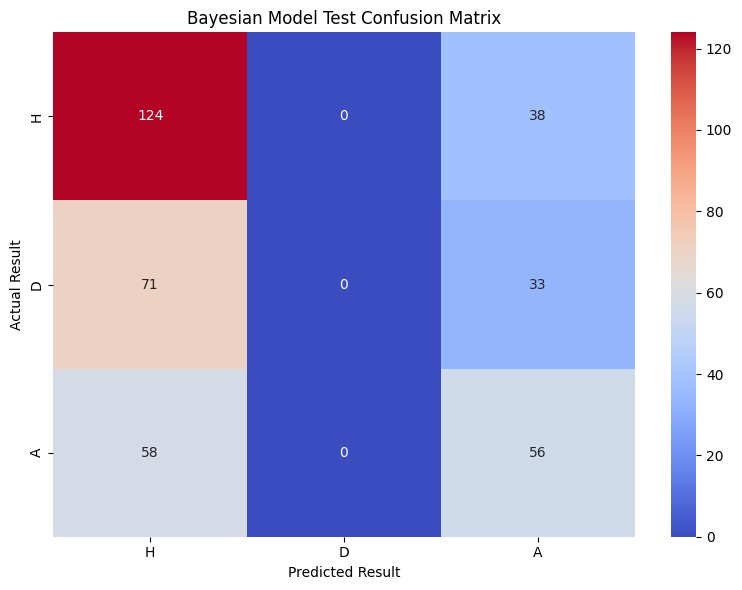

In [186]:
#plot

plt.figure(figsize = (8, 6))
sns.heatmap(
    bayesian_test_confusion_df, annot = True,
    fmt = "d", cmap = "coolwarm"
)

plt.title("Bayesian Model Test Confusion Matrix")
plt.xlabel("Predicted Result")
plt.ylabel("Actual Result")
plt.tight_layout()
plt.show()

In [187]:
#save table

bayesian_test_results.to_csv("Bayesian 2025-26 Match Predictions.csv", index = False)

# Monte Carlo Simulation of the 2025/26 League Table

## Actual 2025/26 table

In [188]:
#actual 2025/26 table

season_2526 = premier_league[
    premier_league["Season"] == "2025/26"
].copy()

table_2526 = build_league_table(
    season_2526
)

table_2526

,Position,Team,Played,Wins,Draws,Losses,GoalsFor,GoalsAgainst,GoalDifference,Points
0,1,Arsenal,38,26,7,5,71,27,44,85
1,2,Man City,38,23,9,6,77,35,42,78
2,3,Man United,38,20,11,7,69,50,19,71
3,4,Aston Villa,38,19,8,11,56,49,7,65
4,5,Liverpool,38,17,9,12,63,53,10,60
5,6,Bournemouth,38,13,18,7,58,54,4,57
6,7,Sunderland,38,14,12,12,42,48,-6,54
7,8,Brighton,38,14,11,13,52,46,6,53
8,9,Brentford,38,14,11,13,55,52,3,53
9,10,Chelsea,38,14,10,14,58,52,6,52


## Machine Learning Simulation

In [189]:
#function to simulate a season

def simulate_one_season(match_prediction):

  teams = sorted(
      set(match_prediction["HomeTeam"]).union(set(match_prediction["AwayTeam"]))
  )

  table = pd.DataFrame({
      "Team": teams,
      "Played": 0,
      "Wins": 0,
      "Draws": 0,
      "Losses": 0,
      "Points": 0
  })

  table = table.set_index("Team")

  #simulate each match and update the table
  for index, row in match_prediction.iterrows():

    home_team = row["HomeTeam"]
    away_team = row["AwayTeam"]

    probabilities = [
        row["Prob_HomeWin"],
        row["Prob_Draw"],
        row["Prob_AwayWin"]
    ]

    result = np.random.choice(
        ["H", "D", "A"],
        p = probabilities
    )

    table.loc[home_team, "Played"] += 1
    table.loc[away_team, "Played"] += 1

    #record outcome of each match
    if result == "H":
      table.loc[home_team, "Wins"] += 1
      table.loc[away_team, "Losses"] += 1
      table.loc[home_team, "Points"] += 3

    elif result == "D":
      table.loc[home_team, "Draws"] += 1
      table.loc[away_team, "Draws"] += 1
      table.loc[home_team, "Points"] += 1
      table.loc[away_team, "Points"] += 1

    else:
      table.loc[home_team, "Losses"] += 1
      table.loc[away_team, "Wins"] += 1
      table.loc[away_team, "Points"] += 3

  table["TieBreaker"] = np.random.random(len(table))

  table = table.sort_values(
      by = ["Points", "TieBreaker"],
      ascending = [False, False]
  )

  #assign final league positions and remove the temporary tie-breaker
  table["Position"] = range(1, len(table) + 1)

  table = table.drop(columns = ["TieBreaker"])

  table = table.reset_index()

  return table

In [190]:
#one simulation of the table

np.random.seed(42)
one_simulation = simulate_one_season(test_results)

one_simulation

,Team,Played,Wins,Draws,Losses,Points,Position
0,Man City,38,25,6,7,81,1
1,Bournemouth,38,21,5,12,68,2
2,Arsenal,38,19,11,8,68,3
3,Newcastle,38,20,6,12,66,4
4,Liverpool,38,19,7,12,64,5
5,Chelsea,38,17,9,12,60,6
6,West Ham,38,17,6,15,57,7
7,Brentford,38,15,11,12,56,8
8,Everton,38,15,11,12,56,9
9,Brighton,38,15,8,15,53,10


In [191]:
#simulate multiple times

np.random.seed(42)
num_simulations = 10000

simulation_results = []

for simulation in range(num_simulations):

  simulated_table = simulate_one_season(test_results)
  simulated_table["Simulation"] = simulation + 1

  simulation_results.append(simulated_table)

simulation_results = pd.concat(simulation_results, ignore_index = True)

simulation_results.head()

,Team,Played,Wins,Draws,Losses,Points,Position,Simulation
0,Man City,38,25,6,7,81,1,1
1,Bournemouth,38,21,5,12,68,2,1
2,Arsenal,38,19,11,8,68,3,1
3,Newcastle,38,20,6,12,66,4,1
4,Liverpool,38,19,7,12,64,5,1


In [192]:
#Summary

simulation_summary = simulation_results.groupby("Team").agg(
    ExpectedPoints = ("Points", "mean"),
    AveragePosition = ("Position", "mean"),
    Position5thPercentile = (
        "Position",
        lambda positions: positions.quantile(0.05, interpolation="nearest")
    ),

    Position95thPercentile = (
        "Position",
        lambda positions: positions.quantile(0.95, interpolation="nearest")
    ),
    AverageWins = ("Wins", "mean"),
    AverageDraws = ("Draws", "mean"),
    AverageLosses = ("Losses", "mean")
).reset_index()

simulation_summary = simulation_summary.sort_values(
    "ExpectedPoints",
    ascending = False
)

simulation_summary

,Team,ExpectedPoints,AveragePosition,Position5thPercentile,Position95thPercentile,AverageWins,AverageDraws,AverageLosses
11,Liverpool,74.0566,2.5140,1,6,22.1292,7.6690,8.2018
12,Man City,73.4763,2.6305,1,6,21.7539,8.2146,8.0315
0,Arsenal,72.9556,2.7556,1,6,21.5940,8.1736,8.2324
6,Chelsea,63.4693,5.6159,2,12,18.1307,9.0772,10.7921
14,Newcastle,57.9671,7.8648,3,15,16.3463,8.9282,12.7255
4,Brighton,57.1176,8.2680,3,15,15.9965,9.1281,12.8754
7,Crystal Palace,56.8910,8.3441,3,15,15.8220,9.4250,12.7530
1,Aston Villa,56.5746,8.4900,3,15,15.7533,9.3147,12.9320
2,Bournemouth,54.5031,9.4680,4,16,15.0467,9.3630,13.5903
8,Everton,51.2096,11.0434,5,17,13.8884,9.5444,14.5672


In [193]:
#Probability of title, top 4 and relegation

title_probability = (
    simulation_results[simulation_results["Position"] == 1]
    .groupby("Team")
    .size()
    .div(num_simulations)
    .mul(100)
)

top4_probability = (
    simulation_results[simulation_results["Position"] <= 4]
    .groupby("Team")
    .size()
    .div(num_simulations)
    .mul(100)
)

relegation_probability = (
    simulation_results[simulation_results["Position"] >= 18]
    .groupby("Team")
    .size()
    .div(num_simulations)
    .mul(100)
)

In [194]:
#add to simulation summary

simulation_summary["TitleProbability"] = (
    simulation_summary["Team"].map(title_probability).fillna(0)
)

simulation_summary["Top4Probability"] = (
    simulation_summary["Team"].map(top4_probability).fillna(0)
)

simulation_summary["RelegationProbability"] = (
    simulation_summary["Team"].map(relegation_probability).fillna(0)
)


In [195]:
#final predicted table

predicted_2526_table = simulation_summary.sort_values(
    "ExpectedPoints",
    ascending = False
).reset_index(drop = True)

predicted_2526_table["PredictedPosition"] = range(1, len(predicted_2526_table) + 1)

predicted_2526_table = predicted_2526_table[
    [
        "PredictedPosition",
        "Team",
        "ExpectedPoints",
        "AveragePosition",
        "Position5thPercentile",
        "Position95thPercentile",
        "AverageWins",
        "AverageDraws",
        "AverageLosses",
        "TitleProbability",
        "Top4Probability",
        "RelegationProbability"
    ]
]

In [196]:
#round to 2 decimals
predicted_2526_table = predicted_2526_table.round({
    "ExpectedPoints": 2,
    "AveragePosition": 2,
    "AverageWins": 2,
    "AverageDraws": 2,
    "AverageLosses": 2,
    "TitleProbability": 2,
    "Top4Probability": 2,
    "RelegationProbability": 2
})

predicted_2526_table

,PredictedPosition,Team,ExpectedPoints,AveragePosition,Position5thPercentile,Position95thPercentile,AverageWins,AverageDraws,AverageLosses,TitleProbability,Top4Probability,RelegationProbability
0,1,Liverpool,74.06,2.51,1,6,22.13,7.67,8.20,33.66,88.72,0.00
1,2,Man City,73.48,2.63,1,6,21.75,8.21,8.03,30.35,87.71,0.00
2,3,Arsenal,72.96,2.76,1,6,21.59,8.17,8.23,27.61,86.13,0.00
3,4,Chelsea,63.47,5.62,2,12,18.13,9.08,10.79,4.24,42.75,0.03
4,5,Newcastle,57.97,7.86,3,15,16.35,8.93,12.73,0.99,18.88,0.45
5,6,Brighton,57.12,8.27,3,15,16.00,9.13,12.88,1.02,16.51,0.61
6,7,Crystal Palace,56.89,8.34,3,15,15.82,9.43,12.75,0.77,14.68,0.66
7,8,Aston Villa,56.57,8.49,3,15,15.75,9.31,12.93,0.56,14.14,0.89
8,9,Bournemouth,54.50,9.47,4,16,15.05,9.36,13.59,0.31,9.95,1.47
9,10,Everton,51.21,11.04,5,17,13.89,9.54,14.57,0.16,4.61,3.19


In [197]:
#save simulated table

predicted_2526_table.to_csv(
    "Machine Learning Simulation 2025-26 table.csv", index = False
)

In [198]:
#compare predicted and actual

table_comparison = predicted_2526_table[
    [
        "Team",
        "PredictedPosition",
        "ExpectedPoints",
        "TitleProbability"
    ]
].merge(
    table_2526[
        [
            "Team",
            "Position",
            "Points"
        ]
    ],
    on = "Team",
    how = "inner"
)

table_comparison = table_comparison.rename(
    columns = {
        "Position": "ActualPosition",
        "Points": "ActualPoints"
    }
)

table_comparison["PositionError"] = (
    table_comparison["PredictedPosition"] -
    table_comparison["ActualPosition"]
).abs()

table_comparison["PointsError"] = (
    table_comparison["ExpectedPoints"] -
    table_comparison["ActualPoints"]
).abs()

table_comparison = table_comparison.sort_values(
    "ActualPosition"
).reset_index(drop = True)

table_comparison

,Team,PredictedPosition,ExpectedPoints,TitleProbability,ActualPosition,ActualPoints,PositionError,PointsError
0,Arsenal,3,72.96,27.61,1,85,2,12.04
1,Man City,2,73.48,30.35,2,78,0,4.52
2,Man United,11,50.97,0.11,3,71,8,20.03
3,Aston Villa,8,56.57,0.56,4,65,4,8.43
4,Liverpool,1,74.06,33.66,5,60,4,14.06
5,Bournemouth,9,54.50,0.31,6,57,3,2.50
6,Sunderland,18,34.03,0.00,7,54,11,19.97
7,Brighton,6,57.12,1.02,8,53,2,4.12
8,Brentford,12,50.20,0.07,9,53,3,2.80
9,Chelsea,4,63.47,4.24,10,52,6,11.47


In [199]:
#MAE and spearman

position_mae = (
    table_comparison["PositionError"].mean()
)

points_mae = (
    table_comparison["PointsError"].mean()
)

spearman_correlation = (
    table_comparison[
        [
            "PredictedPosition",
            "ActualPosition"
        ]
    ].corr(method = "spearman").iloc[0, 1]
)

print("Position MAE:", round(position_mae, 2))
print("Points MAE:", round(points_mae, 2))
print("Spearman rank correlation:", round(spearman_correlation,3))

Position MAE: 3.9
Points MAE: 9.3
Spearman rank correlation: 0.657


In [200]:
predicted_champion = (
    simulation_summary
    .sort_values(by = ["TitleProbability", "ExpectedPoints"],
                 ascending = [False, False])
    .iloc[0]["Team"]
)

actual_champion = (
    table_comparison
    .sort_values("ActualPosition")
    .iloc[0]["Team"]
)

print("ML Predicted champion:", predicted_champion)
print("Actual champion:", actual_champion)

ML Predicted champion: Liverpool
Actual champion: Arsenal


In [201]:
#top four evaluation
predicted_top4 = set(
    table_comparison.nsmallest(
        4,
        "PredictedPosition"
    )["Team"]
)

actual_top4 = set(
    table_comparison.nsmallest(
        4,
        "ActualPosition"
    )["Team"]
)

top4_overlap = len(
    predicted_top4.intersection(actual_top4)
)

print("Top-four overlap:", top4_overlap, "out of 4")

Top-four overlap: 2 out of 4


In [202]:
#evaluation of relegation

predicted_relegated = set(
    table_comparison.nlargest(
        3,
        "PredictedPosition"
    )["Team"]
)

actual_relegated = set(
    table_comparison.nlargest(
        3,
        "ActualPosition"
    )["Team"]
)

relegation_overlap = len(
    predicted_relegated.intersection(
        actual_relegated
    )
)

print("Relegation overlap:", relegation_overlap, "out of 3")

Relegation overlap: 1 out of 3


In [203]:
#save comparison table

table_comparison.to_csv("Machine Learning Predicted vs Actual 2025-26 Table.csv", index = False)

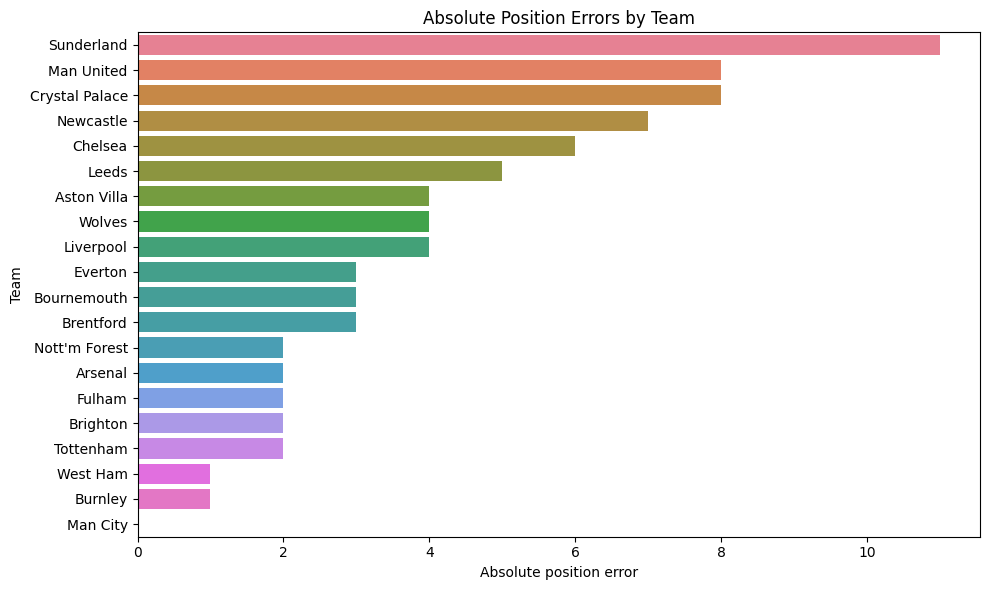

In [204]:
#errors plot

position_errors = table_comparison.sort_values(
    "PositionError",
    ascending=False
)

plt.figure(figsize=(10, 6))
sns.barplot(
    data = position_errors,
    x = "PositionError",
    y = "Team",
    hue = "Team",
    legend = False
)

plt.title("Absolute Position Errors by Team")
plt.xlabel("Absolute position error")
plt.ylabel("Team")
plt.tight_layout()
plt.show()

## Standard Poisson Simulation

In [205]:
#create simulation table for poisson

def simulate_poisson_season(match_predictions):

    teams = sorted(set(match_predictions["HomeTeam"])
    .union(set(match_predictions["AwayTeam"])))

    #Each team starts at 0

    team_stats = {}

    for team in teams:
        team_stats[team] ={
            "Played": 0,
            "Wins": 0,
            "Draws": 0,
            "Losses": 0,
            "GF": 0,
            "GA": 0,
            "Points": 0
        }

    #Simulate each match
    for row in match_predictions.itertuples():
        home_team = row.HomeTeam
        away_team = row.AwayTeam

        simulated_home_goals = np.random.poisson(row.ExpectedHomeGoals)
        simulated_away_goals = np.random.poisson(row.ExpectedAwayGoals)

        team_stats[home_team]["Played"] += 1
        team_stats[away_team]["Played"] += 1

        team_stats[home_team]["GF"] += simulated_home_goals
        team_stats[home_team]["GA"] += simulated_away_goals
        team_stats[away_team]["GF"] += simulated_away_goals
        team_stats[away_team]["GA"] += simulated_home_goals

        #Match outcomes
        if simulated_home_goals > simulated_away_goals:

            team_stats[home_team]["Wins"] += 1
            team_stats[away_team]["Losses"] += 1
            team_stats[home_team]["Points"] += 3

        elif simulated_home_goals < simulated_away_goals:
            team_stats[away_team]["Wins"] += 1
            team_stats[home_team]["Losses"] += 1
            team_stats[away_team]["Points"] += 3

        else:
            team_stats[home_team]["Draws"] += 1
            team_stats[away_team]["Draws"] += 1
            team_stats[home_team]["Points"] += 1
            team_stats[away_team]["Points"] += 1

    #Convert into a Data frame

    simulated_table = pd.DataFrame.from_dict(
        team_stats, orient = "index"
    )

    simulated_table = (
        simulated_table.reset_index()
        .rename(columns = {"index": "Team"})
    )

    #Goal difference
    simulated_table["GD"] = (
        simulated_table["GF"] - simulated_table["GA"]
    )

    #sort by points, goal difference then goals for

    simulated_table = simulated_table.sort_values(
            ["Points", "GD", "GF"],
            ascending  = [False, False, False]
        ).reset_index(drop = True)

    simulated_table["Position"] = range(1, len(simulated_table) + 1)

    return simulated_table

In [206]:
#one simulation

np.random.seed(42)
example_poisson_table = simulate_poisson_season(poisson_test_results)

example_poisson_table

,Team,Played,Wins,Draws,Losses,GF,GA,Points,GD,Position
0,Arsenal,38,25,7,6,82,39,82,43,1
1,Man City,38,23,7,8,67,42,76,25,2
2,Chelsea,38,21,5,12,62,41,68,21,3
3,Aston Villa,38,20,4,14,63,51,64,12,4
4,Man United,38,19,7,12,55,44,64,11,5
5,Brentford,38,18,9,11,59,52,63,7,6
6,Newcastle,38,18,7,13,71,55,61,16,7
7,Liverpool,38,17,7,14,66,55,58,11,8
8,Nott'm Forest,38,14,12,12,54,43,54,11,9
9,Brighton,38,14,12,12,57,56,54,1,10


In [207]:
#full simulation

np.random.seed(42)
num_poisson_simulations = 10000

poisson_simulation_tables = []

for simulation in range(num_poisson_simulations):
    simulated_table = simulate_poisson_season(poisson_test_results)

    simulated_table["Simulation"] = simulation + 1

    poisson_simulation_tables.append(simulated_table)

poisson_simulation_results = pd.concat(
    poisson_simulation_tables, ignore_index = True
)

poisson_simulation_results.head()

,Team,Played,Wins,Draws,Losses,GF,GA,Points,GD,Position,Simulation
0,Arsenal,38,25,7,6,82,39,82,43,1,1
1,Man City,38,23,7,8,67,42,76,25,2,1
2,Chelsea,38,21,5,12,62,41,68,21,3,1
3,Aston Villa,38,20,4,14,63,51,64,12,4,1
4,Man United,38,19,7,12,55,44,64,11,5,1


In [208]:
#summary

poisson_simulation_summary = (poisson_simulation_results.groupby("Team")
  .agg(ExpectedPoints = ("Points", "mean"),
       AveragePosition = ("Position", "mean"),
       Position5thPercentile = (
           "Position",
           lambda positions: positions.quantile(0.05, interpolation="nearest")
        ),
       Position95thPercentile = (
           "Position",
           lambda positions: positions.quantile(0.95, interpolation="nearest")
        ),
       ExpectedWins = ("Wins", "mean"),
       ExpectedDraws = ("Draws", "mean"),
       ExpectedLosses = ("Losses", "mean"),
       ExpectedGF = ("GF", "mean"),
       ExpectedGA = ("GA", "mean"),
       ExpectedGD = ("GD", "mean")
       ).reset_index()
       )

In [209]:
#Probabilities

poisson_title_probability = (
    poisson_simulation_results[poisson_simulation_results["Position"] == 1]
    .groupby("Team")
    .size()
    .div(num_poisson_simulations)
    .mul(100)
)

poisson_top4_probability = (
    poisson_simulation_results[poisson_simulation_results["Position"] <= 4]
    .groupby("Team")
    .size()
    .div(num_poisson_simulations)
    .mul(100)
)

poisson_relegation_probability = (
    poisson_simulation_results[poisson_simulation_results["Position"] >= 18]
    .groupby("Team")
    .size()
    .div(num_poisson_simulations)
    .mul(100)
)

In [210]:
#add to simulation summary

poisson_simulation_summary["TitleProbability"] = (
    poisson_simulation_summary["Team"].map(poisson_title_probability).fillna(0)
)

poisson_simulation_summary["Top4Probability"] = (
    poisson_simulation_summary["Team"].map(poisson_top4_probability).fillna(0)
)

poisson_simulation_summary["RelegationProbability"] = (
    poisson_simulation_summary["Team"].map(poisson_relegation_probability).fillna(0)
)

In [211]:
#create table

poisson_predicted_table = (
    poisson_simulation_summary.sort_values([
        "ExpectedPoints", "ExpectedGD", "ExpectedGF"
    ], ascending = [False, False, False]).reset_index(drop = True)
)

poisson_predicted_table["PredictedPosition"] = range(
    1, len(poisson_predicted_table) + 1
)

poisson_predicted_table = (poisson_predicted_table[[
    "PredictedPosition", "Team", "ExpectedPoints", "AveragePosition",
    "Position5thPercentile", "Position95thPercentile", "ExpectedWins", "ExpectedDraws",
    "ExpectedLosses", "ExpectedGF", "ExpectedGA", "ExpectedGD",
    "TitleProbability", "Top4Probability", "RelegationProbability"
]])

poisson_predicted_table = (poisson_predicted_table.round(2))

poisson_predicted_table

,PredictedPosition,Team,ExpectedPoints,AveragePosition,Position5thPercentile,Position95thPercentile,ExpectedWins,ExpectedDraws,ExpectedLosses,ExpectedGF,ExpectedGA,ExpectedGD,TitleProbability,Top4Probability,RelegationProbability
0,1,Liverpool,72.13,2.59,1,7,21.33,8.14,8.53,72.99,41.70,31.29,41.00,85.27,0.00
1,2,Arsenal,68.17,3.72,1,9,19.87,8.57,9.57,67.54,42.91,24.63,21.35,70.36,0.02
2,3,Man City,67.13,4.08,1,10,19.51,8.60,9.89,66.95,44.07,22.88,17.54,65.41,0.00
3,4,Chelsea,63.28,5.56,1,12,18.14,8.86,11.00,62.73,46.01,16.73,7.74,45.65,0.09
4,5,Newcastle,60.23,6.91,2,14,17.07,9.03,11.91,59.76,47.81,11.95,3.87,30.19,0.27
5,6,Aston Villa,58.37,7.79,2,15,16.42,9.12,12.46,57.94,48.97,8.97,2.54,22.66,0.42
6,7,Brighton,57.41,8.26,2,15,16.11,9.08,12.81,57.63,50.14,7.50,1.75,18.99,0.64
7,8,Nott'm Forest,56.38,8.75,3,15,15.72,9.24,13.05,55.85,49.78,6.07,1.40,15.27,0.73
8,9,Bournemouth,55.67,9.10,3,16,15.47,9.27,13.26,55.25,50.36,4.89,1.13,14.04,1.00
9,10,Brentford,53.60,10.15,4,17,14.78,9.26,13.96,54.03,52.36,1.67,0.55,8.64,1.85


In [212]:
#save table

poisson_predicted_table.to_csv("Poisson Predicted 2025-26 Table.csv", index = False)

In [213]:
#compare to actual table

poisson_table_comparison = (poisson_predicted_table[[
    "Team", "PredictedPosition", "ExpectedPoints"
]].merge(table_2526[[
    "Team", "Position", "Points"
]], on = "Team", how = "inner"))

#rename columns
poisson_table_comparison = poisson_table_comparison.rename(columns = {
    "Position": "ActualPosition",
    "Points": "ActualPoints"
})

poisson_table_comparison

,Team,PredictedPosition,ExpectedPoints,ActualPosition,ActualPoints
0,Liverpool,1,72.13,5,60
1,Arsenal,2,68.17,1,85
2,Man City,3,67.13,2,78
3,Chelsea,4,63.28,10,52
4,Newcastle,5,60.23,12,49
5,Aston Villa,6,58.37,4,65
6,Brighton,7,57.41,8,53
7,Nott'm Forest,8,56.38,16,44
8,Bournemouth,9,55.67,6,57
9,Brentford,10,53.60,9,53


In [214]:
#errors between actual and predicted

poisson_table_comparison["PositionError"] = (
    poisson_table_comparison["PredictedPosition"]
    - poisson_table_comparison["ActualPosition"]
).abs()

poisson_table_comparison["PointsError"] = (
    poisson_table_comparison["ExpectedPoints"]
    - poisson_table_comparison["ActualPoints"]
).abs()

In [215]:
#mean absolute errors and Spearman correlation

poisson_position_mae = (poisson_table_comparison["PositionError"].mean())

poisson_points_mae = (poisson_table_comparison["PointsError"].mean())

poisson_spearman = (poisson_table_comparison[[
    "PredictedPosition", "ActualPosition"
]].corr(method = "spearman").iloc[0, 1])

print("Poisson MAE Position:", round(poisson_position_mae, 2))
print("Poisson MAE Points:", round(poisson_points_mae, 2))
print("Poisson Spearman Correlation:", round(poisson_spearman, 3))

Poisson MAE Position: 3.7
Poisson MAE Points: 10.16
Poisson Spearman Correlation: 0.633


In [216]:
#champion evaluation

poisson_predicted_champion = (
    poisson_simulation_summary
    .sort_values(by =["TitleProbability", "ExpectedPoints"],
                 ascending = [False, False])
    .iloc[0]["Team"])
poisson_actual_champion = (
    poisson_table_comparison
    .sort_values("ActualPosition").iloc[0]["Team"])

print("Poisson Predicted Champion:", poisson_predicted_champion)
print("Actual Champion:", poisson_actual_champion)

Poisson Predicted Champion: Liverpool
Actual Champion: Arsenal


In [217]:
#top four evaluation

poisson_predicted_top4 = set(
    poisson_table_comparison.nsmallest(
        4, "PredictedPosition"
    )["Team"]
)

poisson_actual_top4 = set(
    poisson_table_comparison.nsmallest(
        4, "ActualPosition"
    )["Team"]
)

poisson_top4_overlap = len(
    poisson_predicted_top4.intersection(poisson_actual_top4)
)

print("Poisson top 4 overlap:", poisson_top4_overlap, "out of 4")

Poisson top 4 overlap: 2 out of 4


In [218]:
#relegation evaluation

poisson_predicted_relegated = set(
    poisson_table_comparison.nlargest(
        3, "PredictedPosition"
    )["Team"]
)

poisson_actual_relegated = set(
    poisson_table_comparison.nlargest(
        3, "ActualPosition"
    )["Team"]
)

poisson_relegation_overlap = len(
    poisson_predicted_relegated.intersection(poisson_actual_relegated)
)

print("Poisson relegation overlap:", poisson_relegation_overlap, "out of 3")

Poisson relegation overlap: 1 out of 3


In [219]:
#comparison table

poisson_table_comparison.to_csv(
    "Poisson Predicted vs Actual 2025-26 Table.csv", index = False
)

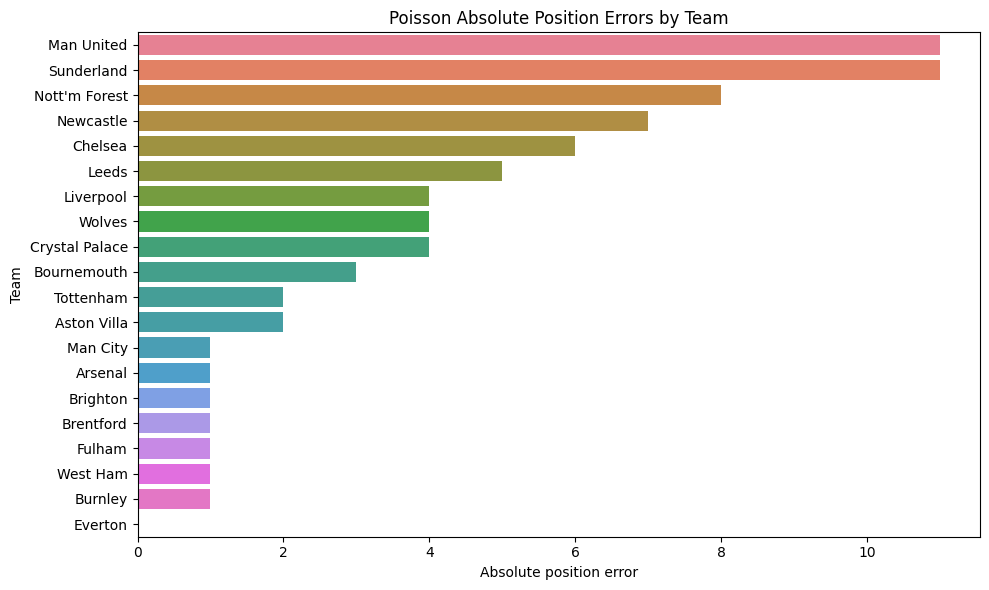

In [220]:
#position error plot

poisson_position_error = (
    poisson_table_comparison.sort_values(
        "PositionError", ascending = False
    )
)

plt.figure(figsize = (10, 6))
sns.barplot(
    data = poisson_position_error,
    x = "PositionError",
    y = "Team",
    hue = "Team",
    legend = False
)

plt.title("Poisson Absolute Position Errors by Team")
plt.xlabel("Absolute position error")
plt.ylabel("Team")
plt.tight_layout()
plt.show()

## Bayesian Simulation

In [221]:
#create simulation for bayesian model

def simulate_bayesian_season(
    match_predictions, bayesian_test_home_rate_draws, bayesian_test_away_rate_draws
):

    teams = sorted(
        set(match_predictions["HomeTeam"]).union(
            set(match_predictions["AwayTeam"])
        )
    )

    #select one posterior draw
    posterior_draw_index = np.random.randint(
        bayesian_test_home_rate_draws.shape[0]
    )

    #each team starts at 0
    team_stats = {}

    for team in teams:
        team_stats[team] = {
            "Played": 0,
            "Wins": 0,
            "Draws": 0,
            "Losses": 0,
            "GF": 0,
            "GA": 0,
            "Points": 0
        }

    #simulate every match
    for match_index, row in enumerate(
        match_predictions.itertuples(index = False)
    ):

        home_team = row.HomeTeam
        away_team = row.AwayTeam

        expected_home_goals = (
            bayesian_test_home_rate_draws[posterior_draw_index, match_index]
        )
        expected_away_goals = (
            bayesian_test_away_rate_draws[posterior_draw_index, match_index]
        )

        simulated_home_goals = np.random.poisson(
            expected_home_goals
        )
        simulated_away_goals = np.random.poisson(
            expected_away_goals
        )

        team_stats[home_team]["Played"] += 1
        team_stats[away_team]["Played"] += 1

        team_stats[home_team]["GF"] += simulated_home_goals
        team_stats[home_team]["GA"] += simulated_away_goals

        team_stats[away_team]["GF"] += simulated_away_goals
        team_stats[away_team]["GA"] += simulated_home_goals

        #match results
        if simulated_home_goals > simulated_away_goals:
            team_stats[home_team]["Wins"] += 1
            team_stats[away_team]["Losses"] += 1
            team_stats[home_team]["Points"] += 3

        elif simulated_home_goals < simulated_away_goals:

            team_stats[away_team]["Wins"] += 1
            team_stats[home_team]["Losses"] += 1
            team_stats[away_team]["Points"] += 3

        else:

            team_stats[home_team]["Draws"] += 1
            team_stats[away_team]["Draws"] += 1
            team_stats[home_team]["Points"] += 1
            team_stats[away_team]["Points"] += 1

    #convert into DataFrame

    simulated_table = pd.DataFrame.from_dict(
        team_stats, orient = "index"
    )
    simulated_table = (
        simulated_table.reset_index()
        .rename(columns = {"index": "Team"})
    )

    simulated_table["GD"] = (
        simulated_table["GF"] - simulated_table["GA"]
    )

    #rank by points, GD and GF
    simulated_table = simulated_table.sort_values(
        ["Points", "GD", "GF"],
        ascending = [False, False, False]
    ).reset_index(drop = True)

    simulated_table["Position"] = range(
        1, len(simulated_table) + 1
    )

    return simulated_table

In [222]:
#one simulation

np.random.seed(42)
example_bayesian_table = simulate_bayesian_season(
    bayesian_test_results, bayesian_test_home_rate_draws,
    bayesian_test_away_rate_draws
)

example_bayesian_table

,Team,Played,Wins,Draws,Losses,GF,GA,Points,GD,Position
0,Liverpool,38,22,9,7,68,36,75,32,1
1,Chelsea,38,18,15,5,60,42,69,18,2
2,Arsenal,38,18,12,8,72,46,66,26,3
3,Man City,38,18,9,11,65,44,63,21,4
4,Crystal Palace,38,16,14,8,70,43,62,27,5
5,Bournemouth,38,18,8,12,60,56,62,4,6
6,Brentford,38,17,10,11,64,58,61,6,7
7,Man United,38,17,9,12,61,52,60,9,8
8,Tottenham,38,15,10,13,58,51,55,7,9
9,Nott'm Forest,38,14,12,12,51,55,54,-4,10


In [223]:
#multiple simulations

np.random.seed(42)

num_bayesian_simulations = 10000

bayesian_simulation_tables = []

for simulation in range(num_bayesian_simulations):
    simulated_table = simulate_bayesian_season(
        bayesian_test_results, bayesian_test_home_rate_draws,
        bayesian_test_away_rate_draws
    )
    simulated_table["Simulation"] = simulation + 1
    bayesian_simulation_tables.append(simulated_table)

bayesian_simulation_results = pd.concat(
    bayesian_simulation_tables, ignore_index = True
)

bayesian_simulation_results.head()

,Team,Played,Wins,Draws,Losses,GF,GA,Points,GD,Position,Simulation
0,Liverpool,38,22,9,7,68,36,75,32,1,1
1,Chelsea,38,18,15,5,60,42,69,18,2,1
2,Arsenal,38,18,12,8,72,46,66,26,3,1
3,Man City,38,18,9,11,65,44,63,21,4,1
4,Crystal Palace,38,16,14,8,70,43,62,27,5,1


In [224]:
#bayesian simulation summary

bayesian_simulation_summary = (
    bayesian_simulation_results.groupby("Team").agg(
        ExpectedPoints = ("Points", "mean"),
        AveragePosition = ("Position", "mean"),
        Position5thPercentile = (
            "Position",
            lambda positions: positions.quantile(0.05, interpolation="nearest")
            ),
        Position95thPercentile = (
            "Position",
            lambda positions: positions.quantile(0.95, interpolation="nearest")
        ),
        ExpectedWins = ("Wins", "mean"),
        ExpectedDraws = ("Draws", "mean"),
        ExpectedLosses = ("Losses", "mean"),
        ExpectedGF = ("GF", "mean"),
        ExpectedGA = ("GA", "mean"),
        ExpectedGD = ("GD", "mean")
    ).reset_index()
)

bayesian_simulation_summary = (
    bayesian_simulation_summary.sort_values(
        "ExpectedPoints", ascending = False
    )
)

bayesian_simulation_summary

,Team,ExpectedPoints,AveragePosition,Position5thPercentile,Position95thPercentile,ExpectedWins,ExpectedDraws,ExpectedLosses,ExpectedGF,ExpectedGA,ExpectedGD
12,Man City,73.0537,2.6182,1,6,21.6987,7.9576,8.3437,75.3137,42.1813,33.1324
11,Liverpool,72.8495,2.6708,1,6,21.6295,7.9610,8.4095,75.1933,42.3149,32.8784
0,Arsenal,72.2273,2.7936,1,6,21.3547,8.1632,8.4821,72.2310,40.8363,31.3947
6,Chelsea,63.2893,5.5432,2,12,18.1399,8.8696,10.9905,63.0835,46.5462,16.5373
14,Newcastle,58.5662,7.5115,3,14,16.4874,9.1040,12.4086,58.6072,49.2849,9.3223
4,Brighton,56.7159,8.3445,3,15,15.9099,8.9862,13.1039,59.0618,52.5616,6.5002
1,Aston Villa,56.2899,8.5445,3,15,15.7280,9.1059,13.1661,57.2496,51.5255,5.7241
7,Crystal Palace,55.3373,8.9861,3,16,15.3807,9.1952,13.4241,55.6098,51.3220,4.2878
2,Bournemouth,54.8183,9.2122,3,16,15.1608,9.3359,13.5033,54.2024,50.6795,3.5229
3,Brentford,50.8186,11.2164,5,18,13.8771,9.1873,14.9356,52.3614,55.0395,-2.6781


In [225]:
#title, top 4 and relegation probabilities

bayesian_title_probability = (
    bayesian_simulation_results[
        bayesian_simulation_results["Position"] == 1
    ].groupby("Team").size().div(num_bayesian_simulations).mul(100)
)

bayesian_top4_probability = (
    bayesian_simulation_results[
        bayesian_simulation_results["Position"] <= 4
    ].groupby("Team").size().div(num_bayesian_simulations).mul(100)
)

bayesian_relegation_probability = (
    bayesian_simulation_results[
        bayesian_simulation_results["Position"] >= 18
    ].groupby("Team").size().div(num_bayesian_simulations).mul(100)
)

In [226]:
#add to table

bayesian_simulation_summary["TitleProbability"] = (
    bayesian_simulation_summary["Team"]
    .map(bayesian_title_probability).fillna(0)
)

bayesian_simulation_summary["Top4Probability"] = (
    bayesian_simulation_summary["Team"]
    .map(bayesian_top4_probability).fillna(0)
)

bayesian_simulation_summary["RelegationProbability"] = (
    bayesian_simulation_summary["Team"]
    .map(bayesian_relegation_probability).fillna(0)
)

In [228]:
#create predicted table

bayesian_predicted_table = (
    bayesian_simulation_summary.sort_values(
        ["ExpectedPoints", "ExpectedGD", "ExpectedGF"],
        ascending = [False, False, False]
    ).reset_index(drop = True)
)

bayesian_predicted_table["PredictedPosition"] = range(
    1, len(bayesian_predicted_table) + 1
)

bayesian_predicted_table = bayesian_predicted_table[
    ["PredictedPosition", "Team", "ExpectedPoints", "AveragePosition",
     "Position5thPercentile", "Position95thPercentile", "ExpectedWins", "ExpectedDraws",
     "ExpectedLosses", "ExpectedGF", "ExpectedGA", "ExpectedGD",
     "TitleProbability", "Top4Probability", "RelegationProbability"]
]

bayesian_predicted_table = (bayesian_predicted_table.round(2))

bayesian_predicted_table

,PredictedPosition,Team,ExpectedPoints,AveragePosition,Position5thPercentile,Position95thPercentile,ExpectedWins,ExpectedDraws,ExpectedLosses,ExpectedGF,ExpectedGA,ExpectedGD,TitleProbability,Top4Probability,RelegationProbability
0,1,Man City,73.05,2.62,1,6,21.70,7.96,8.34,75.31,42.18,33.13,32.82,87.10,0.00
1,2,Liverpool,72.85,2.67,1,6,21.63,7.96,8.41,75.19,42.31,32.88,31.17,86.73,0.00
2,3,Arsenal,72.23,2.79,1,6,21.35,8.16,8.48,72.23,40.84,31.39,27.18,85.36,0.00
3,4,Chelsea,63.29,5.54,2,12,18.14,8.87,10.99,63.08,46.55,16.54,4.65,43.85,0.10
4,5,Newcastle,58.57,7.51,3,14,16.49,9.10,12.41,58.61,49.28,9.32,1.36,22.01,0.55
5,6,Brighton,56.72,8.34,3,15,15.91,8.99,13.10,59.06,52.56,6.50,0.73,16.01,0.92
6,7,Aston Villa,56.29,8.54,3,15,15.73,9.11,13.17,57.25,51.53,5.72,0.72,14.64,1.01
7,8,Crystal Palace,55.34,8.99,3,16,15.38,9.20,13.42,55.61,51.32,4.29,0.41,12.08,1.21
8,9,Bournemouth,54.82,9.21,3,16,15.16,9.34,13.50,54.20,50.68,3.52,0.49,10.93,1.65
9,10,Brentford,50.82,11.22,5,18,13.88,9.19,14.94,52.36,55.04,-2.68,0.14,4.60,5.11


In [229]:
#save predicted table

bayesian_predicted_table.to_csv(
    "Bayesian Predicted 2025-26 Table.csv", index = False
)

In [230]:
#compare predicted and actual

bayesian_table_comparison = (bayesian_predicted_table[
    ["Team", "PredictedPosition", "ExpectedPoints"]
].merge(table_2526[
    ["Team", "Position", "Points"]
], on = "Team", how = "inner")
)

bayesian_table_comparison = (bayesian_table_comparison.rename(
    columns = {"Position": "ActualPosition",
               "Points": "ActualPoints"}
)
)

bayesian_table_comparison

,Team,PredictedPosition,ExpectedPoints,ActualPosition,ActualPoints
0,Man City,1,73.05,2,78
1,Liverpool,2,72.85,5,60
2,Arsenal,3,72.23,1,85
3,Chelsea,4,63.29,10,52
4,Newcastle,5,58.57,12,49
5,Brighton,6,56.72,8,53
6,Aston Villa,7,56.29,4,65
7,Crystal Palace,8,55.34,15,45
8,Bournemouth,9,54.82,6,57
9,Brentford,10,50.82,9,53


In [231]:
#position and points error

bayesian_table_comparison["PositionError"] = (
    bayesian_table_comparison["PredictedPosition"]
    - bayesian_table_comparison["ActualPosition"]
).abs()

bayesian_table_comparison["PointsError"] = (
    bayesian_table_comparison["ExpectedPoints"]
    - bayesian_table_comparison["ActualPoints"]
).abs()

bayesian_table_comparison = (
    bayesian_table_comparison
    .sort_values("ActualPosition").reset_index(drop = True)
)

bayesian_table_comparison

,Team,PredictedPosition,ExpectedPoints,ActualPosition,ActualPoints,PositionError,PointsError
0,Arsenal,3,72.23,1,85,2,12.77
1,Man City,1,73.05,2,78,1,4.95
2,Man United,12,49.79,3,71,9,21.21
3,Aston Villa,7,56.29,4,65,3,8.71
4,Liverpool,2,72.85,5,60,3,12.85
5,Bournemouth,9,54.82,6,57,3,2.18
6,Sunderland,18,35.85,7,54,11,18.15
7,Brighton,6,56.72,8,53,2,3.72
8,Brentford,10,50.82,9,53,1,2.18
9,Chelsea,4,63.29,10,52,6,11.29


In [232]:
#Bayesian MAE and Spearman

bayesian_position_mae = (
    bayesian_table_comparison["PositionError"].mean()
)

bayesian_points_mae = (
    bayesian_table_comparison["PointsError"].mean()
)

bayesian_spearman = (bayesian_table_comparison[
        ["PredictedPosition", "ActualPosition"]
    ].corr(method = "spearman").iloc[0, 1]
)

print("Bayesian position MAE:", round(bayesian_position_mae, 2))
print("Bayesian points MAE:", round(bayesian_points_mae, 2))
print("Bayesian Spearman correlation:", round(bayesian_spearman, 3))

Bayesian position MAE: 3.7
Bayesian points MAE: 9.16
Bayesian Spearman correlation: 0.675


In [263]:
#champion evaluation

bayesian_predicted_champion = (
    bayesian_simulation_summary
    .sort_values(by = ["TitleProbability", "ExpectedPoints"],
                 ascending = [False, False])
    .iloc[0]["Team"]
)

bayesian_actual_champion = (
    bayesian_table_comparison
    .sort_values("ActualPosition").iloc[0]["Team"]
)

print("Bayesian predicted champion:", bayesian_predicted_champion)
print("Actual champion:", bayesian_actual_champion)

Bayesian predicted champion: Man City
Actual champion: Arsenal


In [234]:
#top four evaluation

bayesian_predicted_top4 = set(
    bayesian_table_comparison.nsmallest(
        4, "PredictedPosition")["Team"]
)

bayesian_actual_top4 = set(
    bayesian_table_comparison.nsmallest(
        4, "ActualPosition")["Team"]
)

bayesian_top4_overlap = len(
    bayesian_predicted_top4.intersection(bayesian_actual_top4)
)

print("Bayesian top-four overlap:", bayesian_top4_overlap, "out of 4")

Bayesian top-four overlap: 2 out of 4


In [235]:
#relegation evaluation

bayesian_predicted_relegated = set(
    bayesian_table_comparison.nlargest(
        3, "PredictedPosition")["Team"]
)

bayesian_actual_relegated = set(
    bayesian_table_comparison.nlargest(
        3, "ActualPosition")["Team"]
)

bayesian_relegation_overlap = len(
    bayesian_predicted_relegated.intersection(bayesian_actual_relegated)
)

print("Bayesian relegation overlap:", bayesian_relegation_overlap, "out of 3")

Bayesian relegation overlap: 1 out of 3


In [236]:
#save bayesian comparison table

bayesian_table_comparison.to_csv(
    "Bayesian Predicted vs Actual 2025-26 Table.csv", index = False
)

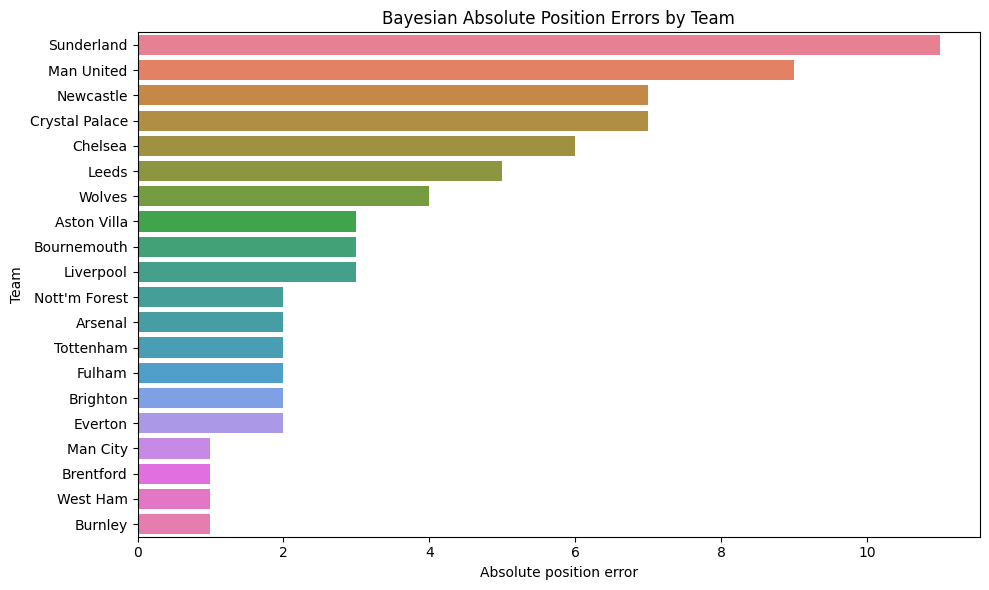

In [237]:
#position error plot

bayesian_position_errors = (
    bayesian_table_comparison
    .sort_values("PositionError", ascending = False)
)

plt.figure(figsize = (10, 6))
sns.barplot(
    data = bayesian_position_errors,
    x = "PositionError",
    y = "Team",
    hue = "Team",
    legend = False
)

plt.title("Bayesian Absolute Position Errors by Team")
plt.xlabel("Absolute position error")
plt.ylabel("Team")
plt.tight_layout()
plt.show()

## Final Model Comparison

In [238]:
#test macro F1 score

final_baseline_macro_f1 = f1_score(
    y_test, final_baseline_predictions, labels=["H", "D", "A"],
    average="macro", zero_division=0
)

test_macro_f1 = f1_score(
    y_test, test_predictions, labels=["H", "D", "A"],
    average="macro", zero_division=0
)

poisson_test_macro_f1 = f1_score(
    y_test, poisson_test_predictions, labels=["H", "D", "A"],
    average="macro", zero_division=0
)

bayesian_test_macro_f1 = f1_score(
    y_test, bayesian_test_predictions, labels=["H", "D", "A"],
    average="macro", zero_division=0
)

print("Baseline test macro F1:", round(final_baseline_macro_f1, 3))
print("ML macro F1:", round(test_macro_f1, 3))
print("Standard Poisson macro F1:", round(poisson_test_macro_f1, 3))
print("Bayesian Poisson macro F1:", round(bayesian_test_macro_f1, 3))

Baseline test macro F1: 0.199
ML macro F1: 0.351
Standard Poisson macro F1: 0.352
Bayesian Poisson macro F1: 0.354


In [239]:
#compare final match prediction models

final_match_model_comparison = pd.DataFrame({
    "Model": [
        "Baseline",
        selected_ml_model_name,
        "Standard Poisson",
        "Bayesian Poisson"
    ],
    "Test Accuracy": [
        final_baseline_accuracy,
        test_accuracy,
        poisson_test_accuracy,
        bayesian_test_accuracy
    ],
    "Test Macro F1": [
        final_baseline_macro_f1,
        test_macro_f1,
        poisson_test_macro_f1,
        bayesian_test_macro_f1
    ],
    "Test Log Loss": [
        final_baseline_log_loss,
        test_log_loss,
        poisson_test_log_loss,
        bayesian_test_log_loss
    ]
})

final_match_model_comparison = (final_match_model_comparison.round(3))

final_match_model_comparison

,Model,Test Accuracy,Test Macro F1,Test Log Loss
0,Baseline,0.426,0.199,1.082
1,Logistic Regression,0.468,0.351,1.039
2,Standard Poisson,0.474,0.352,1.052
3,Bayesian Poisson,0.474,0.354,1.038


In [240]:
#compare final goal prediction models

final_goal_model_comparison = pd.DataFrame({
    "Model": [
        "Standard Poisson",
        "Bayesian Poisson"
    ],
    "Home Goal MAE": [
        poisson_test_home_goal_mae,
        bayesian_test_home_goal_mae
    ],
    "Away Goal MAE": [
        poisson_test_away_goal_mae,
        bayesian_test_away_goal_mae
    ],
    "Total Goal MAE": [
        poisson_test_total_goal_mae,
        bayesian_test_total_goal_mae
    ],
    "Home Goal Deviance": [
        poisson_test_home_deviance,
        bayesian_test_home_deviance
    ],
    "Away Goal Deviance": [
        poisson_test_away_deviance,
        bayesian_test_away_deviance
    ]
})

final_goal_model_comparison = (final_goal_model_comparison.round(3))

final_goal_model_comparison

,Model,Home Goal MAE,Away Goal MAE,Total Goal MAE,Home Goal Deviance,Away Goal Deviance
0,Standard Poisson,0.949,0.851,1.228,1.07,1.091
1,Bayesian Poisson,0.943,0.850,1.235,1.05,1.085


In [241]:
#compare final league simulations

final_simulation_comparison = pd.DataFrame({
    "Model": [
        selected_ml_model_name,
        "Standard Poisson",
        "Bayesian Poisson"
    ],
    "Position MAE": [
        position_mae,
        poisson_position_mae,
        bayesian_position_mae
    ],
    "Points MAE": [
        points_mae,
        poisson_points_mae,
        bayesian_points_mae
    ],
    "Spearman Correlation": [
        spearman_correlation,
        poisson_spearman,
        bayesian_spearman
    ],
    "Predicted Champion": [
        predicted_champion,
        poisson_predicted_champion,
        bayesian_predicted_champion
    ],
    "Champion Correct": [
        "Yes" if predicted_champion == actual_champion else "No",
        "Yes" if poisson_predicted_champion == poisson_actual_champion else "No",
        "Yes" if bayesian_predicted_champion == bayesian_actual_champion else "No"
    ],
    "Top-Four Overlap": [
        top4_overlap,
        poisson_top4_overlap,
        bayesian_top4_overlap
    ],
    "Relegation Overlap": [
        relegation_overlap,
        poisson_relegation_overlap,
        bayesian_relegation_overlap
    ]
})

final_simulation_comparison = (
    final_simulation_comparison.round({
        "Position MAE": 2,
        "Points MAE": 2,
        "Spearman Correlation": 3
    })
)

final_simulation_comparison

,Model,Position MAE,Points MAE,Spearman Correlation,Predicted Champion,Champion Correct,Top-Four Overlap,Relegation Overlap
0,Logistic Regression,3.9,9.30,0.657,Liverpool,No,2,1
1,Standard Poisson,3.7,10.16,0.633,Liverpool,No,2,1
2,Bayesian Poisson,3.7,9.16,0.675,Man City,No,2,1


In [242]:
#prepare predicted positions

ml_team_predictions = predicted_2526_table[
    ["Team", "PredictedPosition", "ExpectedPoints"]
].rename(
    columns = {
        "PredictedPosition": "MLPredictedPosition",
        "ExpectedPoints": "MLExpectedPoints"
    }
)

poisson_team_predictions = poisson_predicted_table[
    ["Team", "PredictedPosition", "ExpectedPoints"]
].rename(
    columns = {
        "PredictedPosition": "PoissonPredictedPosition",
        "ExpectedPoints": "PoissonExpectedPoints"
    }
)

bayesian_team_predictions = bayesian_predicted_table[
    ["Team", "PredictedPosition", "ExpectedPoints"]
].rename(
    columns = {
        "PredictedPosition": "BayesianPredictedPosition",
        "ExpectedPoints": "BayesianExpectedPoints"
    }
)

In [243]:
#combine table

final_team_comparison = table_2526[
    ["Team", "Position", "Points"]
].rename(
    columns = {
        "Position": "ActualPosition",
        "Points": "ActualPoints"
    }
)

final_team_comparison = final_team_comparison.merge(
    ml_team_predictions, on = "Team", how = "inner"
)

final_team_comparison = final_team_comparison.merge(
    poisson_team_predictions, on = "Team", how = "inner"
)

final_team_comparison = final_team_comparison.merge(
    bayesian_team_predictions, on = "Team", how = "inner"
)

In [244]:
#calculate position errors for each model

final_team_comparison["MLPositionError"] = (
    final_team_comparison["MLPredictedPosition"]
    - final_team_comparison["ActualPosition"]
).abs()

final_team_comparison["PoissonPositionError"] = (
    final_team_comparison["PoissonPredictedPosition"]
    - final_team_comparison["ActualPosition"]
).abs()

final_team_comparison["BayesianPositionError"] = (
    final_team_comparison["BayesianPredictedPosition"]
    - final_team_comparison["ActualPosition"]
).abs()

In [245]:
#final team comparison

final_team_comparison = final_team_comparison[
    [
        "ActualPosition",
        "Team",
        "ActualPoints",
        "MLPredictedPosition",
        "MLExpectedPoints",
        "MLPositionError",
        "PoissonPredictedPosition",
        "PoissonExpectedPoints",
        "PoissonPositionError",
        "BayesianPredictedPosition",
        "BayesianExpectedPoints",
        "BayesianPositionError"
    ]
].sort_values("ActualPosition").reset_index(drop = True)

final_team_comparison = final_team_comparison.round(2)

final_team_comparison

,ActualPosition,Team,ActualPoints,MLPredictedPosition,MLExpectedPoints,MLPositionError,PoissonPredictedPosition,PoissonExpectedPoints,PoissonPositionError,BayesianPredictedPosition,BayesianExpectedPoints,BayesianPositionError
0,1,Arsenal,85,3,72.96,2,2,68.17,1,3,72.23,2
1,2,Man City,78,2,73.48,0,3,67.13,1,1,73.05,1
2,3,Man United,71,11,50.97,8,14,48.00,11,12,49.79,9
3,4,Aston Villa,65,8,56.57,4,6,58.37,2,7,56.29,3
4,5,Liverpool,60,1,74.06,4,1,72.13,4,2,72.85,3
5,6,Bournemouth,57,9,54.50,3,9,55.67,3,9,54.82,3
6,7,Sunderland,54,18,34.03,11,18,32.71,11,18,35.85,11
7,8,Brighton,53,6,57.12,2,7,57.41,1,6,56.72,2
8,9,Brentford,53,12,50.20,3,10,53.60,1,10,50.82,1
9,10,Chelsea,52,4,63.47,6,4,63.28,6,4,63.29,6


In [246]:
#save final team comparison

final_team_comparison.to_csv(
    "Final Model League Table Comparison.csv", index = False
)

# Visualisations

In [247]:
#function to visualise a league table

def plot_league_table_points(
    league_table, position_column, points_column, title,
    colour, filename, decimal_places=1
):

    plot_data = (
        league_table
        .sort_values(position_column, ascending = False).copy()
    )

    plot_data["TeamLabel"] = (
        plot_data[position_column].astype(int).astype(str)
        + ". " + plot_data["Team"]
    )

    fig, ax = plt.subplots(figsize=(11, 9))
    bars = ax.barh(
        plot_data["TeamLabel"],
        plot_data[points_column],
        color = colour,
        edgecolor = "black",
        linewidth = 0.4
    )

    value_labels = [
        f"{value:.{decimal_places}f}"
        for value in plot_data[points_column]
    ]

    ax.bar_label(
        bars, labels=value_labels, padding = 4, fontsize = 9
    )
    ax.set_title(
        title, fontsize = 15, fontweight = "bold"
    )
    ax.set_xlabel("Points")
    ax.set_ylabel("")
    ax.set_xlim(
        0, plot_data[points_column].max() + 10
    )
    ax.grid(axis="x", linestyle="--", alpha = 0.3)
    ax.set_axisbelow(True)

    plt.tight_layout()
    plt.savefig(filename, dpi=300, bbox_inches = "tight")
    plt.show()

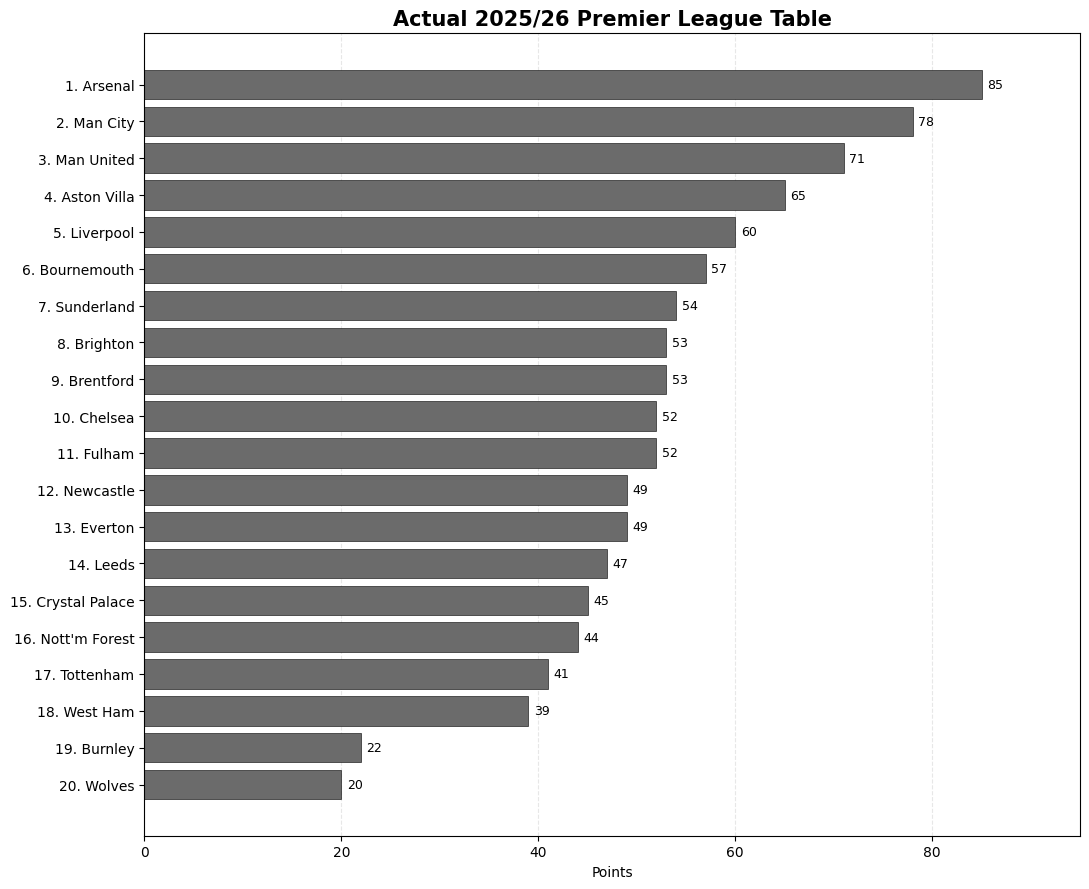

In [248]:
plot_league_table_points(
    league_table = table_2526,
    position_column = "Position",
    points_column = "Points",
    title = "Actual 2025/26 Premier League Table",
    colour = "#6B6B6B",
    filename = "Actual 2025-26 League Table.png",
    decimal_places = 0
)

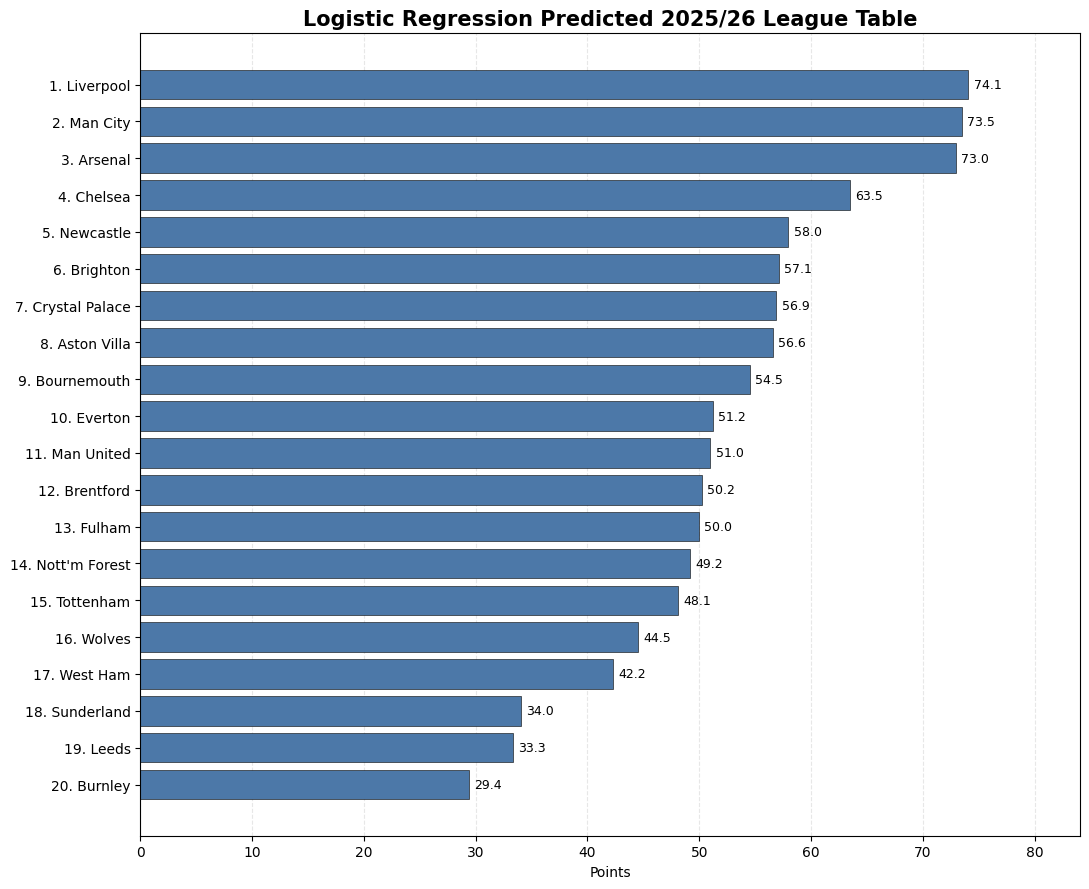

In [249]:
plot_league_table_points(
    league_table = predicted_2526_table,
    position_column = "PredictedPosition",
    points_column = "ExpectedPoints",
    title = f"{selected_ml_model_name} Predicted 2025/26 League Table",
    colour = "#4C78A8",
    filename = "Machine Learning Predicted League Table.png",
    decimal_places = 1
)

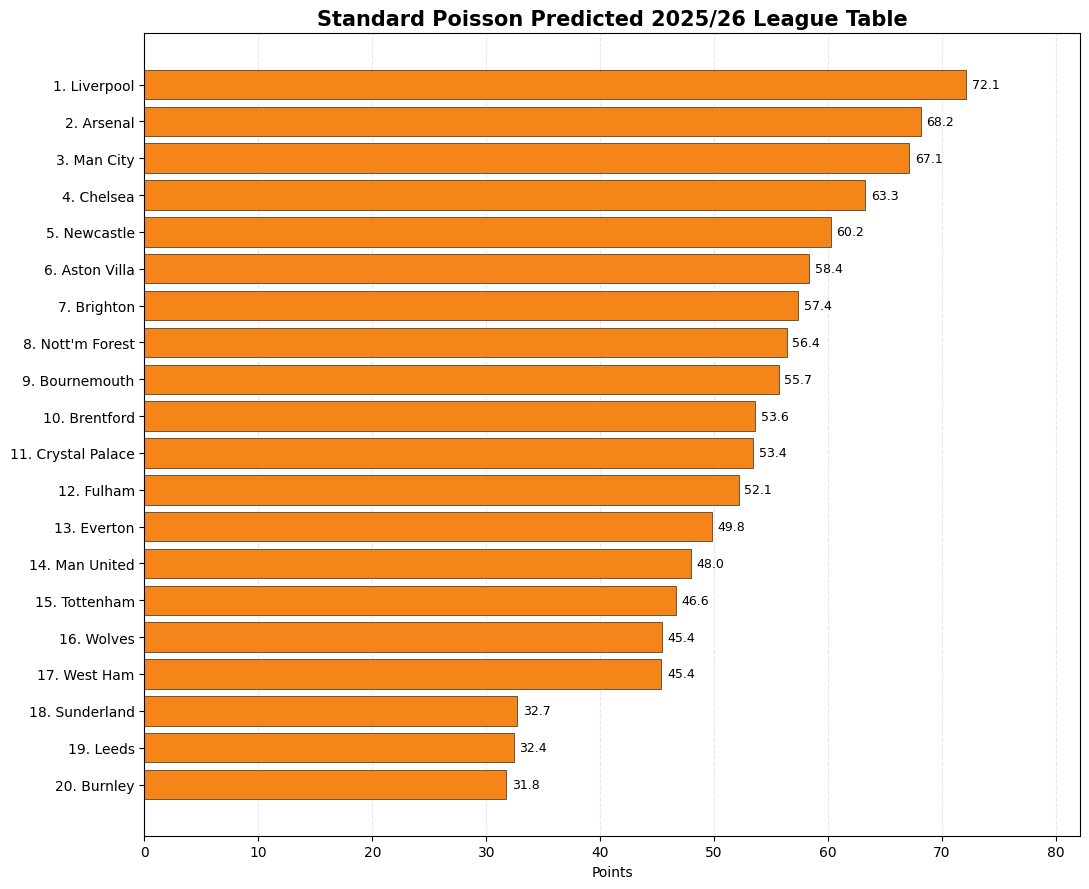

In [250]:
plot_league_table_points(
    league_table=poisson_predicted_table,
    position_column = "PredictedPosition",
    points_column = "ExpectedPoints",
    title = "Standard Poisson Predicted 2025/26 League Table",
    colour = "#F58518",
    filename = "Poisson Predicted League Table.png",
    decimal_places = 1
)

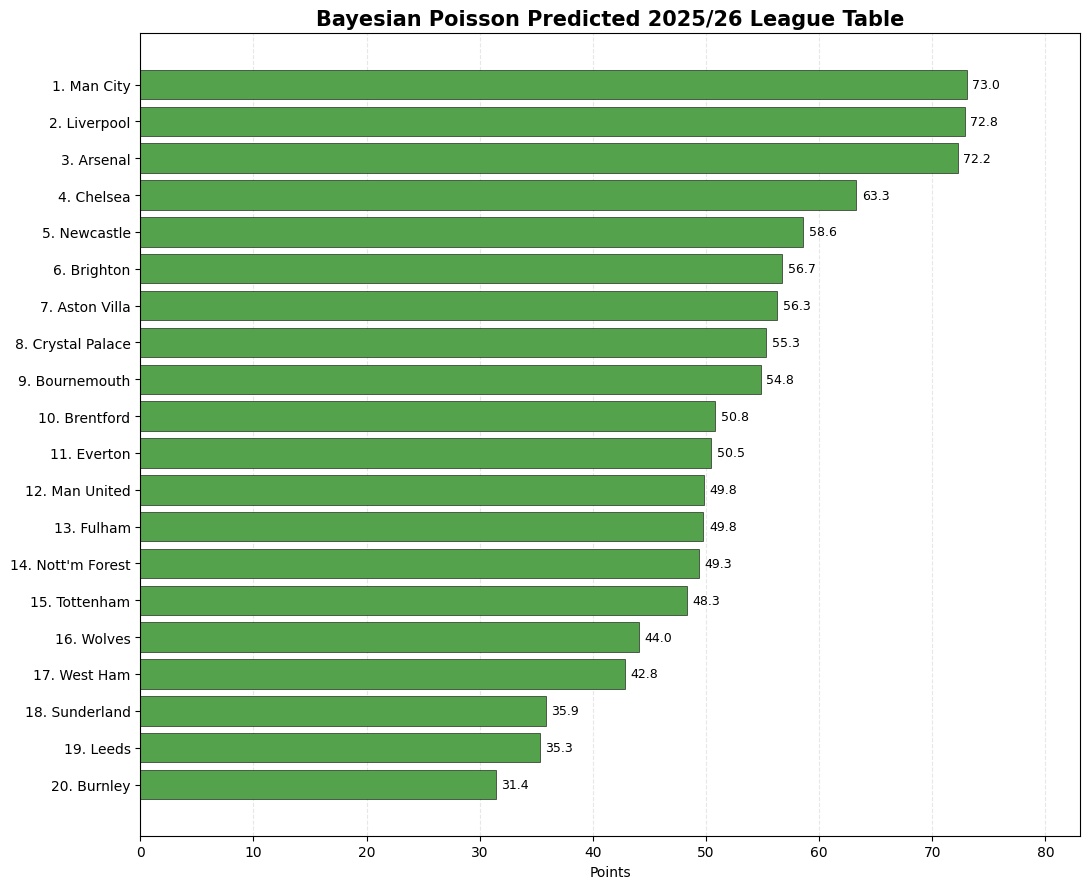

In [251]:
plot_league_table_points(
    league_table = bayesian_predicted_table,
    position_column = "PredictedPosition",
    points_column = "ExpectedPoints",
    title = "Bayesian Poisson Predicted 2025/26 League Table",
    colour = "#54A24B",
    filename = "Bayesian Predicted League Table.png",
    decimal_places = 1
)

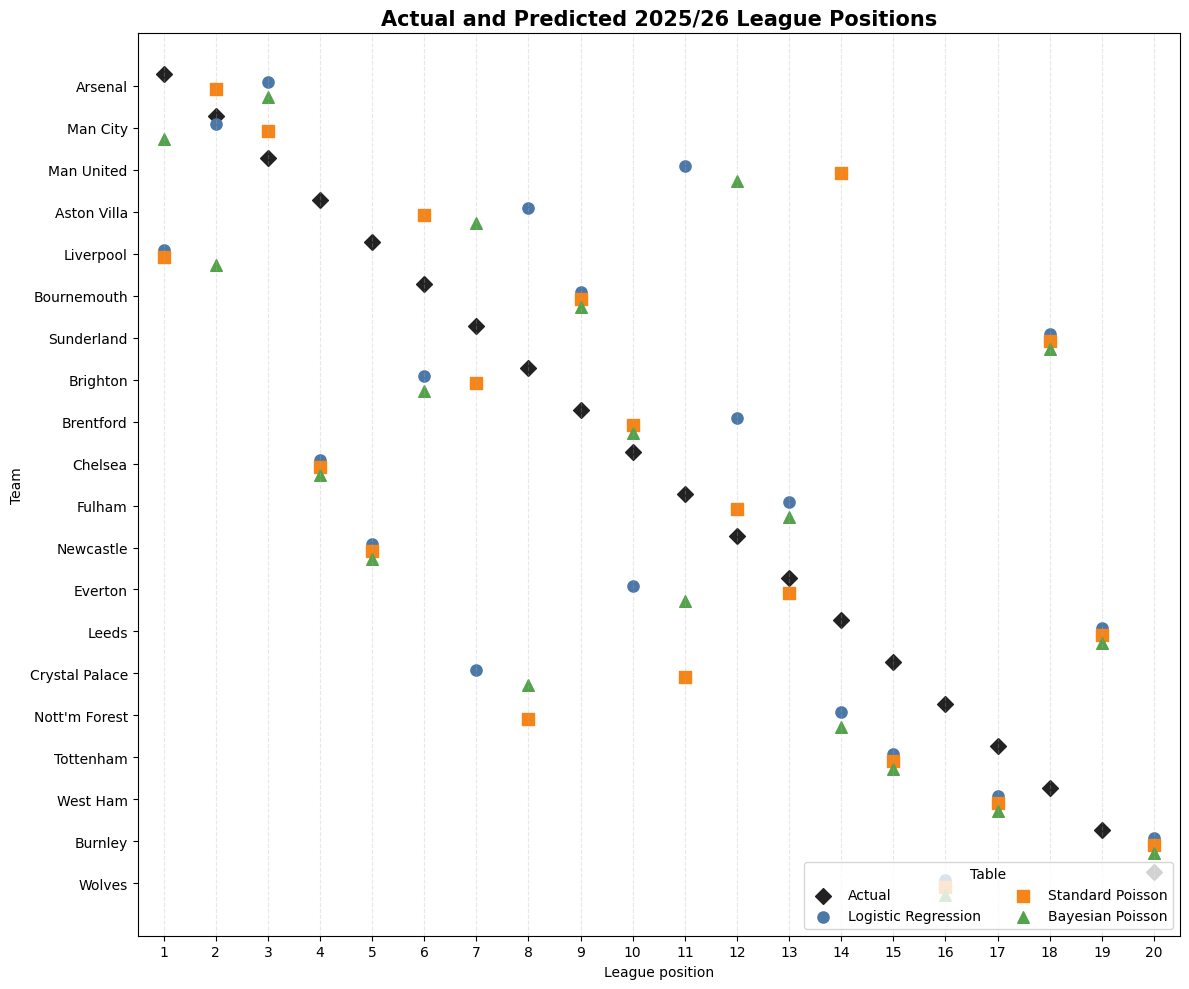

In [252]:
#comparison of actual and predicted league positions

position_plot_data = (
    final_team_comparison
    .sort_values("ActualPosition").reset_index(drop=True)
)

y_positions = np.arange(len(position_plot_data))

fig, ax = plt.subplots(figsize=(12, 10))
ax.scatter(
    position_plot_data["ActualPosition"],
    y_positions - 0.27,
    label = "Actual",
    color = "#222222",
    marker = "D",
    s = 65
)

ax.scatter(
    position_plot_data["MLPredictedPosition"],
    y_positions - 0.09,
    label = "Logistic Regression",
    color = "#4C78A8",
    marker = "o",
    s = 65
)

ax.scatter(
    position_plot_data["PoissonPredictedPosition"],
    y_positions + 0.09,
    label = "Standard Poisson",
    color = "#F58518",
    marker = "s",
    s = 65
)

ax.scatter(
    position_plot_data["BayesianPredictedPosition"],
    y_positions + 0.27,
    label = "Bayesian Poisson",
    color = "#54A24B",
    marker = "^",
    s = 70
)

ax.set_yticks(y_positions)
ax.set_yticklabels(position_plot_data["Team"])
ax.set_xticks(range(1, 21))
ax.set_xlim(0.5, 20.5)
ax.invert_yaxis()
ax.set_title(
    "Actual and Predicted 2025/26 League Positions",
    fontsize = 15, fontweight = "bold"
)
ax.set_xlabel("League position")
ax.set_ylabel("Team")
ax.grid(axis = "x", linestyle = "--", alpha = 0.3)
ax.legend(title = "Table", ncol = 2, loc = "lower right")
plt.tight_layout()

plt.savefig(
    "Actual and Predicted League Positions.png",
    dpi = 300, bbox_inches = "tight"
)
plt.show()

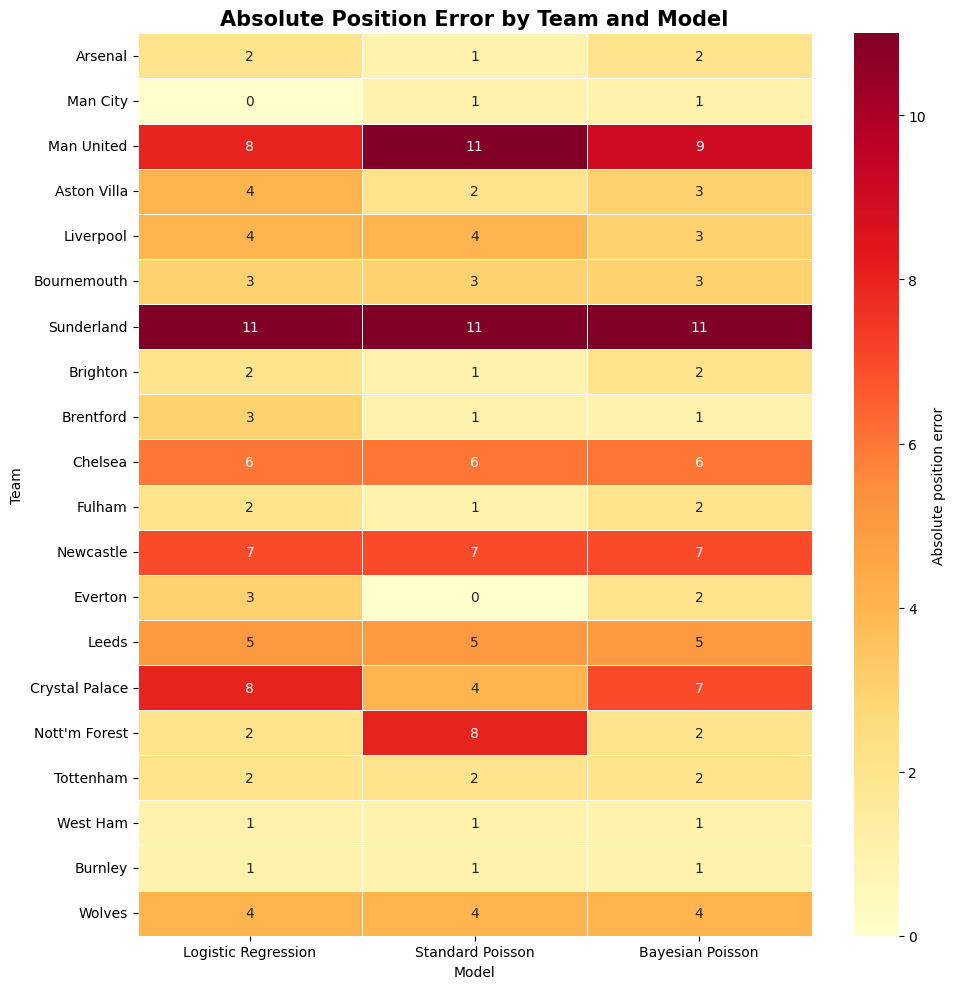

In [253]:
#team level position errors for each model

position_error_data = (
    final_team_comparison
    .set_index("Team")[
        ["MLPositionError", "PoissonPositionError", "BayesianPositionError"]
    ].rename(columns={
        "MLPositionError": "Logistic Regression",
        "PoissonPositionError": "Standard Poisson",
        "BayesianPositionError": "Bayesian Poisson"
    })
)

plt.figure(figsize = (10, 10))

sns.heatmap(
    position_error_data,
    annot = True,
    fmt = ".0f",
    cmap = "YlOrRd",
    linewidths = 0.5,
    vmin = 0,
    cbar_kws = {
        "label": "Absolute position error"
    }
)

plt.title(
    "Absolute Position Error by Team and Model",
    fontsize = 15, fontweight = "bold"
)

plt.xlabel("Model")
plt.ylabel("Team")
plt.tight_layout()
plt.savefig(
    "Team Position Error Heatmap.png",
    dpi = 300, bbox_inches = "tight"
)
plt.show()

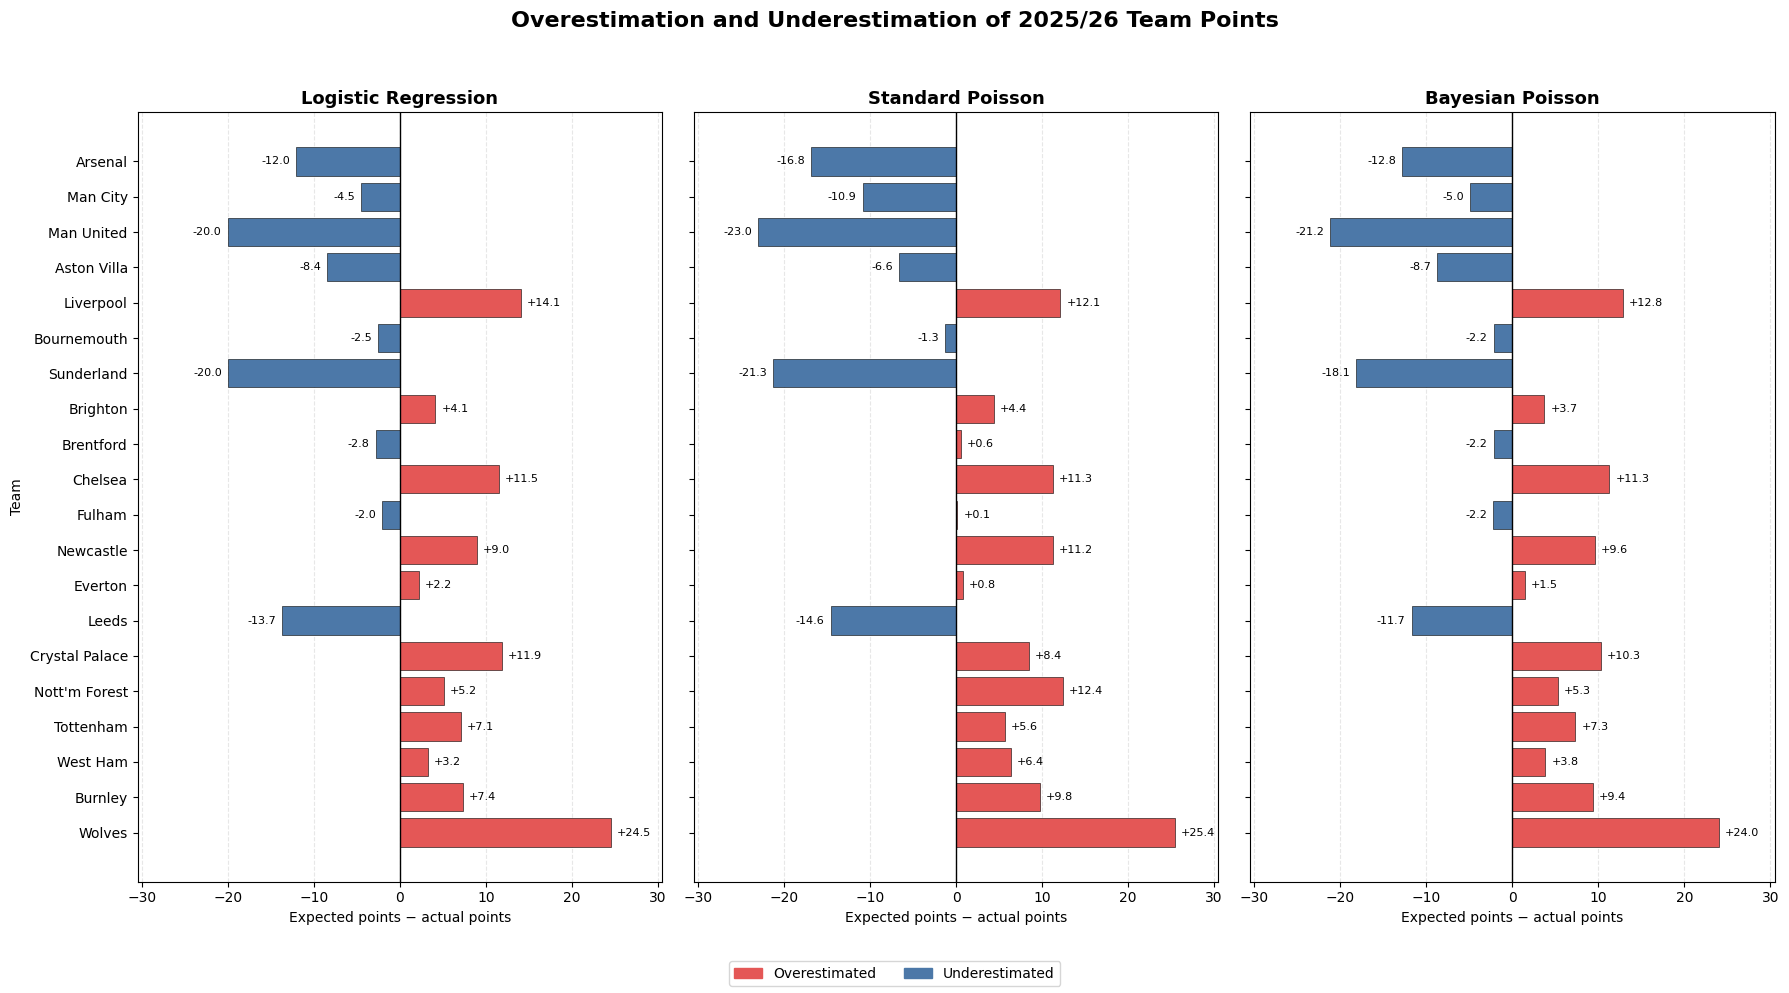

In [254]:
#compare expected and actual points for every team

points_error_plot_data = (
    final_team_comparison
    .sort_values("ActualPosition")
    .reset_index(drop=True)
    .copy()
)

#calculate signed points errors
points_error_plot_data["MLPointsError"] = (
    points_error_plot_data["MLExpectedPoints"]
    - points_error_plot_data["ActualPoints"]
)

points_error_plot_data["PoissonPointsError"] = (
    points_error_plot_data["PoissonExpectedPoints"]
    - points_error_plot_data["ActualPoints"]
)

points_error_plot_data["BayesianPointsError"] = (
    points_error_plot_data["BayesianExpectedPoints"]
    - points_error_plot_data["ActualPoints"]
)

model_errors = [
    ("MLPointsError", selected_ml_model_name),
    ("PoissonPointsError", "Standard Poisson"),
    ("BayesianPointsError", "Bayesian Poisson")
]

#use the same horizontal scale for all three models
all_errors = points_error_plot_data[
    [
        "MLPointsError",
        "PoissonPointsError",
        "BayesianPointsError"
    ]
].to_numpy()

maximum_error = np.abs(all_errors).max() * 1.20

y_positions = np.arange(
    len(points_error_plot_data)
)

fig, axes = plt.subplots(
    1,
    3,
    figsize = (18, 10),
    sharey = True,
    sharex = True
)

for ax, (error_column, model_name) in zip(
    axes,
    model_errors
):

    errors = points_error_plot_data[error_column]

    colours = [
        "#E45756" if error > 0 else "#4C78A8"
        for error in errors
    ]

    bars = ax.barh(
        y_positions,
        errors,
        color = colours,
        edgecolor = "black",
        linewidth = 0.4
    )

    ax.axvline(0, color = "black", linewidth = 1)

    #add signed error values
    for bar, value in zip(bars, errors):

        horizontal_position = (
            value + 0.7 if value >= 0
            else value - 0.7
        )

        alignment = (
            "left" if value >= 0
            else "right"
        )

        ax.text(
            horizontal_position,
            bar.get_y() + bar.get_height() / 2,
            f"{value:+.1f}",
            va = "center",
            ha = alignment,
            fontsize = 8
        )

    ax.set_title(
        model_name,
        fontsize=13,
        fontweight="bold"
    )

    ax.set_xlabel(
        "Expected points − actual points"
    )

    ax.set_xlim(
        -maximum_error,
        maximum_error
    )

    ax.grid(axis = "x", linestyle = "--", alpha = 0.3)

    ax.set_axisbelow(True)

axes[0].set_yticks(y_positions)

axes[0].set_yticklabels(
    points_error_plot_data["Team"]
)

axes[0].set_ylabel("Team")
axes[0].invert_yaxis()

fig.suptitle(
    "Overestimation and Underestimation of 2025/26 Team Points",
    fontsize = 16, fontweight = "bold"
)

#explain the colours
legend_handles = [
    plt.Rectangle(
        (0, 0), 1, 1,
        color = "#E45756",
        label = "Overestimated"
    ),
    plt.Rectangle(
        (0, 0), 1, 1,
        color = "#4C78A8",
        label = "Underestimated"
    )
]

fig.legend(
    handles = legend_handles, loc = "lower center", ncol = 2
)

plt.tight_layout(rect = [0, 0.05, 1, 0.95])
plt.savefig(
    "Team Points Prediction Errors.png",
    dpi = 300, bbox_inches = "tight"
    )
plt.show()

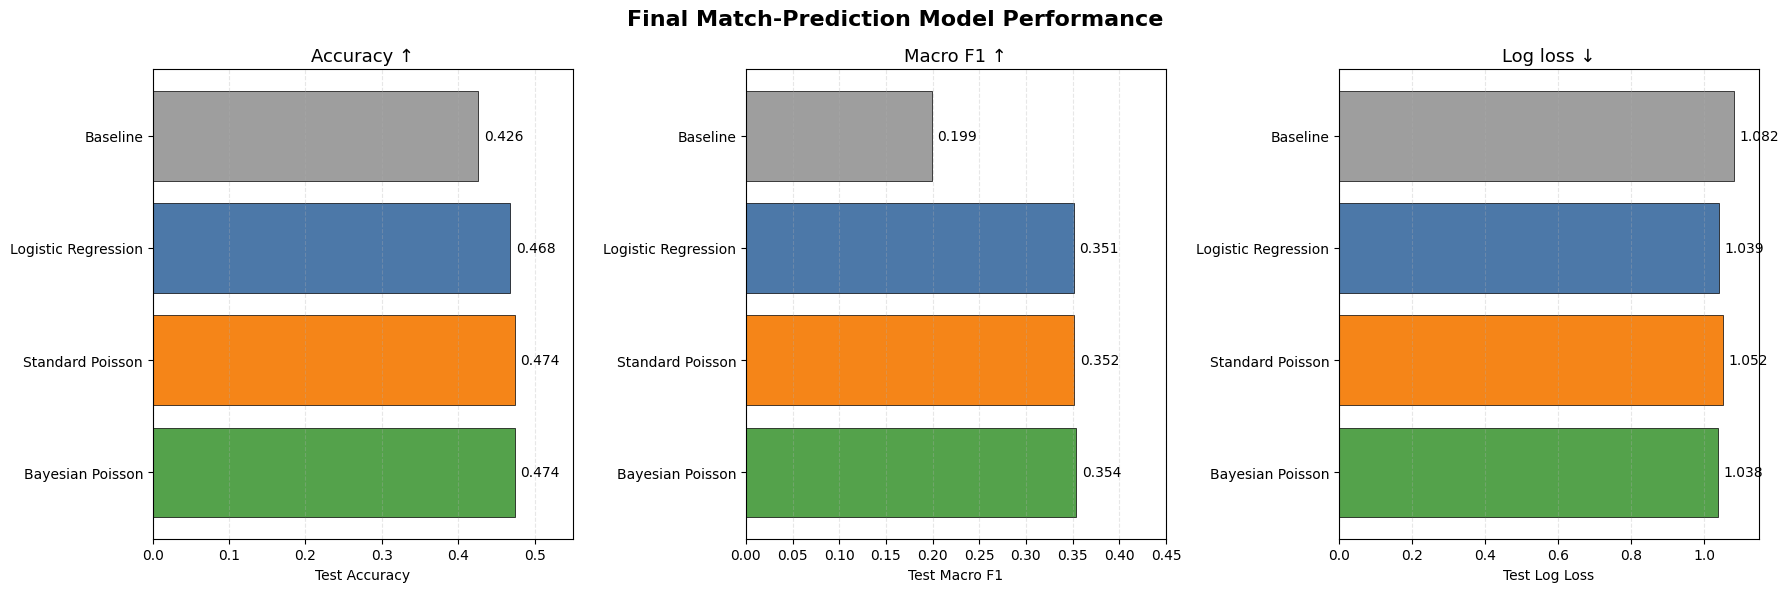

In [255]:
#visual comparison of final match prediction performance

model_colours = {
    "Baseline": "#9E9E9E",
    "Logistic Regression": "#4C78A8",
    "Standard Poisson": "#F58518",
    "Bayesian Poisson": "#54A24B"
}

comparison_metrics = [
    ("Test Accuracy", "Accuracy ↑", 0.55),
    ("Test Macro F1", "Macro F1 ↑", 0.45),
    ("Test Log Loss", "Log loss ↓", 1.15)
]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, (metric, title, maximum) in zip(
    axes, comparison_metrics
):

    models = final_match_model_comparison["Model"]
    values = final_match_model_comparison[metric]

    colours = [
        model_colours[model] for model in models
    ]

    bars = ax.barh(
        models, values, color = colours, edgecolor="black", linewidth=0.5
    )

    ax.bar_label(
        bars, fmt="%.3f", padding=4, fontsize=10
    )

    ax.set_title(title, fontsize=13)
    ax.set_xlabel(metric)
    ax.set_ylabel("")
    ax.set_xlim(0, maximum)
    ax.grid(axis="x", linestyle="--", alpha=0.3)
    ax.invert_yaxis()

fig.suptitle(
    "Final Match-Prediction Model Performance", fontsize=16, fontweight="bold"
)

plt.tight_layout()
plt.savefig(
    "Final Match Model Performance.png",
    dpi=300, bbox_inches="tight"
    )
plt.show()

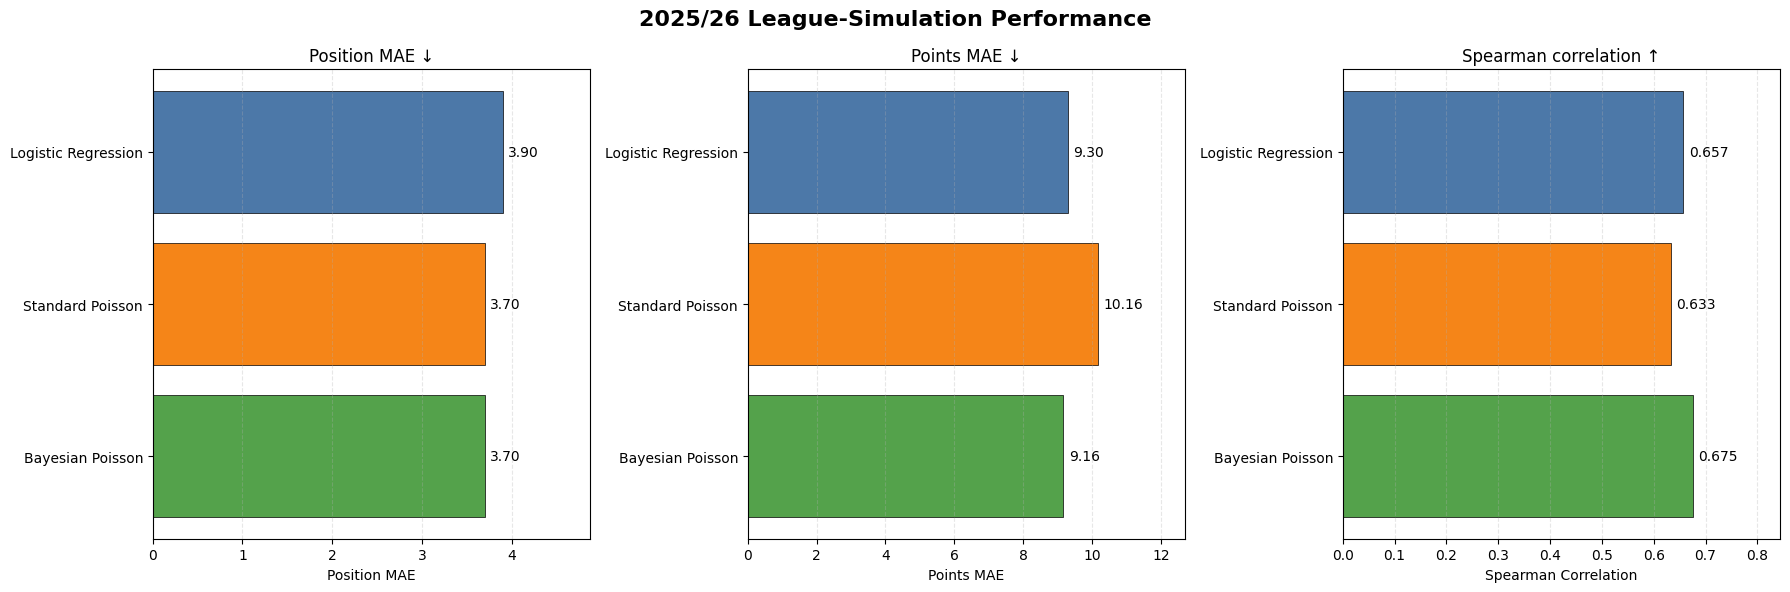

In [256]:
#visual comparison of league simulation performance

simulation_colours = {
    "Logistic Regression": "#4C78A8",
    "Standard Poisson": "#F58518",
    "Bayesian Poisson": "#54A24B"
}

simulation_metrics = [
    ("Position MAE", "Position MAE ↓", "%.2f"),
    ("Points MAE", "Points MAE ↓", "%.2f"),
    ("Spearman Correlation", "Spearman correlation ↑", "%.3f")
]

fig, axes = plt.subplots(1, 3, figsize = (18, 6))

for ax, (metric, title, number_format) in zip(
    axes,
    simulation_metrics
):

    models = final_simulation_comparison["Model"]
    values = final_simulation_comparison[metric]

    colours = [
        simulation_colours[model] for model in models
    ]

    bars = ax.barh(
        models,
        values,
        color = colours,
        edgecolor = "black",
        linewidth = 0.5
    )

    ax.bar_label(
        bars, fmt = number_format, padding = 4
    )

    ax.set_title(title)
    ax.set_xlabel(metric)
    ax.set_ylabel("")
    ax.set_xlim(0, values.max() * 1.25)
    ax.grid(axis="x", linestyle="--", alpha=0.3)
    ax.invert_yaxis()

fig.suptitle(
    "2025/26 League-Simulation Performance",
    fontsize = 16, fontweight = "bold"
)
plt.tight_layout()
plt.savefig(
    "League Simulation Model Performance.png",
    dpi = 300, bbox_inches = "tight"
)
plt.show()

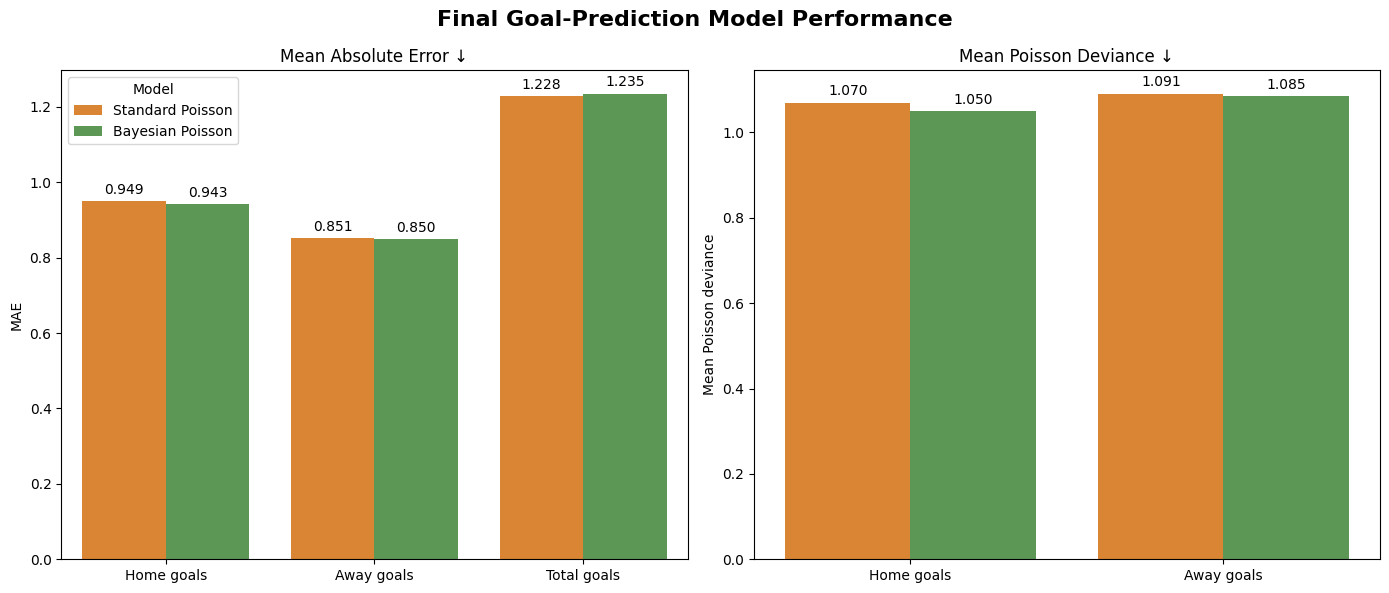

In [257]:
#visual comparison of final goal-prediction performance

goal_model_colours = {
    "Standard Poisson": "#F58518",
    "Bayesian Poisson": "#54A24B"
}

mae_data = final_goal_model_comparison.melt(
    id_vars = "Model",
    value_vars = [
        "Home Goal MAE",
        "Away Goal MAE",
        "Total Goal MAE"
    ],
    var_name = "Metric",
    value_name = "Value"
)

mae_data["Metric"] = mae_data["Metric"].replace({
    "Home Goal MAE": "Home goals",
    "Away Goal MAE": "Away goals",
    "Total Goal MAE": "Total goals"
})

deviance_data = final_goal_model_comparison.melt(
    id_vars = "Model",
    value_vars = [
        "Home Goal Deviance",
        "Away Goal Deviance"
    ],
    var_name = "Metric",
    value_name = "Value"
)

deviance_data["Metric"] = deviance_data["Metric"].replace({
    "Home Goal Deviance": "Home goals",
    "Away Goal Deviance": "Away goals"
})

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.barplot(
    data = mae_data,
    x = "Metric",
    y = "Value",
    hue = "Model",
    palette = goal_model_colours,
    ax=axes[0]
)

axes[0].set_title("Mean Absolute Error ↓")
axes[0].set_xlabel("")
axes[0].set_ylabel("MAE")
axes[0].legend(title="Model")

for container in axes[0].containers:
    axes[0].bar_label(
        container, fmt = "%.3f", padding=3
    )

sns.barplot(
    data=deviance_data,
    x = "Metric",
    y = "Value",
    hue = "Model",
    palette = goal_model_colours,
    ax=axes[1],
    legend=False
)

axes[1].set_title("Mean Poisson Deviance ↓")
axes[1].set_xlabel("")
axes[1].set_ylabel("Mean Poisson deviance")

for container in axes[1].containers:
    axes[1].bar_label(
        container, fmt = "%.3f", padding = 3
    )

fig.suptitle(
    "Final Goal-Prediction Model Performance",
    fontsize = 16, fontweight = "bold"
)
plt.tight_layout()
plt.savefig(
    "Final Goal Model Performance.png",
    dpi = 300, bbox_inches = "tight"
)
plt.show()

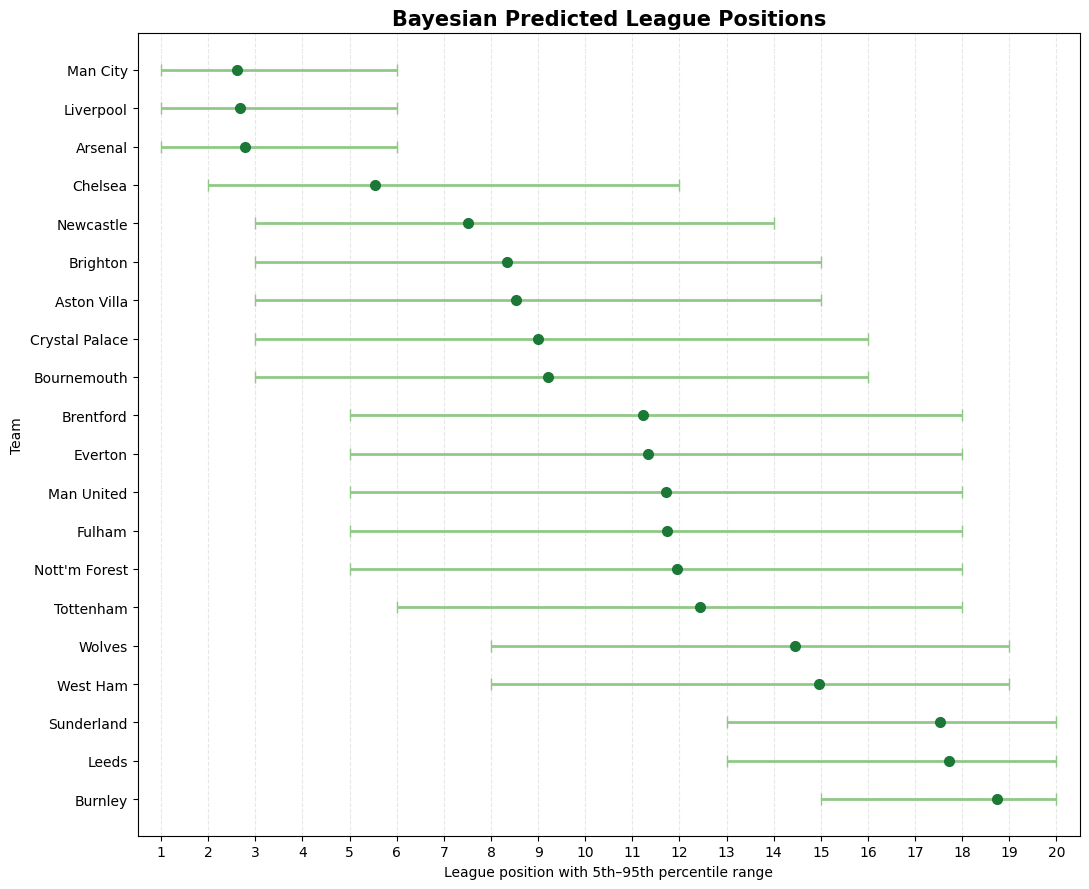

In [258]:
#bayesian predicted positions and uncertainty ranges

bayesian_position_plot = (
    bayesian_predicted_table
    .sort_values("AveragePosition")
    .reset_index(drop=True)
)

average_positions = (
    bayesian_position_plot["AveragePosition"]
)

lower_errors = (
    average_positions
    - bayesian_position_plot["Position5thPercentile"]
)

upper_errors = (
    bayesian_position_plot["Position95thPercentile"]
    - average_positions
)

position_errors = np.vstack([
    lower_errors,
    upper_errors
])

y_positions = np.arange(
    len(bayesian_position_plot)
)

fig, ax = plt.subplots(figsize=(11, 9))

ax.errorbar(
    average_positions,
    y_positions,
    xerr = position_errors,
    fmt = "o",
    color = "#1B7837",
    ecolor = "#90C987",
    markersize = 7,
    linewidth = 2,
    capsize = 4
)

ax.set_yticks(y_positions)
ax.set_yticklabels(bayesian_position_plot["Team"])
ax.set_xticks(range(1, 21))
ax.set_xlim(0.5, 20.5)
ax.invert_yaxis()
ax.set_title(
    "Bayesian Predicted League Positions",
    fontsize = 15, fontweight = "bold"
)
ax.set_xlabel("League position with 5th–95th percentile range")
ax.set_ylabel("Team")
ax.grid(axis = "x", linestyle = "--", alpha = 0.3)
plt.tight_layout()
plt.savefig(
    "Bayesian Position Uncertainty.png",
    dpi = 300, bbox_inches = "tight"
)
plt.show()

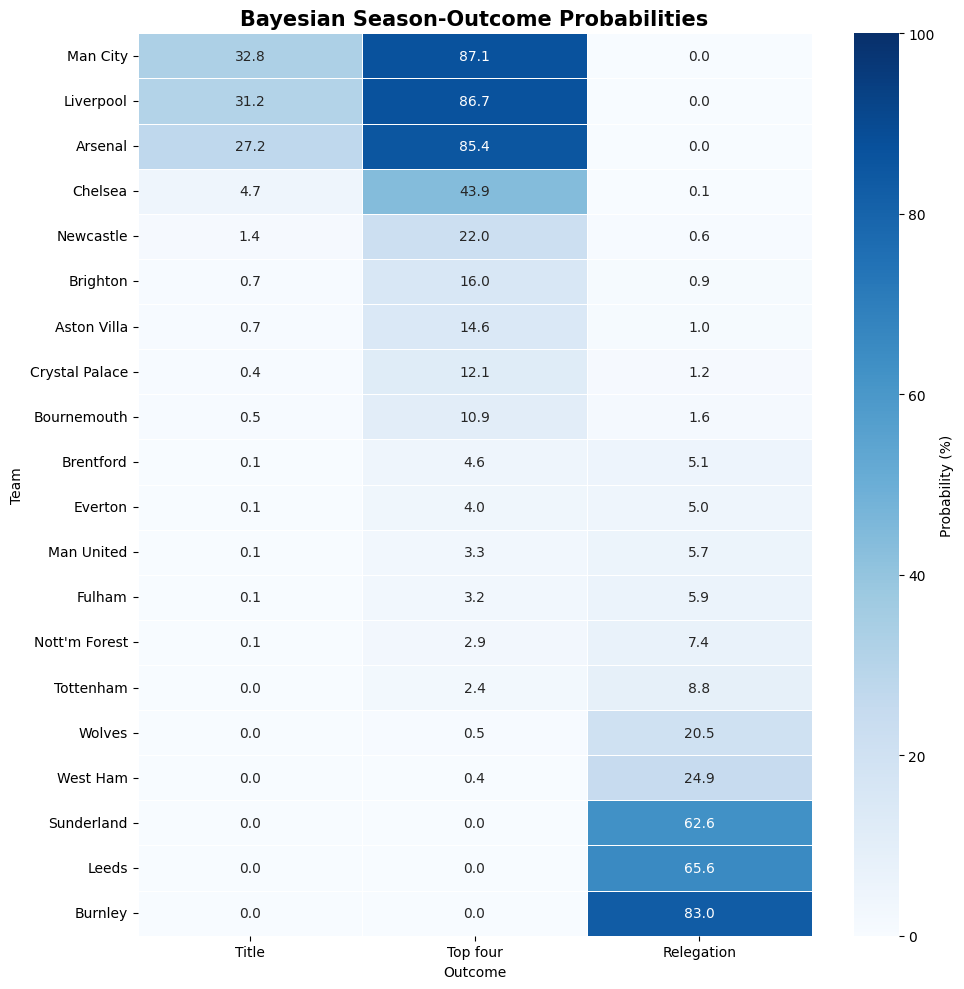

In [259]:
#bayesian title, top-four and relegation probabilities

bayesian_probability_plot = (
    bayesian_predicted_table
    .sort_values("AveragePosition")
    .set_index("Team")[
        ["TitleProbability", "Top4Probability", "RelegationProbability"]
    ].rename(columns={
        "TitleProbability": "Title",
        "Top4Probability": "Top four",
        "RelegationProbability": "Relegation"
    })
)

plt.figure(figsize=(10, 10))
sns.heatmap(
    bayesian_probability_plot,
    annot = True,
    fmt = ".1f",
    cmap = "Blues",
    linewidths = 0.5,
    vmin = 0,
    vmax = 100,
    cbar_kws = {
        "label": "Probability (%)"
    }
)

plt.title(
    "Bayesian Season-Outcome Probabilities",
    fontsize=15, fontweight="bold"
)
plt.xlabel("Outcome")
plt.ylabel("Team")
plt.tight_layout()
plt.savefig(
    "Bayesian Season Outcome Probabilities.png",
    dpi = 300, bbox_inches = "tight"
)
plt.show()

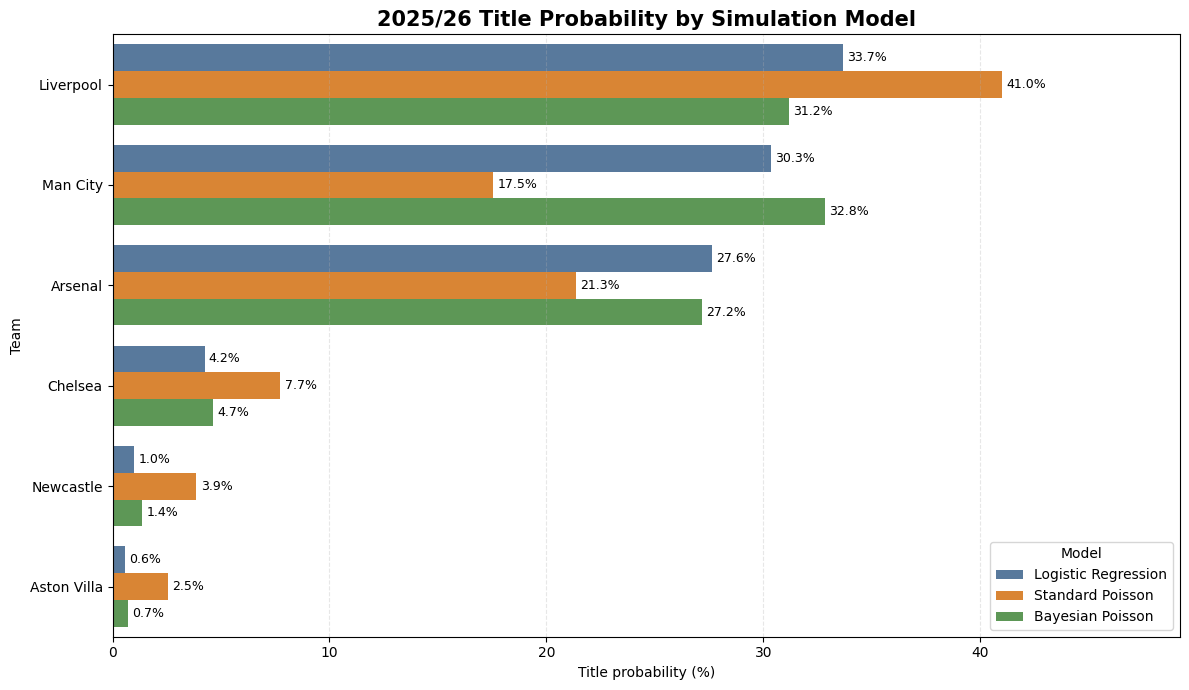

In [260]:
#compare title probabilities across the three simulation models

title_probability_comparison = (
    simulation_summary[
        ["Team", "TitleProbability"]
    ].rename(columns={
        "TitleProbability": selected_ml_model_name
    }).merge(
        poisson_simulation_summary[
            ["Team", "TitleProbability"]
        ].rename(columns={
            "TitleProbability": "Standard Poisson"
        }), on="Team", how = "inner"
    ).merge(
        bayesian_simulation_summary[
            ["Team", "TitleProbability"]
        ].rename(columns={
            "TitleProbability": "Bayesian Poisson"
        }), on = "Team", how = "inner"
    )
)

#select the six teams with the highest probability in any model
model_columns = [
    selected_ml_model_name,
    "Standard Poisson",
    "Bayesian Poisson"
]

title_probability_comparison["HighestProbability"] = (
    title_probability_comparison[model_columns].max(axis=1)
)

title_contenders = (
    title_probability_comparison
    .nlargest(6, "HighestProbability")
    .sort_values("HighestProbability", ascending=False)
)

#convert the table into long format for plotting
title_contenders_long = title_contenders.melt(
    id_vars = "Team",
    value_vars = model_columns,
    var_name = "Model",
    value_name = "TitleProbability"
)

model_colours = {
    selected_ml_model_name: "#4C78A8",
    "Standard Poisson": "#F58518",
    "Bayesian Poisson": "#54A24B"
}

plt.figure(figsize=(12, 7))

ax = sns.barplot(
    data = title_contenders_long,
    x = "TitleProbability",
    y = "Team",
    hue = "Model",
    order = title_contenders["Team"],
    palette = model_colours
)

#add percentage labels to non zero bars
for container in ax.containers:

    labels = [
        f"{bar.get_width():.1f}%"
        if bar.get_width() > 0 else ""
        for bar in container
    ]

    ax.bar_label(
        container,
        labels = labels,
        padding = 3,
        fontsize = 9
    )

maximum_probability = (
    title_contenders_long["TitleProbability"].max()
)

ax.set_xlim(0, maximum_probability * 1.20)

plt.title(
    "2025/26 Title Probability by Simulation Model",
    fontsize = 15, fontweight = "bold"
)
plt.xlabel("Title probability (%)")
plt.ylabel("Team")
plt.legend(title = "Model")
plt.grid(axis = "x", linestyle = "--", alpha = 0.3)
plt.tight_layout()
plt.savefig(
    "Title Probability Model Comparison.png",
    dpi = 300, bbox_inches = "tight"
)
plt.show()

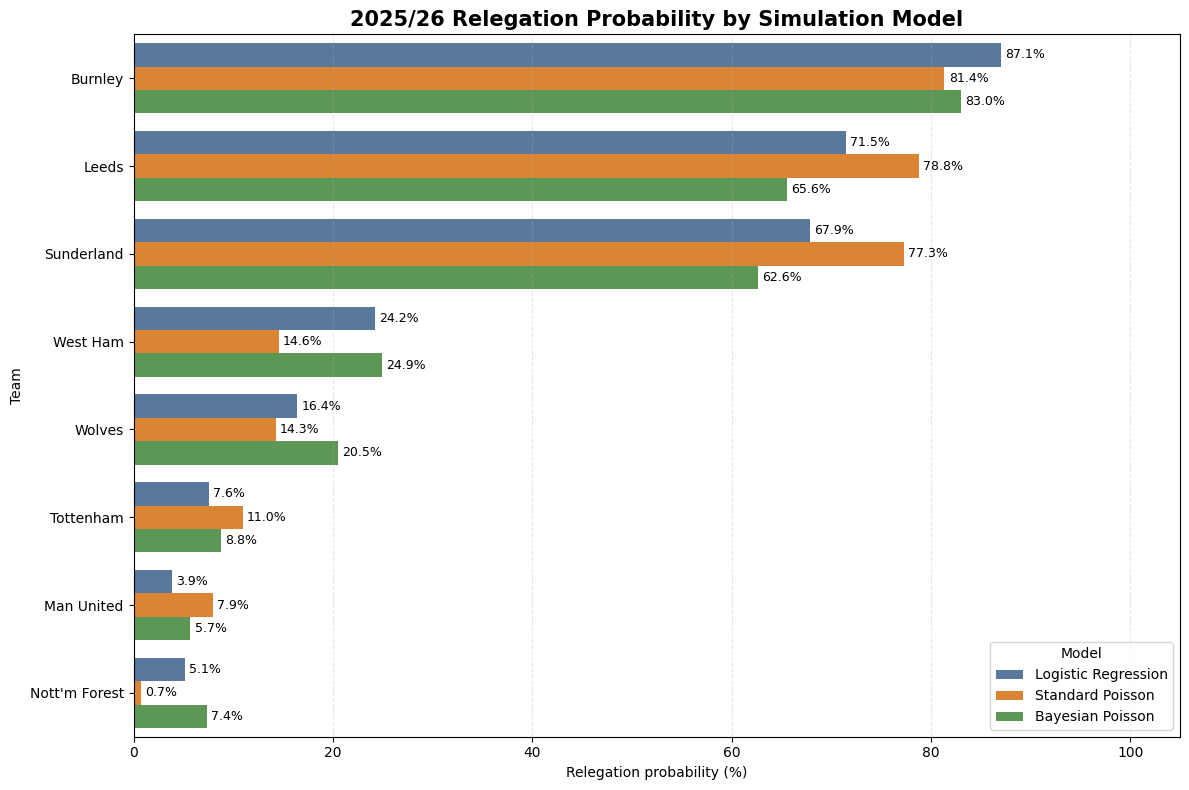

In [261]:
#compare relegation probabilities across simulation models

relegation_probability_comparison = (
    simulation_summary[
        ["Team", "RelegationProbability"]
    ].rename(columns = {
        "RelegationProbability": selected_ml_model_name
    }).merge(
        poisson_simulation_summary[
            ["Team", "RelegationProbability"]
        ].rename(columns={
            "RelegationProbability": "Standard Poisson"
        }), on = "Team", how = "inner"
    ).merge(
        bayesian_simulation_summary[
            ["Team", "RelegationProbability"]
        ].rename(columns = {
            "RelegationProbability": "Bayesian Poisson"
        }), on = "Team", how = "inner"
    )
)

model_columns = [
    selected_ml_model_name,
    "Standard Poisson",
    "Bayesian Poisson"
]

#find each team's highest relegation probability
relegation_probability_comparison["HighestProbability"] = (
    relegation_probability_comparison[
        model_columns
    ].max(axis = 1)
)

#select the eight teams with the highest risk in any model
relegation_candidates = (
    relegation_probability_comparison
    .nlargest(8, "HighestProbability")
    .sort_values("HighestProbability", ascending = False)
)

#convert to long format for plotting
relegation_candidates_long = (
    relegation_candidates.melt(
        id_vars = "Team",
        value_vars = model_columns,
        var_name = "Model",
        value_name = "RelegationProbability"
    )
)

model_colours = {
    selected_ml_model_name: "#4C78A8",
    "Standard Poisson": "#F58518",
    "Bayesian Poisson": "#54A24B"
}

plt.figure(figsize = (12, 8))

ax = sns.barplot(
    data = relegation_candidates_long,
    x = "RelegationProbability",
    y = "Team",
    hue = "Model",
    order = relegation_candidates["Team"],
    palette = model_colours
)

#add percentage labels to non-zero bars
for container in ax.containers:

    labels = [
        f"{bar.get_width():.1f}%"
        if bar.get_width() > 0 else ""
        for bar in container
    ]

    ax.bar_label(
        container, labels = labels, padding = 3, fontsize = 9
    )

ax.set_xlim(0, 105)
plt.title(
    "2025/26 Relegation Probability by Simulation Model",
    fontsize = 15, fontweight = "bold"
)
plt.xlabel("Relegation probability (%)")
plt.ylabel("Team")
plt.legend(title = "Model")
plt.grid(axis = "x", linestyle = "--", alpha = 0.3)
plt.tight_layout()
plt.savefig(
    "Relegation Probability Model Comparison.png",
    dpi = 300, bbox_inches = "tight"
)
plt.show()

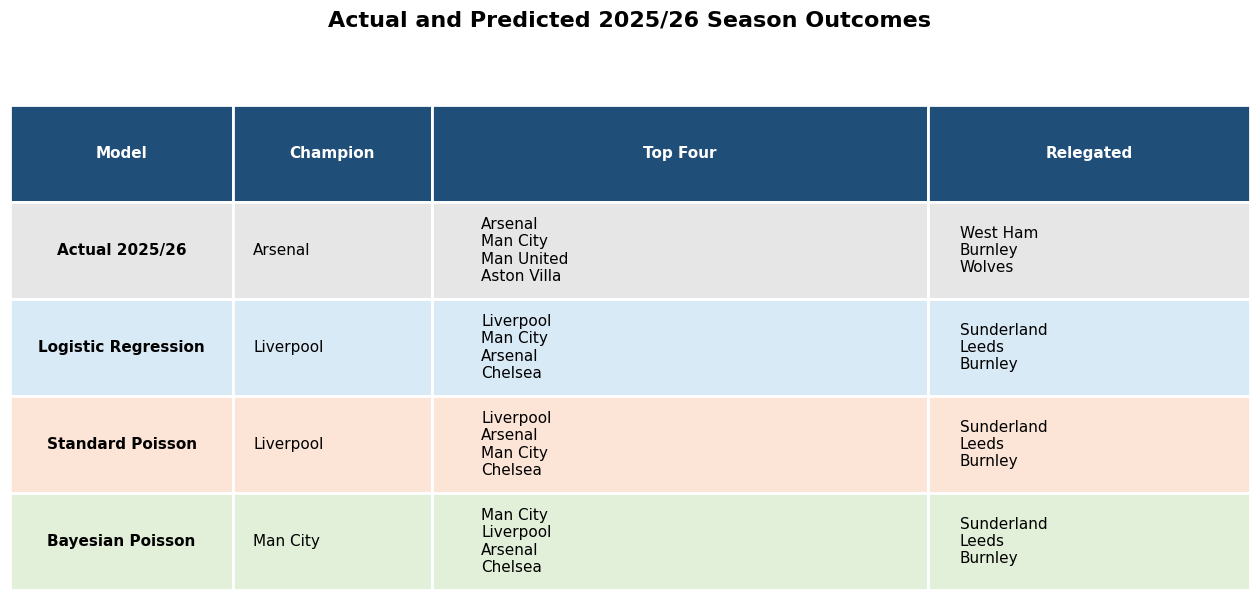

In [262]:
#prepare ordered team lists

actual_table_order = table_2526.sort_values("Position")

ml_table_order = predicted_2526_table.sort_values("PredictedPosition")

poisson_table_order = poisson_predicted_table.sort_values("PredictedPosition")

bayesian_table_order = bayesian_predicted_table.sort_values("PredictedPosition")

#create the comparison table

outcome_names_table = pd.DataFrame({
    "Model": [
        "Actual 2025/26",
        selected_ml_model_name,
        "Standard Poisson",
        "Bayesian Poisson"
    ],
    "Champion": [
        actual_table_order.iloc[0]["Team"],
        predicted_champion,
        poisson_predicted_champion,
        bayesian_predicted_champion
    ],
    "Top Four": [
        "\n".join(actual_table_order.head(4)["Team"]),
        "\n".join(ml_table_order.head(4)["Team"]),
        "\n".join(poisson_table_order.head(4)["Team"]),
        "\n".join(bayesian_table_order.head(4)["Team"])
    ],
    "Relegated": [
        "\n".join(actual_table_order.tail(3)["Team"]),
        "\n".join(ml_table_order.tail(3)["Team"]),
        "\n".join(poisson_table_order.tail(3)["Team"]),
        "\n".join(bayesian_table_order.tail(3)["Team"])
    ]
})

#save the outcome comparison as a table

fig, ax = plt.subplots(figsize = (16, 7))

ax.axis("off")

png_table = ax.table(
    cellText = outcome_names_table.values,
    colLabels = outcome_names_table.columns,
    cellLoc = "left",
    colLoc = "center",
    colWidths = [0.18, 0.16, 0.40, 0.26],
    bbox = [0, 0, 1, 0.90]
)

png_table.auto_set_font_size(False)
png_table.set_fontsize(11)

row_colours = [
    "#E7E6E6",
    "#D9EAF7",
    "#FCE4D6",
    "#E2F0D9"
]

for (row, column), cell in png_table.get_celld().items():

    cell.set_edgecolor("white")
    cell.set_linewidth(2)

    if row == 0:
        cell.set_facecolor("#1F4E78")
        cell.set_text_props(
            color="white",
            weight="bold",
            ha="center"
        )

    else:
        cell.set_facecolor(
            row_colours[row - 1]
        )

        if column == 0:
            cell.set_text_props(
                weight = "bold",
                ha = "center"
            )

        else:
            cell.set_text_props(
                ha="left"
            )

ax.set_title(
    "Actual and Predicted 2025/26 Season Outcomes",
    fontsize = 16, fontweight = "bold", pad = 18
)

plt.savefig(
    "Actual and Predicted Season Outcomes.png",
    dpi = 300, bbox_inches = "tight", facecolor = "white"
)
plt.show()